# RQ4: геометрия E5, CE и CE + SupCon

**Три сохранённые модели:** `intfloat/e5-small-v2`, `pineee/e5-small-v2-hivetrace-finetune-CE` и `pineee/e5-small-v2-hivetrace-finetune-CE-SupCon` на **одних и тех же отложенных текстах**. Сначала сравниваем base и CE+SupCon, затем добавляем CE-контроль. Все модели заморожены; анализируем последний слой, mean pooling и L2-нормированные эмбеддинги в исходных 384 измерениях.

Раздел 0 показывает сохранённые результаты RQ3 и кривые обучения. Разделы 1–6 пересчитывают геометрию до/после. Дополнительный контроль сравнивает опубликованный CE-чекпоинт на той же выборке. Раздел 7 объясняет ограничения и поддерживает реальные промежуточные чекпоинты. Раздел 8 объясняет, что ещё нужно для RQ6. Анализ головы, t-SNE и проходы по всем слоям сюда не включены.

**Colab:** загрузите этот `.ipynb` → «Среда выполнения → Сменить среду выполнения → GPU» → выполняйте сверху вниз. Для e5-small начните с T4 и `BATCH_SIZE=32`; при нехватке памяти код уменьшит batch. Если доступен L4/A100, он тоже подходит. GPU нужен для эмбеддингов, расчёт небольших матриц метрик идёт на CPU. Пакет из 500 вычислительных блоков не требует большого эксперимента: сначала выполните это сравнение. Время и расход зависят от предоставленного GPU; [Colab не гарантирует конкретные ресурсы](https://research.google.com/colaboratory/faq.html).

По умолчанию `USE_DRIVE=False`: подключение Google Drive пропускается, результаты и кэш сохраняются в `/content/guardrails_geometry_results`. Это временное хранилище среды: перед её удалением скачайте ZIP результатов последней ячейкой. Если понадобится сохранять кэш на Drive между сеансами, задайте `USE_DRIVE=True`; при ошибке подключения ноутбук продолжит работу локально. Для WildGuardMix заранее примите условия [на странице датасета](https://huggingface.co/datasets/allenai/wildguardmix); добавьте секрет Colab `HF_TOKEN` с доступом на чтение или войдите по приглашению. При использовании своего CSV задайте `DATA_SOURCE="local"`. В конце скачайте также выполненный ноутбук через «Файл → Скачать → .ipynb».

Что покрывает ноутбук:

| Требование | Реализация / результат |
|---|---|
| Isotropy proxy до/после | Средний косинус 100 000 фиксированных случайных пар и точная проверка; дополнительно спектр |
| Intrinsic dimensionality | TwoNN; отдельно PR как спектральная, а не intrinsic dimensionality |
| kNN-purity | k=5,10,20, macro и по классам, со случайным уровнем |
| Alignment / uniformity | Формулы, первоисточники и реализации; общий набор и отдельные классы |
| Косинусы safe/safe, harmful/harmful, safe/harmful | Таблица из RQ3 и новый точный расчёт, графики до/после |
| Графики геометрии | Точки всех текстов на общей PCA-плоскости, распределения косинусов, спектры, шесть метрик, внутриклассовое разнообразие |
| Связь с обучением | Train loss и компоненты, validation AUROC/TPR, batch-косинусы, LR, выбранный чекпоинт |
| Шаг и loss начала ухудшения геометрии | Пока не определяются: промежуточные веса/фиксированные эмбеддинги отсутствуют |
| RQ6: причинный эффект LLM teacher | Формулировка и дизайн контроля; human-vs-LLM эксперимент ещё не проведён |

Сохранённые выводы ячеек позволяют посмотреть выполненный расчёт. При новом запуске
они пересчитываются. В Colab используйте GPU; имеющиеся **500 вычислительных блоков**
не требуют расходовать их на повторное обучение ради сравнения двух моделей.
Для нового эксперимента по динамике/RQ6 сначала проведите один короткий пилот,
сохраняйте чекпоинты на Drive и проверьте расход блоков в интерфейсе Colab.

## 0. Что уже известно из `rq3_training`

Этот раздел работает **без GPU, моделей и доступа к Hugging Face**. Копия таблиц, конфигураций,
истории пяти прогонов и контрольные суммы исходных файлов встроены в ноутбук. Загружать ZIP
в Colab повторно не требуется. Здесь показаны **результаты прежнего обучения из архива**;
в разделах 2–6 выполняется отдельный расчёт на фиксированных входах.

Все пять вариантов обучались 2688 шагов. Остался лучший чекпоинт по validation TPR@FPR=1%,
а не веса последнего шага: CE — 2000, InfoNCE — 1344, CE+InfoNCE — 2400,
SupCon — 2400, CE+SupCon — **1400**. Сами веса в архив не включены.

Есть 134 записи train loss на прогон (каждые 20 шагов), отдельные компоненты loss,
learning rate и 15 оценок валидации. **Val loss отсутствует**; AUROC/TPR не называем val loss.
Для контрастивных вариантов есть обучающий cosine margin; для SupCon также косинусы
внутри/между классами. Это показатели меняющихся обучающих батчей, а не траектория
геометрии одной отложенной выборки. Train loss записан на одном батче, не усреднён по эпохе.

В `TRAINING.md` фраза «компоненты только в MLflow» устарела: они присутствуют в CSV.
В `LODO.md` встречается AEGIS, хотя конфиг/описание прогона указывают WildGuardMix:
происхождение train/val для downstream-проба стоит сверить с авторским скриптом.
Метрики из архива приводим как сообщённые результаты, без исправления протокола задним числом.

`pc1_share` и косинусы перенесены из конца `rq3_pure.log` с его точностью (4 знака).
Исходного `10_embedding_geometry.py` и списка ID этой оценки в архиве нет, поэтому новый
расчёт может отличаться из-за очистки/состава данных и определения метрик.
Связь опубликованной HF-ревизии с `pure-supcon-joint` нельзя доказать по названию:
до подтверждения происхождения весов шаг 1400 относится **только к архивному прогону**.

In [1]:
import json
# Встроенная копия фактических таблиц и метаданных; данные, не результаты нового запуска.
RQ3_SNAPSHOT = json.loads('{"schema": 1, "provenance": "Supplied rq3_training; geometry rounded as printed in rq3_pure.log", "geometry": [{"model": "e5-small-v2-frozen", "eval_set": "holdout", "n": 1699, "pc1_share": 0.0707, "cos_safe_harm": 0.7978, "cos_within_safe": 0.7948, "cos_within_harm": 0.8074}, {"model": "e5-small-v2-frozen", "eval_set": "ood", "n": 1500, "pc1_share": 0.0393, "cos_safe_harm": 0.7718, "cos_within_safe": 0.7671, "cos_within_harm": 0.7942}, {"model": "pure-classification", "eval_set": "holdout", "n": 1699, "pc1_share": 0.6455, "cos_safe_harm": -0.0394, "cos_within_safe": 0.6246, "cos_within_harm": 0.4038}, {"model": "pure-classification", "eval_set": "ood", "n": 1500, "pc1_share": 0.4432, "cos_safe_harm": 0.0398, "cos_within_safe": 0.4539, "cos_within_harm": 0.5739}, {"model": "pure-contrastive", "eval_set": "holdout", "n": 1699, "pc1_share": 0.203, "cos_safe_harm": 0.6217, "cos_within_safe": 0.7238, "cos_within_harm": 0.669}, {"model": "pure-contrastive", "eval_set": "ood", "n": 1500, "pc1_share": 0.1435, "cos_safe_harm": 0.7028, "cos_within_safe": 0.7698, "cos_within_harm": 0.7523}, {"model": "pure-joint", "eval_set": "holdout", "n": 1699, "pc1_share": 0.3281, "cos_safe_harm": 0.5564, "cos_within_safe": 0.7422, "cos_within_harm": 0.6506}, {"model": "pure-joint", "eval_set": "ood", "n": 1500, "pc1_share": 0.2342, "cos_safe_harm": 0.6511, "cos_within_safe": 0.7767, "cos_within_harm": 0.7379}, {"model": "pure-supcon", "eval_set": "holdout", "n": 1699, "pc1_share": 0.861, "cos_safe_harm": 0.8099, "cos_within_safe": 0.9597, "cos_within_harm": 0.9104}, {"model": "pure-supcon", "eval_set": "ood", "n": 1500, "pc1_share": 0.7119, "cos_safe_harm": 0.8294, "cos_within_safe": 0.9338, "cos_within_harm": 0.943}, {"model": "pure-supcon-joint", "eval_set": "holdout", "n": 1699, "pc1_share": 0.8176, "cos_safe_harm": 0.7851, "cos_within_safe": 0.952, "cos_within_harm": 0.8896}, {"model": "pure-supcon-joint", "eval_set": "ood", "n": 1500, "pc1_share": 0.6574, "cos_safe_harm": 0.801, "cos_within_safe": 0.9296, "cos_within_harm": 0.9192}], "triplets": [{"model": "e5-small-v2-frozen", "adversarial_contrast": 0.1, "all": 29.4, "benign_twin": 78.2, "safe_harm_contrast": 51.5}, {"model": "pure-classification", "adversarial_contrast": 66.7, "all": 75.8, "benign_twin": 83.1, "safe_harm_contrast": 83.8}, {"model": "pure-contrastive", "adversarial_contrast": 84.2, "all": 81.5, "benign_twin": 85.5, "safe_harm_contrast": 78.0}, {"model": "pure-joint", "adversarial_contrast": 80.9, "all": 82.0, "benign_twin": 80.6, "safe_harm_contrast": 83.4}, {"model": "pure-supcon", "adversarial_contrast": 72.1, "all": 78.0, "benign_twin": 78.2, "safe_harm_contrast": 84.0}, {"model": "pure-supcon-joint", "adversarial_contrast": 71.6, "all": 77.9, "benign_twin": 80.6, "safe_harm_contrast": 84.0}], "runs": {"pure-classification": {"result": {"run_name": "pure-classification", "encoder": "e5-small-v2", "objective": "classification", "loss": null, "text_source": "dataset", "texts_match_pairs": null, "mlflow_run_id": "c46b60f29bff445485a2b72aee07205f", "history": [{"step": 200, "auroc": 0.924931051762867, "auprc": 0.9361168355489718, "accuracy": 0.8343442794394478, "f1": 0.8269986893840104, "fpr": 0.09067245119305857, "fnr": 0.23546042003231019, "tpr_at_fpr_0.01": 0.4745557350565428, "threshold_at_target_fpr": 0.9110648036003113, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 400, "auroc": 0.9549449991063886, "auprc": 0.9616994212791264, "accuracy": 0.8889353691696298, "f1": 0.8908530318602261, "fpr": 0.0963123644251627, "fnr": 0.12479806138933765, "tpr_at_fpr_0.01": 0.6118739903069467, "threshold_at_target_fpr": 0.9423143863677979, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 600, "auroc": 0.9645457125936101, "auprc": 0.9700786339191092, "accuracy": 0.9031583350763439, "f1": 0.9046736668725551, "fpr": 0.07982646420824295, "fnr": 0.11268174474959612, "tpr_at_fpr_0.01": 0.6538772213247173, "threshold_at_target_fpr": 0.9579175114631653, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 800, "auroc": 0.9678674932278287, "auprc": 0.9726292029476526, "accuracy": 0.9092240117130308, "f1": 0.9108829568788501, "fpr": 0.07635574837310195, "fnr": 0.10420032310177706, "tpr_at_fpr_0.01": 0.6413570274636511, "threshold_at_target_fpr": 0.9807306528091431, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1000, "auroc": 0.970542719872161, "auprc": 0.9750959360978217, "accuracy": 0.9169629784563899, "f1": 0.9179243332644201, "fpr": 0.06117136659436009, "fnr": 0.10339256865912763, "tpr_at_fpr_0.01": 0.6873990306946688, "threshold_at_target_fpr": 0.9188157916069031, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1200, "auroc": 0.9722335724473382, "auprc": 0.9762258818648667, "accuracy": 0.9146622045597156, "f1": 0.9154579361790303, "fpr": 0.06117136659436009, "fnr": 0.10783521809369952, "tpr_at_fpr_0.01": 0.7011308562197092, "threshold_at_target_fpr": 0.939864993095398, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1344, "epoch": 0, "auroc": 0.9734558924022021, "auprc": 0.977686357883545, "accuracy": 0.9184271072997281, "f1": 0.9206672091131001, "fpr": 0.07678958785249458, "fnr": 0.08602584814216478, "tpr_at_fpr_0.01": 0.7108239095315024, "threshold_at_target_fpr": 0.9528481960296631, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1400, "auroc": 0.9735539268079857, "auprc": 0.9782254503653101, "accuracy": 0.9140347207697135, "f1": 0.913962738120159, "fpr": 0.051193058568329716, "fnr": 0.11833602584814217, "tpr_at_fpr_0.01": 0.744345718901454, "threshold_at_target_fpr": 0.9358759522438049, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1600, "auroc": 0.9742601424871828, "auprc": 0.978265971010484, "accuracy": 0.9140347207697135, "f1": 0.9143214509068167, "fpr": 0.05553145336225596, "fnr": 0.11429725363489499, "tpr_at_fpr_0.01": 0.721324717285945, "threshold_at_target_fpr": 0.9628593921661377, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1800, "auroc": 0.9745471493802543, "auprc": 0.978537251529732, "accuracy": 0.9173813009830579, "f1": 0.9190075866311257, "fpr": 0.06941431670281996, "fnr": 0.09491114701130857, "tpr_at_fpr_0.01": 0.7374798061389337, "threshold_at_target_fpr": 0.9675458669662476, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2000, "auroc": 0.9755380065110965, "auprc": 0.9794944797908489, "accuracy": 0.9217736875130725, "f1": 0.9236423029808085, "fpr": 0.06941431670281996, "fnr": 0.0864297253634895, "tpr_at_fpr_0.01": 0.7512116316639742, "threshold_at_target_fpr": 0.971091091632843, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2200, "auroc": 0.9756363037437054, "auprc": 0.9796093713468215, "accuracy": 0.9203095586697344, "f1": 0.9212972526337534, "fpr": 0.05856832971800434, "fnr": 0.09935379644588045, "tpr_at_fpr_0.01": 0.7435379644588045, "threshold_at_target_fpr": 0.971808910369873, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2400, "auroc": 0.9761987531495415, "auprc": 0.9800403158838802, "accuracy": 0.9213553649864045, "f1": 0.923202614379085, "fpr": 0.06941431670281996, "fnr": 0.08723747980613894, "tpr_at_fpr_0.01": 0.747172859450727, "threshold_at_target_fpr": 0.9764517545700073, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2600, "auroc": 0.976208214915247, "auprc": 0.9800382497155292, "accuracy": 0.9211462037230704, "f1": 0.9230140902593424, "fpr": 0.06984815618221259, "fnr": 0.08723747980613894, "tpr_at_fpr_0.01": 0.7439418416801292, "threshold_at_target_fpr": 0.9777365326881409, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2688, "epoch": 1, "auroc": 0.9762076892615967, "auprc": 0.9800426671658483, "accuracy": 0.9209370424597365, "f1": 0.9227941176470589, "fpr": 0.06984815618221259, "fnr": 0.08764135702746365, "tpr_at_fpr_0.01": 0.7435379644588045, "threshold_at_target_fpr": 0.977307915687561, "n_eval": 4781, "harm_rate": 0.5178832880150596}], "best": {"tpr_at_fpr": 0.7512116316639742, "auroc": 0.9755380065110965, "step": 2000}, "steps": 2688, "seconds": 655.504168926971, "checkpoint": "artifacts/runs_wgm_pure/pure-classification/checkpoint"}, "config": {"objective": "classification", "loss": "info_nce", "temperature": 0.05, "supcon_temperature": 0.07, "margin": 0.2, "epochs": 2, "batch_size": 32, "eval_batch_size": 64, "lr": 2e-05, "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "grad_accum_steps": 1, "ce_weight": 1.0, "contrastive_weight": 1.0, "kl_weight": 0.0, "kl_temperature": 0.1, "eval_every": 200, "log_every": 20, "target_fpr": 0.01, "pair_types": [], "gradient_checkpointing": true, "seed": 42}, "loss_csv": "step,epoch,loss,train_loss_ce,train_lr\\n20,0,0.6902,0.6902323961257935,1.4925373134328358e-06\\n40,0,0.7227,0.7227153778076172,2.9850746268656716e-06\\n60,0,0.6668,0.6667719483375549,4.477611940298508e-06\\n80,0,0.614,0.6140223741531372,5.970149253731343e-06\\n100,0,0.583,0.5830236673355103,7.46268656716418e-06\\n120,0,0.5503,0.5503218770027161,8.955223880597016e-06\\n140,0,0.489,0.48895782232284546,1.0447761194029851e-05\\n160,0,0.4474,0.4473915100097656,1.1940298507462686e-05\\n180,0,0.5626,0.562627911567688,1.3432835820895525e-05\\n200,0,0.4192,0.41919833421707153,1.492537313432836e-05\\n220,0,0.4084,0.40836232900619507,1.6417910447761197e-05\\n240,0,0.2703,0.2703210413455963,1.791044776119403e-05\\n260,0,0.3927,0.39273789525032043,1.9402985074626868e-05\\n280,0,0.4055,0.4055173099040985,1.9998786631469602e-05\\n300,0,0.3726,0.37255334854125977,1.999137266786531e-05\\n320,0,0.3304,0.3304063081741333,1.9977223825751802e-05\\n340,0,0.3684,0.36844557523727417,1.9956349642430494e-05\\n360,0,0.2842,0.2842016816139221,1.9928764188549462e-05\\n380,0,0.2572,0.25724536180496216,1.9894486058618863e-05\\n400,0,0.3332,0.3332350552082062,1.9853538358476933e-05\\n420,0,0.3373,0.3372519612312317,1.9805948689715043e-05\\n440,0,0.4966,0.49664855003356934,1.9751749131072335e-05\\n460,0,0.2744,0.27435624599456787,1.9690976216812397e-05\\n480,0,0.236,0.23598767817020416,1.9623670912096656e-05\\n500,0,0.3732,0.3732292056083679,1.9549878585371006e-05\\n520,0,0.4831,0.4831375479698181,1.946964897778433e-05\\n540,0,0.096,0.09602032601833344,1.9383036169659513e-05\\n560,0,0.2202,0.22016362845897675,1.9290098544039546e-05\\n580,0,0.2847,0.28470802307128906,1.919089874733332e-05\\n600,0,0.2943,0.29427242279052734,1.9085503647087588e-05\\n620,0,0.1932,0.19315673410892487,1.8973984286913584e-05\\n640,0,0.2747,0.2747039198875427,1.8856415838598738e-05\\n660,0,0.2074,0.2074013352394104,1.873287755143563e-05\\n680,0,0.2368,0.23683953285217285,1.8603452698802498e-05\\n700,0,0.2087,0.20872245728969574,1.8468228522031197e-05\\n720,0,0.3182,0.3182222247123718,1.832729617160047e-05\\n740,0,0.1049,0.10493524372577667,1.8180750645694236e-05\\n760,0,0.2835,0.2834527790546417,1.8028690726166172e-05\\n780,0,0.1932,0.19323599338531494,1.7871218911953942e-05\\n800,0,0.1937,0.19373589754104614,1.7708441349987753e-05\\n820,0,0.3083,0.3083449602127075,1.7540467763639994e-05\\n840,0,0.1452,0.14521868526935577,1.736741137876405e-05\\n860,0,0.1001,0.10010816156864166,1.7189388847372227e-05\\n880,0,0.237,0.23704472184181213,1.700652016900419e-05\\n900,0,0.1211,0.1210513785481453,1.6818928609838967e-05\\n920,0,0.1383,0.1383192539215088,1.6626740619604967e-05\\n940,0,0.2829,0.2829307019710541,1.6430085746344107e-05\\n960,0,0.1265,0.12648862600326538,1.6229096549087434e-05\\n980,0,0.3861,0.38611629605293274,1.602390850850113e-05\\n1000,0,0.1107,0.11067193746566772,1.5814659935563165e-05\\n1020,0,0.2086,0.2085845172405243,1.5601491878332077e-05\\n1040,0,0.2632,0.26322251558303833,1.538454802687081e-05\\n1060,0,0.2642,0.2641715407371521,1.5163974616389621e-05\\n1080,0,0.161,0.16102617979049683,1.4939920328673422e-05\\n1100,0,0.3342,0.33422330021858215,1.4712536191859934e-05\\n1120,0,0.0783,0.07828782498836517,1.448197547863622e-05\\n1140,0,0.1549,0.15490545332431793,1.4248393602922299e-05\\n1160,0,0.1535,0.1535060852766037,1.4011948015111334e-05\\n1180,0,0.4902,0.49016234278678894,1.3772798095937172e-05\\n1200,0,0.0671,0.06711030006408691,1.3531105049040667e-05\\n1220,0,0.3664,0.3663891553878784,1.3287031792307226e-05\\n1240,0,0.0957,0.09567522257566452,1.304074284804885e-05\\n1260,0,0.2584,0.2584141790866852,1.2792404232104699e-05\\n1280,0,0.2222,0.22216112911701202,1.2542183341934873e-05\\n1300,0,0.2169,0.21690122783184052,1.2290248843782915e-05\\n1320,0,0.1994,0.19935695827007294,1.2036770558983067e-05\\n1340,0,0.1624,0.16235370934009552,1.1781919349488894e-05\\n1360,1,0.288,0.28798848390579224,1.1525867002700484e-05\\n1380,1,0.2042,0.20419731736183167,1.1268786115667798e-05\\n1400,1,0.3077,0.30773916840553284,1.1010849978748314e-05\\n1420,1,0.0871,0.08710643649101257,1.0752232458797262e-05\\n1440,1,0.1919,0.19192786514759064,1.0493107881969335e-05\\n1460,1,0.106,0.10596628487110138,1.0233650916210736e-05\\n1480,1,0.1195,0.119472935795784,9.974036453520881e-06\\n1500,1,0.1785,0.17854908108711243,9.71443949206304e-06\\n1520,1,0.053,0.05303177237510681,9.455035018203439e-06\\n1540,1,0.3615,0.36147376894950867,9.195997888558312e-06\\n1560,1,0.1648,0.16477295756340027,8.9375027121284e-06\\n1580,1,0.0901,0.09014265984296799,8.679723732600355e-06\\n1600,1,0.068,0.06802475452423096,8.422834710894434e-06\\n1620,1,0.222,0.22201009094715118,8.167008808037568e-06\\n1640,1,0.0507,0.050703324377536774,7.912418468440794e-06\\n1660,1,0.0676,0.06756186485290527,7.659235303659784e-06\\n1680,1,0.1045,0.10453174263238907,7.4076299767167325e-06\\n1700,1,0.1213,0.12128749489784241,7.157772087061645e-06\\n1720,1,0.0661,0.06610284745693207,6.909830056250527e-06\\n1740,1,0.092,0.09203381091356277,6.663971014417585e-06\\n1760,1,0.1714,0.17139297723770142,6.420360687617897e-06\\n1780,1,0.2314,0.2314293384552002,6.179163286116581e-06\\n1800,1,0.156,0.15604034066200256,5.940541393699646e-06\\n1820,1,0.1184,0.11843061447143555,5.704655858081268e-06\\n1840,1,0.2153,0.21532179415225983,5.4716656824812505e-06\\n1860,1,0.0953,0.09530869871377945,5.241727918445836e-06\\n1880,1,0.0322,0.03224027901887894,5.014997559984045e-06\\n1900,1,0.1662,0.16622348129749298,4.791627439090975e-06\\n1920,1,0.0757,0.07565820217132568,4.571768122728421e-06\\n1940,1,0.0847,0.08471997082233429,4.355567811332311e-06\\n1960,1,0.163,0.16304901242256165,4.143172238915302e-06\\n1980,1,0.0749,0.07487119734287262,3.93472457483197e-06\\n2000,1,0.1759,0.17588293552398682,3.7303653272727057e-06\\n2020,1,0.1038,0.10380593687295914,3.530232248551466e-06\\n2040,1,0.2706,0.2706046998500824,3.3344602422511343e-06\\n2060,1,0.3108,0.31079426407814026,3.1431812722891598e-06\\n2080,1,0.1759,0.17593777179718018,2.9565242739647115e-06\\n2100,1,0.0709,0.07090502977371216,2.774615067047346e-06\\n2120,1,0.0577,0.05771584436297417,2.5975762709657506e-06\\n2140,1,0.2183,0.21828792989253998,2.4255272221537295e-06\\n2160,1,0.1508,0.15078872442245483,2.2585838936091753e-06\\n2180,1,0.0442,0.0442289263010025,2.0968588167202265e-06\\n2200,1,0.3392,0.33924636244773865,1.940461005411288e-06\\n2220,1,0.1941,0.19407273828983307,1.7894958826600884e-06\\n2240,1,0.1727,0.17271965742111206,1.6440652094352838e-06\\n2260,1,0.1019,0.10187604278326035,1.5042670161024975e-06\\n2280,1,0.2363,0.23627814650535583,1.3701955363450447e-06\\n2300,1,0.1251,0.1251063346862793,1.2419411436439021e-06\\n2320,1,0.1505,0.1504983901977539,1.1195902903597023e-06\\n2340,1,0.3596,0.35960644483566284,1.0032254494578519e-06\\n2360,1,0.0318,0.03182607144117355,8.929250589160166e-07\\n2380,1,0.0913,0.09129711985588074,7.887634688515e-07\\n2400,1,0.3437,0.3437085747718811,6.908108914040823e-07\\n2420,1,0.0926,0.09255227446556091,5.991333534081878e-07\\n2440,1,0.2697,0.2697373032569885,5.137926518862013e-07\\n2460,1,0.2669,0.26688653230667114,4.3484631239299356e-07\\n2480,1,0.3263,0.32625845074653625,3.6234755023970447e-07\\n2500,1,0.2324,0.23237518966197968,2.9634523462293005e-07\\n2520,1,0.142,0.14203058183193207,2.3688385568349515e-07\\n2540,1,0.1982,0.1982492208480835,1.8400349451700438e-07\\n2560,1,0.0638,0.0637991726398468,1.3773979615640976e-07\\n2580,1,0.0778,0.07784431427717209,9.812394554478355e-08\\n2600,1,0.1478,0.1478007584810257,6.51826465144978e-08\\n2620,1,0.1322,0.13222908973693848,3.8938103786995144e-08\\n2640,1,0.2169,0.21692751348018646,1.9408008005260548e-08\\n2660,1,0.0492,0.049226172268390656,6.605523809102288e-09\\n2680,1,0.0362,0.03616040199995041,5.392809612703165e-10\\n", "eval_csv": "step,epoch,train_loss,train_loss_at_step,val_auroc,val_tpr_at_fpr_0.01,val_fpr,val_fnr,delta_val_tpr,checkpoint_saved,final_checkpoint\\n200,0,0.4192,200,0.9249,0.4746,0.0907,0.2355,,True,False\\n400,0,0.3332,400,0.9549,0.6119,0.0963,0.1248,0.1373,True,False\\n600,0,0.2943,600,0.9645,0.6539,0.0798,0.1127,0.042,True,False\\n800,0,0.1937,800,0.9679,0.6414,0.0764,0.1042,-0.0125,False,False\\n1000,0,0.1107,1000,0.9705,0.6874,0.0612,0.1034,0.046,True,False\\n1200,0,0.0671,1200,0.9722,0.7011,0.0612,0.1078,0.0137,True,False\\n1344,0,0.1624,1340,0.9735,0.7108,0.0768,0.086,0.0097,True,False\\n1400,1,0.3077,1400,0.9736,0.7443,0.0512,0.1183,0.0335,True,False\\n1600,1,0.068,1600,0.9743,0.7213,0.0555,0.1143,-0.023,False,False\\n1800,1,0.156,1800,0.9745,0.7375,0.0694,0.0949,0.0162,False,False\\n2000,1,0.1759,2000,0.9755,0.7512,0.0694,0.0864,0.0137,True,True\\n2200,1,0.3392,2200,0.9756,0.7435,0.0586,0.0994,-0.0077,False,False\\n2400,1,0.3437,2400,0.9762,0.7472,0.0694,0.0872,0.0037,False,False\\n2600,1,0.1478,2600,0.9762,0.7439,0.0698,0.0872,-0.0033,False,False\\n2688,1,0.0362,2680,0.9762,0.7435,0.0698,0.0876,-0.0004,False,False\\n"}, "pure-contrastive": {"result": {"run_name": "pure-contrastive", "encoder": "e5-small-v2", "objective": "contrastive", "loss": "info_nce", "text_source": "dataset", "texts_match_pairs": true, "mlflow_run_id": "f170b270bdf648b585971dd9b683c56e", "history": [{"step": 200, "auroc": 0.9004816739615711, "auprc": 0.9125150306460581, "accuracy": 0.8063166701526877, "f1": 0.801713062098501, "fpr": 0.13969631236442517, "fnr": 0.24394184168012925, "tpr_at_fpr_0.01": 0.3905492730210016, "threshold_at_target_fpr": 0.033099716263816026, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 400, "auroc": 0.9437088018951565, "auprc": 0.953167898220807, "accuracy": 0.8742940807362476, "f1": 0.872154860667943, "fpr": 0.07592190889370933, "fnr": 0.17205169628432956, "tpr_at_fpr_0.01": 0.5577544426494345, "threshold_at_target_fpr": 0.07421934306521549, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 600, "auroc": 0.9567585041999727, "auprc": 0.9630508803874667, "accuracy": 0.8920727881196402, "f1": 0.8930791545793618, "fpr": 0.08459869848156182, "fnr": 0.12964458804523424, "tpr_at_fpr_0.01": 0.5779483037156704, "threshold_at_target_fpr": 0.11368203898109686, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 800, "auroc": 0.958662596939294, "auprc": 0.9644107859558445, "accuracy": 0.9012758837063376, "f1": 0.9029206088029618, "fpr": 0.08286334056399132, "fnr": 0.11348949919224556, "tpr_at_fpr_0.01": 0.622778675282714, "threshold_at_target_fpr": 0.11509034446007194, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1000, "auroc": 0.9615135671207147, "auprc": 0.9641306189601412, "accuracy": 0.9019033674963397, "f1": 0.9031191902499484, "fpr": 0.07765726681127982, "fnr": 0.11712439418416801, "tpr_at_fpr_0.01": 0.6348949919224556, "threshold_at_target_fpr": 0.10323877879744514, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1200, "auroc": 0.9645627087283036, "auprc": 0.9698911239491592, "accuracy": 0.9092240117130308, "f1": 0.9099211290992113, "fpr": 0.0650759219088937, "fnr": 0.1147011308562197, "tpr_at_fpr_0.01": 0.6522617124394184, "threshold_at_target_fpr": 0.1332313939489499, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1344, "epoch": 0, "auroc": 0.9686366997361218, "auprc": 0.9728576853163104, "accuracy": 0.9090148504496968, "f1": 0.9098445595854923, "fpr": 0.0668112798264642, "fnr": 0.11348949919224556, "tpr_at_fpr_0.01": 0.6869951534733441, "threshold_at_target_fpr": 0.11210255893319565, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1400, "auroc": 0.9656504613486869, "auprc": 0.9705721750563744, "accuracy": 0.9073415603430245, "f1": 0.9076891018962284, "fpr": 0.06290672451193059, "fnr": 0.12035541195476575, "tpr_at_fpr_0.01": 0.6623586429725363, "threshold_at_target_fpr": 0.14881389924714783, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1600, "auroc": 0.9688804278119842, "auprc": 0.971798978547402, "accuracy": 0.9136163982430454, "f1": 0.9160739687055477, "fpr": 0.08286334056399132, "fnr": 0.08966074313408724, "tpr_at_fpr_0.01": 0.617124394184168, "threshold_at_target_fpr": 0.1670914297831726, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1800, "auroc": 0.9696993961991737, "auprc": 0.9730413351584244, "accuracy": 0.9138255595063794, "f1": 0.9158496732026143, "fpr": 0.0772234273318872, "fnr": 0.09450726978998385, "tpr_at_fpr_0.01": 0.6712439418416801, "threshold_at_target_fpr": 0.151856294877601, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2000, "auroc": 0.9697708850956163, "auprc": 0.9725771974222237, "accuracy": 0.9136163982430454, "f1": 0.9159030747301975, "fpr": 0.08069414316702819, "fnr": 0.09168012924071083, "tpr_at_fpr_0.01": 0.6554927302100162, "threshold_at_target_fpr": 0.15929475880806598, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2200, "auroc": 0.9692713389099346, "auprc": 0.973268966425088, "accuracy": 0.9142438820330475, "f1": 0.9158456486042693, "fpr": 0.07158351409978309, "fnr": 0.09894991922455573, "tpr_at_fpr_0.01": 0.6736672051696284, "threshold_at_target_fpr": 0.15978941892158893, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2400, "auroc": 0.969896691535925, "auprc": 0.9732409638719035, "accuracy": 0.9157080108763856, "f1": 0.917872427144895, "fpr": 0.07765726681127982, "fnr": 0.09046849757673667, "tpr_at_fpr_0.01": 0.6510500807754442, "threshold_at_target_fpr": 0.16855633796010316, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2600, "auroc": 0.9697801716434387, "auprc": 0.9734141588050514, "accuracy": 0.9152896883497176, "f1": 0.917160973614236, "fpr": 0.07418655097613883, "fnr": 0.09450726978998385, "tpr_at_fpr_0.01": 0.6631663974151858, "threshold_at_target_fpr": 0.16412259964948794, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2688, "epoch": 1, "auroc": 0.9697740390175185, "auprc": 0.9734311744911741, "accuracy": 0.9148713658230496, "f1": 0.9166837256908905, "fpr": 0.0737527114967462, "fnr": 0.09571890145395799, "tpr_at_fpr_0.01": 0.6619547657512116, "threshold_at_target_fpr": 0.1644783334629477, "n_eval": 4781, "harm_rate": 0.5178832880150596}], "best": {"tpr_at_fpr": 0.6869951534733441, "auroc": 0.9686366997361218, "step": 1344}, "steps": 2688, "seconds": 1735.8529184099752, "checkpoint": "artifacts/runs_wgm_pure/pure-contrastive/checkpoint"}, "config": {"objective": "contrastive", "loss": "info_nce", "temperature": 0.05, "supcon_temperature": 0.07, "margin": 0.2, "epochs": 2, "batch_size": 32, "eval_batch_size": 64, "lr": 2e-05, "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "grad_accum_steps": 1, "ce_weight": 1.0, "contrastive_weight": 1.0, "kl_weight": 0.0, "kl_temperature": 0.1, "eval_every": 200, "log_every": 20, "target_fpr": 0.01, "pair_types": [], "gradient_checkpointing": true, "seed": 42}, "loss_csv": "step,epoch,loss,train_loss_contrastive,train_cos_margin,train_lr\\n20,0,4.3557,4.355701923370361,-0.0422055721282959,1.4925373134328358e-06\\n40,0,4.3218,4.3218183517456055,-0.03205728530883789,2.9850746268656716e-06\\n60,0,4.3731,4.373057842254639,-0.03726249933242798,4.477611940298508e-06\\n80,0,4.2443,4.244317054748535,-0.020014584064483643,5.970149253731343e-06\\n100,0,4.1869,4.186882495880127,-0.013529002666473389,7.46268656716418e-06\\n120,0,4.0488,4.048763275146484,-0.011021673679351807,8.955223880597016e-06\\n140,0,4.03,4.029973983764648,0.001369476318359375,1.0447761194029851e-05\\n160,0,3.7385,3.738525867462158,0.005693614482879639,1.1940298507462686e-05\\n180,0,3.7977,3.79771089553833,0.016646742820739746,1.3432835820895525e-05\\n200,0,3.8588,3.858764171600342,0.009246647357940674,1.492537313432836e-05\\n220,0,3.6437,3.6436588764190674,0.015811681747436523,1.6417910447761197e-05\\n240,0,3.7027,3.7026925086975098,0.02193504571914673,1.791044776119403e-05\\n260,0,3.8725,3.8725109100341797,0.017931699752807617,1.9402985074626868e-05\\n280,0,3.5157,3.5157222747802734,0.04299211502075195,1.9998786631469602e-05\\n300,0,3.432,3.4319982528686523,0.04904341697692871,1.999137266786531e-05\\n320,0,3.5014,3.5014305114746094,0.0357813835144043,1.9977223825751802e-05\\n340,0,3.4332,3.433215379714966,0.0694933533668518,1.9956349642430494e-05\\n360,0,3.7751,3.7751479148864746,0.042810797691345215,1.9928764188549462e-05\\n380,0,3.763,3.7629575729370117,0.04980283975601196,1.9894486058618863e-05\\n400,0,3.7954,3.7953553199768066,0.04893225431442261,1.9853538358476933e-05\\n420,0,3.7875,3.787484884262085,0.04905533790588379,1.9805948689715043e-05\\n440,0,3.4973,3.49731183052063,0.03848928213119507,1.9751749131072335e-05\\n460,0,3.6325,3.6325244903564453,0.06927525997161865,1.9690976216812397e-05\\n480,0,3.519,3.5190138816833496,0.07128143310546875,1.9623670912096656e-05\\n500,0,3.57,3.5699825286865234,0.06984800100326538,1.9549878585371006e-05\\n520,0,3.5003,3.5003323554992676,0.06516605615615845,1.946964897778433e-05\\n540,0,3.4887,3.4887118339538574,0.08226937055587769,1.9383036169659513e-05\\n560,0,3.784,3.7839770317077637,0.05178427696228027,1.9290098544039546e-05\\n580,0,3.4387,3.43870210647583,0.06681269407272339,1.919089874733332e-05\\n600,0,3.6631,3.663090944290161,0.06509262323379517,1.9085503647087588e-05\\n620,0,3.282,3.281984567642212,0.10660481452941895,1.8973984286913584e-05\\n640,0,3.3816,3.381575107574463,0.09283334016799927,1.8856415838598738e-05\\n660,0,3.348,3.3480334281921387,0.07686448097229004,1.873287755143563e-05\\n680,0,3.6915,3.691471576690674,0.07217669486999512,1.8603452698802498e-05\\n700,0,3.5045,3.5044822692871094,0.09069544076919556,1.8468228522031197e-05\\n720,0,3.4708,3.4708480834960938,0.09408360719680786,1.832729617160047e-05\\n740,0,3.5167,3.5166711807250977,0.09584331512451172,1.8180750645694236e-05\\n760,0,3.593,3.5929858684539795,0.08418560028076172,1.8028690726166172e-05\\n780,0,3.4423,3.4423224925994873,0.08856731653213501,1.7871218911953942e-05\\n800,0,3.4436,3.4435853958129883,0.07800304889678955,1.7708441349987753e-05\\n820,0,3.6051,3.6051290035247803,0.08392417430877686,1.7540467763639994e-05\\n840,0,3.2675,3.2675023078918457,0.07909548282623291,1.736741137876405e-05\\n860,0,3.596,3.5960421562194824,0.09945976734161377,1.7189388847372227e-05\\n880,0,3.5593,3.559274673461914,0.0839659571647644,1.700652016900419e-05\\n900,0,3.8551,3.8550877571105957,0.07013899087905884,1.6818928609838967e-05\\n920,0,3.5526,3.552554130554199,0.10945266485214233,1.6626740619604967e-05\\n940,0,3.4821,3.482050895690918,0.09556663036346436,1.6430085746344107e-05\\n960,0,3.7281,3.728131055831909,0.08773231506347656,1.6229096549087434e-05\\n980,0,3.7648,3.7648162841796875,0.06710684299468994,1.602390850850113e-05\\n1000,0,3.446,3.445956230163574,0.08991682529449463,1.5814659935563165e-05\\n1020,0,3.5541,3.554117202758789,0.09859436750411987,1.5601491878332077e-05\\n1040,0,3.6177,3.6177256107330322,0.10513085126876831,1.538454802687081e-05\\n1060,0,3.5075,3.5075433254241943,0.09416449069976807,1.5163974616389621e-05\\n1080,0,3.4756,3.475614309310913,0.1171954870223999,1.4939920328673422e-05\\n1100,0,3.5012,3.501239776611328,0.11118841171264648,1.4712536191859934e-05\\n1120,0,3.5838,3.5837769508361816,0.08160048723220825,1.448197547863622e-05\\n1140,0,3.3178,3.3177881240844727,0.10667985677719116,1.4248393602922299e-05\\n1160,0,3.4192,3.419212579727173,0.12537866830825806,1.4011948015111334e-05\\n1180,0,3.6926,3.692552089691162,0.09507089853286743,1.3772798095937172e-05\\n1200,0,3.4631,3.46307373046875,0.11251950263977051,1.3531105049040667e-05\\n1220,0,3.7481,3.748098373413086,0.07095479965209961,1.3287031792307226e-05\\n1240,0,3.9499,3.9498653411865234,0.08855903148651123,1.304074284804885e-05\\n1260,0,3.3357,3.3356876373291016,0.11849969625473022,1.2792404232104699e-05\\n1280,0,3.6999,3.6998562812805176,0.08489787578582764,1.2542183341934873e-05\\n1300,0,3.6517,3.6516761779785156,0.1042671799659729,1.2290248843782915e-05\\n1320,0,3.8177,3.8177120685577393,0.07645571231842041,1.2036770558983067e-05\\n1340,0,3.2904,3.290390729904175,0.11988615989685059,1.1781919349488894e-05\\n1360,1,3.6721,3.6721041202545166,0.10805416107177734,1.1525867002700484e-05\\n1380,1,3.5571,3.557149887084961,0.11621838808059692,1.1268786115667798e-05\\n1400,1,3.595,3.5950286388397217,0.11485028266906738,1.1010849978748314e-05\\n1420,1,3.4126,3.4125585556030273,0.0931815505027771,1.0752232458797262e-05\\n1440,1,3.4496,3.449577808380127,0.11983048915863037,1.0493107881969335e-05\\n1460,1,3.1535,3.153510570526123,0.1376674771308899,1.0233650916210736e-05\\n1480,1,3.295,3.294978141784668,0.14250469207763672,9.974036453520881e-06\\n1500,1,3.2825,3.28254771232605,0.1013481616973877,9.71443949206304e-06\\n1520,1,3.5375,3.5375375747680664,0.14701229333877563,9.455035018203439e-06\\n1540,1,3.6024,3.6024084091186523,0.10125941038131714,9.195997888558312e-06\\n1560,1,3.154,3.1540188789367676,0.133070170879364,8.9375027121284e-06\\n1580,1,3.425,3.4250259399414062,0.1358015537261963,8.679723732600355e-06\\n1600,1,3.6085,3.6084775924682617,0.1083899736404419,8.422834710894434e-06\\n1620,1,3.1935,3.1935009956359863,0.1482090950012207,8.167008808037568e-06\\n1640,1,3.4024,3.4023797512054443,0.12413495779037476,7.912418468440794e-06\\n1660,1,3.2193,3.2193398475646973,0.15286266803741455,7.659235303659784e-06\\n1680,1,3.2529,3.252882957458496,0.13555443286895752,7.4076299767167325e-06\\n1700,1,3.2074,3.207446575164795,0.14054661989212036,7.157772087061645e-06\\n1720,1,3.4585,3.458522319793701,0.14113175868988037,6.909830056250527e-06\\n1740,1,3.4803,3.480344772338867,0.10515189170837402,6.663971014417585e-06\\n1760,1,3.2514,3.251404285430908,0.12314331531524658,6.420360687617897e-06\\n1780,1,3.7387,3.738687515258789,0.11111283302307129,6.179163286116581e-06\\n1800,1,3.2204,3.2204372882843018,0.1421525478363037,5.940541393699646e-06\\n1820,1,3.5181,3.518143653869629,0.13095271587371826,5.704655858081268e-06\\n1840,1,3.6519,3.651947021484375,0.12817561626434326,5.4716656824812505e-06\\n1860,1,3.2711,3.2711191177368164,0.12730419635772705,5.241727918445836e-06\\n1880,1,3.6814,3.681419849395752,0.12513095140457153,5.014997559984045e-06\\n1900,1,3.4192,3.419217824935913,0.11494743824005127,4.791627439090975e-06\\n1920,1,3.4046,3.4046499729156494,0.13570702075958252,4.571768122728421e-06\\n1940,1,3.3207,3.320681571960449,0.12029802799224854,4.355567811332311e-06\\n1960,1,3.3658,3.365816593170166,0.13183116912841797,4.143172238915302e-06\\n1980,1,3.1327,3.1326708793640137,0.12706798315048218,3.93472457483197e-06\\n2000,1,3.6073,3.6073451042175293,0.11749333143234253,3.7303653272727057e-06\\n2020,1,3.4012,3.40120267868042,0.1174355149269104,3.530232248551466e-06\\n2040,1,3.3156,3.3155746459960938,0.15189313888549805,3.3344602422511343e-06\\n2060,1,3.2403,3.2402503490448,0.1218944787979126,3.1431812722891598e-06\\n2080,1,3.2225,3.2225418090820312,0.12161588668823242,2.9565242739647115e-06\\n2100,1,3.3816,3.3816471099853516,0.12158632278442383,2.774615067047346e-06\\n2120,1,3.6347,3.6347155570983887,0.11842972040176392,2.5975762709657506e-06\\n2140,1,3.4129,3.4129319190979004,0.11238253116607666,2.4255272221537295e-06\\n2160,1,3.6126,3.612607479095459,0.1623460054397583,2.2585838936091753e-06\\n2180,1,3.361,3.361030101776123,0.1227455735206604,2.0968588167202265e-06\\n2200,1,3.7676,3.7675580978393555,0.1276003122329712,1.940461005411288e-06\\n2220,1,3.6692,3.6692376136779785,0.11679708957672119,1.7894958826600884e-06\\n2240,1,3.52,3.5200204849243164,0.10040968656539917,1.6440652094352838e-06\\n2260,1,3.33,3.3300232887268066,0.1276036500930786,1.5042670161024975e-06\\n2280,1,3.2531,3.2530720233917236,0.1527901291847229,1.3701955363450447e-06\\n2300,1,3.3864,3.386406421661377,0.13984346389770508,1.2419411436439021e-06\\n2320,1,3.6039,3.6038594245910645,0.1522582769393921,1.1195902903597023e-06\\n2340,1,3.6059,3.6059110164642334,0.13822603225708008,1.0032254494578519e-06\\n2360,1,3.3923,3.392324209213257,0.14956218004226685,8.929250589160166e-07\\n2380,1,3.2995,3.2995095252990723,0.1773248314857483,7.887634688515e-07\\n2400,1,3.7116,3.711608648300171,0.1056281328201294,6.908108914040823e-07\\n2420,1,3.5701,3.5700812339782715,0.09658598899841309,5.991333534081878e-07\\n2440,1,3.3812,3.3811841011047363,0.1462305784225464,5.137926518862013e-07\\n2460,1,3.4226,3.4225807189941406,0.13442420959472656,4.3484631239299356e-07\\n2480,1,3.1231,3.123110294342041,0.16525816917419434,3.6234755023970447e-07\\n2500,1,3.6463,3.6462929248809814,0.11472022533416748,2.9634523462293005e-07\\n2520,1,3.5461,3.546147584915161,0.11205041408538818,2.3688385568349515e-07\\n2540,1,3.7593,3.7593281269073486,0.12057995796203613,1.8400349451700438e-07\\n2560,1,2.9121,2.912130355834961,0.14498400688171387,1.3773979615640976e-07\\n2580,1,3.4634,3.463437795639038,0.14341199398040771,9.812394554478355e-08\\n2600,1,3.4056,3.4055685997009277,0.14104825258255005,6.51826465144978e-08\\n2620,1,3.2255,3.2255022525787354,0.14172792434692383,3.8938103786995144e-08\\n2640,1,3.4649,3.464932918548584,0.12295651435852051,1.9408008005260548e-08\\n2660,1,3.2313,3.2312734127044678,0.15639615058898926,6.605523809102288e-09\\n2680,1,3.3124,3.3124141693115234,0.12464511394500732,5.392809612703165e-10\\n", "eval_csv": "step,epoch,train_loss,train_loss_at_step,val_auroc,val_tpr_at_fpr_0.01,val_fpr,val_fnr,delta_val_tpr,checkpoint_saved,final_checkpoint\\n200,0,3.8588,200,0.9005,0.3905,0.1397,0.2439,,True,False\\n400,0,3.7954,400,0.9437,0.5578,0.0759,0.1721,0.1673,True,False\\n600,0,3.6631,600,0.9568,0.5779,0.0846,0.1296,0.0201,True,False\\n800,0,3.4436,800,0.9587,0.6228,0.0829,0.1135,0.0449,True,False\\n1000,0,3.446,1000,0.9615,0.6349,0.0777,0.1171,0.0121,True,False\\n1200,0,3.4631,1200,0.9646,0.6523,0.0651,0.1147,0.0174,True,False\\n1344,0,3.2904,1340,0.9686,0.687,0.0668,0.1135,0.0347,True,True\\n1400,1,3.595,1400,0.9657,0.6624,0.0629,0.1204,-0.0246,False,False\\n1600,1,3.6085,1600,0.9689,0.6171,0.0829,0.0897,-0.0453,False,False\\n1800,1,3.2204,1800,0.9697,0.6712,0.0772,0.0945,0.0541,False,False\\n2000,1,3.6073,2000,0.9698,0.6555,0.0807,0.0917,-0.0157,False,False\\n2200,1,3.7676,2200,0.9693,0.6737,0.0716,0.0989,0.0182,False,False\\n2400,1,3.7116,2400,0.9699,0.6511,0.0777,0.0905,-0.0226,False,False\\n2600,1,3.4056,2600,0.9698,0.6632,0.0742,0.0945,0.0121,False,False\\n2688,1,3.3124,2680,0.9698,0.662,0.0738,0.0957,-0.0012,False,False\\n"}, "pure-joint": {"result": {"run_name": "pure-joint", "encoder": "e5-small-v2", "objective": "joint", "loss": "info_nce", "text_source": "dataset", "texts_match_pairs": true, "mlflow_run_id": "b15e586f64f34a41bdb15b7ae6a0d0b7", "history": [{"step": 200, "auroc": 0.903591090521063, "auprc": 0.9181336359673423, "accuracy": 0.8102907341560343, "f1": 0.7940040881217352, "fpr": 0.07765726681127982, "fnr": 0.2940226171243942, "tpr_at_fpr_0.01": 0.3929725363489499, "threshold_at_target_fpr": 0.6254788637161255, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 400, "auroc": 0.9497079117883088, "auprc": 0.9582594968841521, "accuracy": 0.8826605312696089, "f1": 0.8815706143128562, "fpr": 0.07505422993492408, "fnr": 0.1567043618739903, "tpr_at_fpr_0.01": 0.6369143780290791, "threshold_at_target_fpr": 0.7597829103469849, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 600, "auroc": 0.958287455450853, "auprc": 0.9649285332426366, "accuracy": 0.8931185944363104, "f1": 0.8920802534318901, "fpr": 0.06377440347071583, "fnr": 0.1470113085621971, "tpr_at_fpr_0.01": 0.7023424878836834, "threshold_at_target_fpr": 0.7432730793952942, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 800, "auroc": 0.96466801467625, "auprc": 0.9688310502357845, "accuracy": 0.9012758837063376, "f1": 0.9010482180293501, "fpr": 0.06290672451193059, "fnr": 0.13206785137318255, "tpr_at_fpr_0.01": 0.6821486268174475, "threshold_at_target_fpr": 0.8499529361724854, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1000, "auroc": 0.9676868435900041, "auprc": 0.9706602431560446, "accuracy": 0.9062957540263543, "f1": 0.9060402684563759, "fpr": 0.05726681127982646, "fnr": 0.12762520193861066, "tpr_at_fpr_0.01": 0.7394991922455574, "threshold_at_target_fpr": 0.797722578048706, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1200, "auroc": 0.9709373105456636, "auprc": 0.9727081181936382, "accuracy": 0.9152896883497176, "f1": 0.9168207024029574, "fpr": 0.06984815618221259, "fnr": 0.09854604200323101, "tpr_at_fpr_0.01": 0.6954765751211631, "threshold_at_target_fpr": 0.888761579990387, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1344, "epoch": 0, "auroc": 0.9708561846656318, "auprc": 0.9709133373080804, "accuracy": 0.9129889144530433, "f1": 0.9176889592402058, "fpr": 0.11236442516268981, "fnr": 0.06340872374798061, "tpr_at_fpr_0.01": 0.7092084006462036, "threshold_at_target_fpr": 0.9301044344902039, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1400, "auroc": 0.9714945034149964, "auprc": 0.9735121377141759, "accuracy": 0.9157080108763856, "f1": 0.9175700552260176, "fpr": 0.0737527114967462, "fnr": 0.09410339256865913, "tpr_at_fpr_0.01": 0.7318255250403877, "threshold_at_target_fpr": 0.900653064250946, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1600, "auroc": 0.9718197078066575, "auprc": 0.9723684794302792, "accuracy": 0.9134072369797114, "f1": 0.917332268370607, "fpr": 0.1019522776572668, "fnr": 0.07229402261712439, "tpr_at_fpr_0.01": 0.7370759289176091, "threshold_at_target_fpr": 0.9350308775901794, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1800, "auroc": 0.9713869196345656, "auprc": 0.9739395915118669, "accuracy": 0.9154988496130516, "f1": 0.9165289256198347, "fpr": 0.0633405639913232, "fnr": 0.10420032310177706, "tpr_at_fpr_0.01": 0.7334410339256866, "threshold_at_target_fpr": 0.9094351530075073, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2000, "auroc": 0.972067465893839, "auprc": 0.9743041923761364, "accuracy": 0.9165446559297218, "f1": 0.918187410293213, "fpr": 0.0702819956616052, "fnr": 0.09571890145395799, "tpr_at_fpr_0.01": 0.7455573505654282, "threshold_at_target_fpr": 0.9144296050071716, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2200, "auroc": 0.9723010313324619, "auprc": 0.9744675373718445, "accuracy": 0.9203095586697344, "f1": 0.9223874516194744, "fpr": 0.07331887201735358, "fnr": 0.08562197092084006, "tpr_at_fpr_0.01": 0.7524232633279483, "threshold_at_target_fpr": 0.9200810194015503, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2400, "auroc": 0.9724391030246111, "auprc": 0.9745335578659498, "accuracy": 0.9203095586697344, "f1": 0.9222290263319045, "fpr": 0.07114967462039046, "fnr": 0.08764135702746365, "tpr_at_fpr_0.01": 0.755654281098546, "threshold_at_target_fpr": 0.9220203161239624, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2600, "auroc": 0.9725820808174966, "auprc": 0.9744232267517106, "accuracy": 0.9196820748797323, "f1": 0.9218559218559218, "fpr": 0.07505422993492408, "fnr": 0.08521809369951534, "tpr_at_fpr_0.01": 0.7544426494345718, "threshold_at_target_fpr": 0.9280246496200562, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2688, "epoch": 1, "auroc": 0.9725882134434171, "auprc": 0.97443759162517, "accuracy": 0.9196820748797323, "f1": 0.9218559218559218, "fpr": 0.07505422993492408, "fnr": 0.08521809369951534, "tpr_at_fpr_0.01": 0.7540387722132472, "threshold_at_target_fpr": 0.9283084273338318, "n_eval": 4781, "harm_rate": 0.5178832880150596}], "best": {"tpr_at_fpr": 0.755654281098546, "auroc": 0.9724391030246111, "step": 2400}, "steps": 2688, "seconds": 2228.4162947790464, "checkpoint": "artifacts/runs_wgm_pure/pure-joint/checkpoint"}, "config": {"objective": "joint", "loss": "info_nce", "temperature": 0.05, "supcon_temperature": 0.07, "margin": 0.2, "epochs": 2, "batch_size": 32, "eval_batch_size": 64, "lr": 2e-05, "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "grad_accum_steps": 1, "ce_weight": 1.0, "contrastive_weight": 1.0, "kl_weight": 0.0, "kl_temperature": 0.1, "eval_every": 200, "log_every": 20, "target_fpr": 0.01, "pair_types": [], "gradient_checkpointing": true, "seed": 42}, "loss_csv": "step,epoch,loss,train_loss_ce,train_loss_contrastive,train_cos_margin,train_lr\\n20,0,4.8859,0.6801320910453796,4.205771446228027,-0.03534889221191406,1.4925373134328358e-06\\n40,0,4.7146,0.7065707445144653,4.008075714111328,-0.026127874851226807,2.9850746268656716e-06\\n60,0,4.8208,0.6685980558395386,4.152229309082031,-0.020400404930114746,4.477611940298508e-06\\n80,0,4.7134,0.6796734929084778,4.033763885498047,-0.02102351188659668,5.970149253731343e-06\\n100,0,4.6392,0.6872609257698059,3.9519472122192383,-0.006670653820037842,7.46268656716418e-06\\n120,0,4.5414,0.6473194360733032,3.8940510749816895,3.0040740966796875e-05,8.955223880597016e-06\\n140,0,4.7365,0.6452196836471558,4.09124755859375,0.00803762674331665,1.0447761194029851e-05\\n160,0,4.6111,0.6078872680664062,4.003243923187256,-0.0008269548416137695,1.1940298507462686e-05\\n180,0,4.4447,0.5766606330871582,3.868079662322998,0.025323152542114258,1.3432835820895525e-05\\n200,0,4.3962,0.5397653579711914,3.8564040660858154,0.01773226261138916,1.492537313432836e-05\\n220,0,4.3613,0.4598279595375061,3.9014391899108887,0.03259086608886719,1.6417910447761197e-05\\n240,0,4.581,0.41890856623649597,4.162065029144287,0.011865019798278809,1.791044776119403e-05\\n260,0,4.16,0.45892229676246643,3.7010278701782227,0.040497779846191406,1.9402985074626868e-05\\n280,0,3.976,0.44172942638397217,3.5343148708343506,0.08487963676452637,1.9998786631469602e-05\\n300,0,4.109,0.32729417085647583,3.7816929817199707,0.0635988712310791,1.999137266786531e-05\\n320,0,4.1995,0.33228933811187744,3.8671927452087402,0.05105656385421753,1.9977223825751802e-05\\n340,0,4.177,0.3639048933982849,3.8131208419799805,0.05808424949645996,1.9956349642430494e-05\\n360,0,4.2333,0.34325504302978516,3.890083074569702,0.05425107479095459,1.9928764188549462e-05\\n380,0,4.14,0.3756713569164276,3.7643275260925293,0.05821633338928223,1.9894486058618863e-05\\n400,0,4.1669,0.3446888327598572,3.8222577571868896,0.08120018243789673,1.9853538358476933e-05\\n420,0,3.8206,0.3750803768634796,3.4455041885375977,0.10036081075668335,1.9805948689715043e-05\\n440,0,4.2115,0.3167586326599121,3.8947887420654297,0.0906374454498291,1.9751749131072335e-05\\n460,0,3.8421,0.31461185216903687,3.5274815559387207,0.08516228199005127,1.9690976216812397e-05\\n480,0,4.2126,0.21967442333698273,3.9929146766662598,0.0657922625541687,1.9623670912096656e-05\\n500,0,3.9871,0.3284805119037628,3.6585817337036133,0.07188445329666138,1.9549878585371006e-05\\n520,0,4.1764,0.3153018355369568,3.8610973358154297,0.08362388610839844,1.946964897778433e-05\\n540,0,4.0196,0.3312245011329651,3.688363552093506,0.10240578651428223,1.9383036169659513e-05\\n560,0,3.7431,0.3309062719345093,3.412229299545288,0.09644812345504761,1.9290098544039546e-05\\n580,0,4.0525,0.25939255952835083,3.793118476867676,0.0817258358001709,1.919089874733332e-05\\n600,0,3.8715,0.36855047941207886,3.502976894378662,0.09526383876800537,1.9085503647087588e-05\\n620,0,4.0871,0.21522578597068787,3.871870517730713,0.09795987606048584,1.8973984286913584e-05\\n640,0,3.7758,0.2506646513938904,3.525114059448242,0.10038155317306519,1.8856415838598738e-05\\n660,0,3.8225,0.34720590710639954,3.475275993347168,0.09823286533355713,1.873287755143563e-05\\n680,0,4.0477,0.3439732789993286,3.7037079334259033,0.1152641773223877,1.8603452698802498e-05\\n700,0,3.6396,0.20279374718666077,3.4368228912353516,0.1259005069732666,1.8468228522031197e-05\\n720,0,3.8844,0.2161242961883545,3.668276786804199,0.09767478704452515,1.832729617160047e-05\\n740,0,4.1332,0.3727073669433594,3.7604517936706543,0.09541726112365723,1.8180750645694236e-05\\n760,0,3.8058,0.23886990547180176,3.566978931427002,0.10813617706298828,1.8028690726166172e-05\\n780,0,3.8363,0.31264907121658325,3.523602247238159,0.1185259222984314,1.7871218911953942e-05\\n800,0,4.0292,0.3044949471950531,3.7247073650360107,0.13633298873901367,1.7708441349987753e-05\\n820,0,3.6546,0.19364401698112488,3.4609882831573486,0.12613868713378906,1.7540467763639994e-05\\n840,0,3.9312,0.3270171284675598,3.60422945022583,0.09800732135772705,1.736741137876405e-05\\n860,0,3.774,0.258297324180603,3.51566481590271,0.10497415065765381,1.7189388847372227e-05\\n880,0,3.6052,0.29065391421318054,3.314509868621826,0.11228376626968384,1.700652016900419e-05\\n900,0,3.7625,0.15903931856155396,3.603461742401123,0.13260281085968018,1.6818928609838967e-05\\n920,0,4.1123,0.4241839051246643,3.6881275177001953,0.1054496169090271,1.6626740619604967e-05\\n940,0,3.7625,0.303881973028183,3.4586527347564697,0.1237456202507019,1.6430085746344107e-05\\n960,0,3.6645,0.1576019674539566,3.5069262981414795,0.12472039461135864,1.6229096549087434e-05\\n980,0,3.9384,0.22935429215431213,3.7090299129486084,0.12038624286651611,1.602390850850113e-05\\n1000,0,3.6957,0.22438004612922668,3.4713563919067383,0.15045970678329468,1.5814659935563165e-05\\n1020,0,3.8866,0.13736054301261902,3.749220371246338,0.13579440116882324,1.5601491878332077e-05\\n1040,0,3.7625,0.2249678522348404,3.537503957748413,0.13693255186080933,1.538454802687081e-05\\n1060,0,3.9302,0.18997254967689514,3.7402472496032715,0.08773279190063477,1.5163974616389621e-05\\n1080,0,3.8975,0.18597294390201569,3.7114994525909424,0.07334667444229126,1.4939920328673422e-05\\n1100,0,3.9835,0.17642486095428467,3.8071138858795166,0.1435418725013733,1.4712536191859934e-05\\n1120,0,3.5919,0.09422744065523148,3.497635841369629,0.18114906549453735,1.448197547863622e-05\\n1140,0,3.5883,0.24662908911705017,3.341653347015381,0.1540299654006958,1.4248393602922299e-05\\n1160,0,3.9944,0.145932137966156,3.8484549522399902,0.10726535320281982,1.4011948015111334e-05\\n1180,0,3.4319,0.12655009329319,3.3053970336914062,0.11790215969085693,1.3772798095937172e-05\\n1200,0,3.749,0.14796294271945953,3.601010322570801,0.1417897343635559,1.3531105049040667e-05\\n1220,0,3.9688,0.28123682737350464,3.687520980834961,0.13586604595184326,1.3287031792307226e-05\\n1240,0,3.4776,0.1278284192085266,3.349781036376953,0.16813719272613525,1.304074284804885e-05\\n1260,0,3.8198,0.26996761560440063,3.549874782562256,0.13234388828277588,1.2792404232104699e-05\\n1280,0,3.8734,0.4357373118400574,3.4376375675201416,0.1544790267944336,1.2542183341934873e-05\\n1300,0,3.6917,0.22339294850826263,3.4682579040527344,0.1269080638885498,1.2290248843782915e-05\\n1320,0,3.6586,0.3048851490020752,3.35370135307312,0.15109753608703613,1.2036770558983067e-05\\n1340,0,3.4918,0.1539258062839508,3.337916612625122,0.14528167247772217,1.1781919349488894e-05\\n1360,1,3.8331,0.29377225041389465,3.539327621459961,0.1344020962715149,1.1525867002700484e-05\\n1380,1,3.7922,0.2546524703502655,3.537585735321045,0.1411445140838623,1.1268786115667798e-05\\n1400,1,3.3646,0.07789880037307739,3.286715030670166,0.16938042640686035,1.1010849978748314e-05\\n1420,1,3.7794,0.2992219626903534,3.4801459312438965,0.16024857759475708,1.0752232458797262e-05\\n1440,1,3.5736,0.16537955403327942,3.408219337463379,0.18180572986602783,1.0493107881969335e-05\\n1460,1,3.5272,0.09602733701467514,3.43117618560791,0.14951634407043457,1.0233650916210736e-05\\n1480,1,3.5962,0.20488381385803223,3.391348361968994,0.19975924491882324,9.974036453520881e-06\\n1500,1,3.3504,0.1493208259344101,3.2010607719421387,0.1683942675590515,9.71443949206304e-06\\n1520,1,3.8613,0.1750534325838089,3.6862668991088867,0.14647895097732544,9.455035018203439e-06\\n1540,1,3.8349,0.2536255121231079,3.5813004970550537,0.1251642107963562,9.195997888558312e-06\\n1560,1,3.4797,0.23581776022911072,3.243929624557495,0.174859881401062,8.9375027121284e-06\\n1580,1,3.8368,0.195460706949234,3.6413235664367676,0.13369369506835938,8.679723732600355e-06\\n1600,1,3.5004,0.11519588530063629,3.3851985931396484,0.17888545989990234,8.422834710894434e-06\\n1620,1,3.4438,0.08851439505815506,3.3552706241607666,0.161241352558136,8.167008808037568e-06\\n1640,1,3.5827,0.1159072071313858,3.466783046722412,0.18943017721176147,7.912418468440794e-06\\n1660,1,3.8329,0.3654789924621582,3.4673995971679688,0.14039301872253418,7.659235303659784e-06\\n1680,1,3.4668,0.10193141549825668,3.3648324012756348,0.1782768964767456,7.4076299767167325e-06\\n1700,1,3.31,0.13362014293670654,3.176361083984375,0.17977964878082275,7.157772087061645e-06\\n1720,1,3.5423,0.20684926211833954,3.3354601860046387,0.16857600212097168,6.909830056250527e-06\\n1740,1,3.7365,0.1181020587682724,3.618366003036499,0.16939246654510498,6.663971014417585e-06\\n1760,1,3.5501,0.14670151472091675,3.403364419937134,0.20036792755126953,6.420360687617897e-06\\n1780,1,3.7968,0.18327189981937408,3.613553524017334,0.15027296543121338,6.179163286116581e-06\\n1800,1,3.7225,0.28205406665802,3.4404654502868652,0.19015246629714966,5.940541393699646e-06\\n1820,1,3.6633,0.25703755021095276,3.406284809112549,0.18198305368423462,5.704655858081268e-06\\n1840,1,3.4279,0.18575818836688995,3.242187023162842,0.20256340503692627,5.4716656824812505e-06\\n1860,1,3.3759,0.11533813923597336,3.2605948448181152,0.1799255609512329,5.241727918445836e-06\\n1880,1,3.7656,0.17289355397224426,3.592705726623535,0.14021795988082886,5.014997559984045e-06\\n1900,1,3.503,0.10779733955860138,3.3952107429504395,0.19898080825805664,4.791627439090975e-06\\n1920,1,3.7806,0.11962215602397919,3.660935640335083,0.20891040563583374,4.571768122728421e-06\\n1940,1,3.4453,0.059359632432460785,3.385934829711914,0.1848362684249878,4.355567811332311e-06\\n1960,1,3.6679,0.2516084909439087,3.416289806365967,0.1891304850578308,4.143172238915302e-06\\n1980,1,3.752,0.16175779700279236,3.590243339538574,0.16304802894592285,3.93472457483197e-06\\n2000,1,3.6382,0.1039244532585144,3.534278154373169,0.1489277482032776,3.7303653272727057e-06\\n2020,1,3.8817,0.08701348304748535,3.7946701049804688,0.10464662313461304,3.530232248551466e-06\\n2040,1,3.129,0.10361802577972412,3.025388717651367,0.22201776504516602,3.3344602422511343e-06\\n2060,1,3.5068,0.14729394018650055,3.3595027923583984,0.19101321697235107,3.1431812722891598e-06\\n2080,1,3.73,0.24419113993644714,3.4858508110046387,0.19810336828231812,2.9565242739647115e-06\\n2100,1,3.6207,0.09583640098571777,3.5249013900756836,0.19932538270950317,2.774615067047346e-06\\n2120,1,3.5736,0.08901627361774445,3.4845528602600098,0.19077199697494507,2.5975762709657506e-06\\n2140,1,3.7029,0.17657017707824707,3.5262908935546875,0.19575154781341553,2.4255272221537295e-06\\n2160,1,3.6785,0.1750289797782898,3.5034844875335693,0.20036262273788452,2.2585838936091753e-06\\n2180,1,3.1192,0.14446815848350525,2.974745988845825,0.1974097490310669,2.0968588167202265e-06\\n2200,1,3.7027,0.06799237430095673,3.6346993446350098,0.16659557819366455,1.940461005411288e-06\\n2220,1,3.6451,0.14406409859657288,3.5010323524475098,0.2281743288040161,1.7894958826600884e-06\\n2240,1,3.2296,0.08247803151607513,3.147162437438965,0.2094860076904297,1.6440652094352838e-06\\n2260,1,3.3833,0.17844073474407196,3.204864025115967,0.20603317022323608,1.5042670161024975e-06\\n2280,1,3.5478,0.17339810729026794,3.3744089603424072,0.18495571613311768,1.3701955363450447e-06\\n2300,1,3.4067,0.09201087057590485,3.3146979808807373,0.19598591327667236,1.2419411436439021e-06\\n2320,1,4.0932,0.2500385046005249,3.843134880065918,0.16699862480163574,1.1195902903597023e-06\\n2340,1,3.4079,0.05956510454416275,3.348348617553711,0.20363092422485352,1.0032254494578519e-06\\n2360,1,3.55,0.24353601038455963,3.3064961433410645,0.20075184106826782,8.929250589160166e-07\\n2380,1,3.5383,0.11591041088104248,3.422422409057617,0.18232673406600952,7.887634688515e-07\\n2400,1,3.3889,0.07228287309408188,3.3166182041168213,0.22449100017547607,6.908108914040823e-07\\n2420,1,3.3086,0.09792230278253555,3.2107205390930176,0.20998811721801758,5.991333534081878e-07\\n2440,1,3.3319,0.10101235657930374,3.2308738231658936,0.16409814357757568,5.137926518862013e-07\\n2460,1,3.5485,0.1727651208639145,3.3757636547088623,0.1939292550086975,4.3484631239299356e-07\\n2480,1,3.5872,0.1264120489358902,3.460749626159668,0.1900297999382019,3.6234755023970447e-07\\n2500,1,3.4328,0.1255004107952118,3.30734920501709,0.20498043298721313,2.9634523462293005e-07\\n2520,1,3.7074,0.06037861853837967,3.647022008895874,0.175520658493042,2.3688385568349515e-07\\n2540,1,3.6647,0.2004363238811493,3.4642908573150635,0.17500180006027222,1.8400349451700438e-07\\n2560,1,3.3164,0.06387831270694733,3.252474546432495,0.1927107572555542,1.3773979615640976e-07\\n2580,1,3.2076,0.09195522964000702,3.115616798400879,0.2093513011932373,9.812394554478355e-08\\n2600,1,3.457,0.21140596270561218,3.245635509490967,0.19479519128799438,6.51826465144978e-08\\n2620,1,3.6669,0.09246136248111725,3.5744659900665283,0.17949837446212769,3.8938103786995144e-08\\n2640,1,3.2907,0.07220185548067093,3.2185137271881104,0.17678380012512207,1.9408008005260548e-08\\n2660,1,3.2632,0.14234018325805664,3.1208293437957764,0.18761307001113892,6.605523809102288e-09\\n2680,1,3.5591,0.1254429817199707,3.433701992034912,0.2016337513923645,5.392809612703165e-10\\n", "eval_csv": "step,epoch,train_loss,train_loss_at_step,val_auroc,val_tpr_at_fpr_0.01,val_fpr,val_fnr,delta_val_tpr,checkpoint_saved,final_checkpoint\\n200,0,4.3962,200,0.9036,0.393,0.0777,0.294,,True,False\\n400,0,4.1669,400,0.9497,0.6369,0.0751,0.1567,0.2439,True,False\\n600,0,3.8715,600,0.9583,0.7023,0.0638,0.147,0.0654,True,False\\n800,0,4.0292,800,0.9647,0.6821,0.0629,0.1321,-0.0202,False,False\\n1000,0,3.6957,1000,0.9677,0.7395,0.0573,0.1276,0.0574,True,False\\n1200,0,3.749,1200,0.9709,0.6955,0.0698,0.0985,-0.044,False,False\\n1344,0,3.4918,1340,0.9709,0.7092,0.1124,0.0634,0.0137,False,False\\n1400,1,3.3646,1400,0.9715,0.7318,0.0738,0.0941,0.0226,False,False\\n1600,1,3.5004,1600,0.9718,0.7371,0.102,0.0723,0.0053,False,False\\n1800,1,3.7225,1800,0.9714,0.7334,0.0633,0.1042,-0.0037,False,False\\n2000,1,3.6382,2000,0.9721,0.7456,0.0703,0.0957,0.0122,True,False\\n2200,1,3.7027,2200,0.9723,0.7524,0.0733,0.0856,0.0068,True,False\\n2400,1,3.3889,2400,0.9724,0.7557,0.0711,0.0876,0.0033,True,True\\n2600,1,3.457,2600,0.9726,0.7544,0.0751,0.0852,-0.0013,False,False\\n2688,1,3.5591,2680,0.9726,0.754,0.0751,0.0852,-0.0004,False,False\\n"}, "pure-supcon": {"result": {"run_name": "pure-supcon", "encoder": "e5-small-v2", "objective": "supcon", "loss": null, "text_source": "dataset", "texts_match_pairs": null, "mlflow_run_id": "7e64446ef8c24750887c8c49b3f191b4", "history": [{"step": 200, "auroc": 0.9344748194379711, "auprc": 0.9434260858413148, "accuracy": 0.8569336958795231, "f1": 0.8603511637403022, "fpr": 0.13665943600867678, "fnr": 0.14903069466882068, "tpr_at_fpr_0.01": 0.4886914378029079, "threshold_at_target_fpr": 0.0892945516013135, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 400, "auroc": 0.9558272211494994, "auprc": 0.9638219440297546, "accuracy": 0.8912361430663042, "f1": 0.8900634249471459, "fpr": 0.06464208242950109, "fnr": 0.14983844911147012, "tpr_at_fpr_0.01": 0.6215670436187399, "threshold_at_target_fpr": 0.09998193633319663, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 600, "auroc": 0.9609046849757674, "auprc": 0.967272503291894, "accuracy": 0.8960468521229868, "f1": 0.8942778132312273, "fpr": 0.05336225596529284, "fnr": 0.15105008077544427, "tpr_at_fpr_0.01": 0.6595315024232633, "threshold_at_target_fpr": 0.13049807153152782, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 800, "auroc": 0.9688220802567994, "auprc": 0.9728930541123473, "accuracy": 0.9094331729763647, "f1": 0.9124368048533873, "fpr": 0.09240780911062907, "fnr": 0.0888529886914378, "tpr_at_fpr_0.01": 0.6849757673667205, "threshold_at_target_fpr": 0.15330779244778114, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1000, "auroc": 0.9698868793344524, "auprc": 0.9742135798346373, "accuracy": 0.9117339468730391, "f1": 0.9133114215283484, "fpr": 0.07331887201735358, "fnr": 0.10218093699515347, "tpr_at_fpr_0.01": 0.715670436187399, "threshold_at_target_fpr": 0.12787196236351228, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1200, "auroc": 0.9729817528096188, "auprc": 0.976587723347797, "accuracy": 0.9146622045597156, "f1": 0.9159802306425041, "fpr": 0.06767895878524946, "fnr": 0.10177705977382875, "tpr_at_fpr_0.01": 0.7055735056542811, "threshold_at_target_fpr": 0.13040422572504284, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1344, "epoch": 0, "auroc": 0.9737535875861634, "auprc": 0.9779682813204927, "accuracy": 0.9169629784563899, "f1": 0.9193581149705464, "fpr": 0.07982646420824295, "fnr": 0.08602584814216478, "tpr_at_fpr_0.01": 0.7322294022617124, "threshold_at_target_fpr": 0.15069865709255614, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1400, "auroc": 0.9728727672861203, "auprc": 0.9779345243828451, "accuracy": 0.9152896883497176, "f1": 0.9153251097637466, "fpr": 0.051193058568329716, "fnr": 0.11591276252019386, "tpr_at_fpr_0.01": 0.7467689822294022, "threshold_at_target_fpr": 0.1471126432315002, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1600, "auroc": 0.974716585073539, "auprc": 0.9788574001808026, "accuracy": 0.917590462246392, "f1": 0.919460343417825, "fpr": 0.07245119305856833, "fnr": 0.09168012924071083, "tpr_at_fpr_0.01": 0.7516155088852988, "threshold_at_target_fpr": 0.17340584201550935, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1800, "auroc": 0.9741257503705858, "auprc": 0.9785645001539423, "accuracy": 0.9169629784563899, "f1": 0.9178223970192507, "fpr": 0.05986984815618221, "fnr": 0.10460420032310178, "tpr_at_fpr_0.01": 0.7491922455573505, "threshold_at_target_fpr": 0.16170600341668617, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2000, "auroc": 0.9754318244737332, "auprc": 0.9795402144650833, "accuracy": 0.9230286550930767, "f1": 0.9248979591836735, "fpr": 0.0685466377440347, "fnr": 0.08481421647819062, "tpr_at_fpr_0.01": 0.755654281098546, "threshold_at_target_fpr": 0.1914006277950131, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2200, "auroc": 0.9754712484975067, "auprc": 0.9794960763014537, "accuracy": 0.9238653001464129, "f1": 0.9257445940432476, "fpr": 0.06811279826464209, "fnr": 0.08360258481421648, "tpr_at_fpr_0.01": 0.7641357027463651, "threshold_at_target_fpr": 0.1694362606865516, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2400, "auroc": 0.975737404462449, "auprc": 0.9796844955051727, "accuracy": 0.9228194938297427, "f1": 0.924276626308229, "fpr": 0.06290672451193059, "fnr": 0.09046849757673667, "tpr_at_fpr_0.01": 0.7649434571890146, "threshold_at_target_fpr": 0.17380606296557954, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2600, "auroc": 0.976211018401382, "auprc": 0.9798265964106774, "accuracy": 0.9240744614097469, "f1": 0.9261444557477111, "fpr": 0.07071583514099783, "fnr": 0.08077544426494346, "tpr_at_fpr_0.01": 0.7576736672051696, "threshold_at_target_fpr": 0.18345698278026124, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2688, "epoch": 1, "auroc": 0.9762050609933453, "auprc": 0.9798244394820328, "accuracy": 0.924283622673081, "f1": 0.9263329263329263, "fpr": 0.0702819956616052, "fnr": 0.08077544426494346, "tpr_at_fpr_0.01": 0.7576736672051696, "threshold_at_target_fpr": 0.18340952437813451, "n_eval": 4781, "harm_rate": 0.5178832880150596}], "best": {"tpr_at_fpr": 0.7649434571890146, "auroc": 0.975737404462449, "step": 2400}, "steps": 2688, "seconds": 671.2565157519421, "checkpoint": "artifacts/runs_wgm_pure/pure-supcon/checkpoint"}, "config": {"objective": "supcon", "loss": "info_nce", "temperature": 0.05, "supcon_temperature": 0.07, "margin": 0.2, "epochs": 2, "batch_size": 32, "eval_batch_size": 64, "lr": 2e-05, "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "grad_accum_steps": 1, "ce_weight": 1.0, "contrastive_weight": 1.0, "kl_weight": 0.0, "kl_temperature": 0.1, "eval_every": 200, "log_every": 20, "target_fpr": 0.01, "pair_types": [], "gradient_checkpointing": true, "seed": 42}, "loss_csv": "step,epoch,loss,train_loss_supcon,train_cos_margin,train_cos_same_class,train_cos_other_class,train_lr\\n20,0,3.4845,3.4844658374786377,0.01040560007095337,0.8164140582084656,0.8060084581375122,1.4925373134328358e-06\\n40,0,3.4561,3.456101894378662,-0.001261293888092041,0.8218206763267517,0.8230819702148438,2.9850746268656716e-06\\n60,0,3.4537,3.4537460803985596,0.006363034248352051,0.8441084623336792,0.8377454280853271,4.477611940298508e-06\\n80,0,3.4123,3.412325620651245,0.005520462989807129,0.8532426953315735,0.8477222323417664,5.970149253731343e-06\\n100,0,3.4239,3.423865795135498,0.003781557083129883,0.8576464056968689,0.853864848613739,7.46268656716418e-06\\n120,0,3.3971,3.3971190452575684,0.015775978565216064,0.864234447479248,0.848458468914032,8.955223880597016e-06\\n140,0,3.3282,3.328216075897217,0.021858274936676025,0.8571168780326843,0.8352586030960083,1.0447761194029851e-05\\n160,0,3.3002,3.3002309799194336,0.04355210065841675,0.858502984046936,0.8149508833885193,1.1940298507462686e-05\\n180,0,3.5248,3.524796962738037,0.043173134326934814,0.8538264036178589,0.8106532692909241,1.3432835820895525e-05\\n200,0,3.3605,3.3604788780212402,0.05416375398635864,0.885443389415741,0.8312796354293823,1.492537313432836e-05\\n220,0,3.2739,3.273869037628174,0.033984601497650146,0.8977053761482239,0.8637207746505737,1.6417910447761197e-05\\n240,0,3.1404,3.1404452323913574,0.07461267709732056,0.9054710268974304,0.8308583498001099,1.791044776119403e-05\\n260,0,3.3369,3.336930751800537,0.05805927515029907,0.8893831968307495,0.8313239216804504,1.9402985074626868e-05\\n280,0,3.2912,3.2912302017211914,0.06108736991882324,0.8985071778297424,0.8374198079109192,1.9998786631469602e-05\\n300,0,3.2797,3.279702663421631,0.06092792749404907,0.9040077924728394,0.8430798649787903,1.999137266786531e-05\\n320,0,3.1767,3.1766748428344727,0.06549447774887085,0.9165934920310974,0.8510990142822266,1.9977223825751802e-05\\n340,0,3.1706,3.1705784797668457,0.09751689434051514,0.9185306429862976,0.8210137486457825,1.9956349642430494e-05\\n360,0,3.1873,3.187343120574951,0.08118623495101929,0.923977255821228,0.8427910208702087,1.9928764188549462e-05\\n380,0,3.2594,3.2594075202941895,0.09582358598709106,0.9166029095649719,0.8207793235778809,1.9894486058618863e-05\\n400,0,3.2899,3.2899153232574463,0.06454789638519287,0.9161382913589478,0.8515903949737549,1.9853538358476933e-05\\n420,0,3.3115,3.311518669128418,0.06666803359985352,0.917342483997345,0.8506744503974915,1.9805948689715043e-05\\n440,0,3.3733,3.3732802867889404,0.042866051197052,0.9083428382873535,0.8654767870903015,1.9751749131072335e-05\\n460,0,3.2391,3.2391297817230225,0.07555031776428223,0.924367368221283,0.8488170504570007,1.9690976216812397e-05\\n480,0,3.1064,3.10638427734375,0.09541052579879761,0.9314189553260803,0.8360084295272827,1.9623670912096656e-05\\n500,0,3.2966,3.2965781688690186,0.06849592924118042,0.9208755493164062,0.8523796200752258,1.9549878585371006e-05\\n520,0,3.2968,3.296780586242676,0.0741763710975647,0.922548770904541,0.8483723998069763,1.946964897778433e-05\\n540,0,2.8865,2.8864691257476807,0.1652575135231018,0.9548608064651489,0.7896032929420471,1.9383036169659513e-05\\n560,0,3.1097,3.109651565551758,0.08935403823852539,0.9406639933586121,0.8513099551200867,1.9290098544039546e-05\\n580,0,3.108,3.1079630851745605,0.11062657833099365,0.9396550059318542,0.8290284276008606,1.919089874733332e-05\\n600,0,3.2241,3.224107027053833,0.0760350227355957,0.9290549159049988,0.8530198931694031,1.9085503647087588e-05\\n620,0,3.0504,3.050416946411133,0.10883891582489014,0.9465593099594116,0.8377203941345215,1.8973984286913584e-05\\n640,0,3.1412,3.1412312984466553,0.09107214212417603,0.940679132938385,0.849606990814209,1.8856415838598738e-05\\n660,0,3.0956,3.0956192016601562,0.11472445726394653,0.9436322450637817,0.8289077877998352,1.873287755143563e-05\\n680,0,3.1423,3.1422789096832275,0.07209199666976929,0.9473881721496582,0.8752961754798889,1.8603452698802498e-05\\n700,0,3.0274,3.0273728370666504,0.1216089129447937,0.9421667456626892,0.8205578327178955,1.8468228522031197e-05\\n720,0,3.1133,3.1133224964141846,0.09941315650939941,0.9461540579795837,0.8467409014701843,1.832729617160047e-05\\n740,0,2.9744,2.974379062652588,0.18341583013534546,0.9552023410797119,0.7717865109443665,1.8180750645694236e-05\\n760,0,3.2029,3.202932596206665,0.07186686992645264,0.942378044128418,0.8705111742019653,1.8028690726166172e-05\\n780,0,3.0957,3.095715284347534,0.10408437252044678,0.944770872592926,0.8406865000724792,1.7871218911953942e-05\\n800,0,3.1547,3.1546950340270996,0.10790222883224487,0.9430446028709412,0.8351423740386963,1.7708441349987753e-05\\n820,0,3.1963,3.196289300918579,0.07065856456756592,0.9456208944320679,0.874962329864502,1.7540467763639994e-05\\n840,0,3.0335,3.0335092544555664,0.11278259754180908,0.9560489058494568,0.8432663083076477,1.736741137876405e-05\\n860,0,3.0277,3.0276670455932617,0.11091220378875732,0.9578632712364197,0.8469510674476624,1.7189388847372227e-05\\n880,0,3.0729,3.072948455810547,0.1363813281059265,0.944439709186554,0.8080583810806274,1.700652016900419e-05\\n900,0,2.9868,2.986827850341797,0.13918030261993408,0.9593505859375,0.8201702833175659,1.6818928609838967e-05\\n920,0,3.0004,3.00036358833313,0.13201260566711426,0.9545249342918396,0.8225123286247253,1.6626740619604967e-05\\n940,0,3.0693,3.0693471431732178,0.12005913257598877,0.947043776512146,0.8269846439361572,1.6430085746344107e-05\\n960,0,3.0751,3.0751476287841797,0.10118687152862549,0.9542075991630554,0.8530207276344299,1.6229096549087434e-05\\n980,0,3.2516,3.251573324203491,0.08399653434753418,0.944373369216919,0.8603768348693848,1.602390850850113e-05\\n1000,0,3.0329,3.0329222679138184,0.1340242624282837,0.9671032428741455,0.8330789804458618,1.5814659935563165e-05\\n1020,0,3.0751,3.075131416320801,0.12219035625457764,0.946108877658844,0.8239185214042664,1.5601491878332077e-05\\n1040,0,3.142,3.141965389251709,0.08562570810317993,0.9527115821838379,0.867085874080658,1.538454802687081e-05\\n1060,0,3.0362,3.0362491607666016,0.11557739973068237,0.9604145288467407,0.8448371291160583,1.5163974616389621e-05\\n1080,0,3.0539,3.053852081298828,0.13774067163467407,0.9543867111206055,0.8166460394859314,1.4939920328673422e-05\\n1100,0,3.2124,3.212407112121582,0.08531016111373901,0.9391404390335083,0.8538302779197693,1.4712536191859934e-05\\n1120,0,2.8756,2.8755784034729004,0.1567990779876709,0.9660781621932983,0.8092790842056274,1.448197547863622e-05\\n1140,0,3.0632,3.063183546066284,0.11759912967681885,0.9500699043273926,0.8324707746505737,1.4248393602922299e-05\\n1160,0,3.0701,3.0700507164001465,0.13479214906692505,0.955045759677887,0.8202536106109619,1.4011948015111334e-05\\n1180,0,3.3714,3.3713643550872803,0.07984423637390137,0.9477376341819763,0.867893397808075,1.3772798095937172e-05\\n1200,0,2.8655,2.865546464920044,0.15142881870269775,0.9715619087219238,0.8201330900192261,1.3531105049040667e-05\\n1220,0,3.1704,3.1704282760620117,0.09126013517379761,0.9528313279151917,0.861571192741394,1.3287031792307226e-05\\n1240,0,2.9151,2.9151477813720703,0.147619366645813,0.9677844643592834,0.8201650977134705,1.304074284804885e-05\\n1260,0,3.1891,3.1891260147094727,0.11586475372314453,0.9509990811347961,0.8351343274116516,1.2792404232104699e-05\\n1280,0,3.1035,3.1034765243530273,0.11082541942596436,0.9612472653388977,0.8504218459129333,1.2542183341934873e-05\\n1300,0,3.068,3.0679666996002197,0.09247791767120361,0.9627933502197266,0.870315432548523,1.2290248843782915e-05\\n1320,0,3.0778,3.0777883529663086,0.12222838401794434,0.9532376527786255,0.8310092687606812,1.2036770558983067e-05\\n1340,0,3.047,3.0469846725463867,0.13148021697998047,0.9566997289657593,0.8252195119857788,1.1781919349488894e-05\\n1360,1,3.1337,3.133727550506592,0.12114894390106201,0.9460620880126953,0.8249131441116333,1.1525867002700484e-05\\n1380,1,3.1863,3.1862826347351074,0.11963850259780884,0.9483041763305664,0.8286656737327576,1.1268786115667798e-05\\n1400,1,3.2089,3.208930015563965,0.12818586826324463,0.952728271484375,0.8245424032211304,1.1010849978748314e-05\\n1420,1,2.9093,2.909298896789551,0.16850429773330688,0.9656109809875488,0.7971066832542419,1.0752232458797262e-05\\n1440,1,3.1624,3.162447452545166,0.14171212911605835,0.9451420307159424,0.803429901599884,1.0493107881969335e-05\\n1460,1,3.0531,3.05307674407959,0.13838446140289307,0.9621647596359253,0.8237802982330322,1.0233650916210736e-05\\n1480,1,2.8934,2.8934340476989746,0.18881481885910034,0.9642331004142761,0.7754182815551758,9.974036453520881e-06\\n1500,1,3.1559,3.155893325805664,0.12334036827087402,0.9435873031616211,0.8202469348907471,9.71443949206304e-06\\n1520,1,2.9067,2.9067282676696777,0.18891948461532593,0.973097562789917,0.7841780781745911,9.455035018203439e-06\\n1540,1,3.3571,3.3570728302001953,0.11392581462860107,0.9364948868751526,0.8225690722465515,9.195997888558312e-06\\n1560,1,3.0893,3.0893330574035645,0.12949401140213013,0.9545900225639343,0.8250960111618042,8.9375027121284e-06\\n1580,1,2.8798,2.8797850608825684,0.171547532081604,0.9735767841339111,0.8020292520523071,8.679723732600355e-06\\n1600,1,2.9636,2.9636294841766357,0.1514265537261963,0.9629226922988892,0.8114961385726929,8.422834710894434e-06\\n1620,1,3.1844,3.184410810470581,0.16331785917282104,0.9589506387710571,0.7956327795982361,8.167008808037568e-06\\n1640,1,2.8204,2.8203744888305664,0.20175492763519287,0.9745559096336365,0.7728009819984436,7.912418468440794e-06\\n1660,1,2.8775,2.877453327178955,0.2191794514656067,0.9726182222366333,0.7534387707710266,7.659235303659784e-06\\n1680,1,2.8851,2.8851139545440674,0.19966918230056763,0.9632669687271118,0.7635977864265442,7.4076299767167325e-06\\n1700,1,2.9854,2.985384941101074,0.17249751091003418,0.9616738557815552,0.789176344871521,7.157772087061645e-06\\n1720,1,2.8912,2.8912150859832764,0.1765729784965515,0.9729951024055481,0.7964221239089966,6.909830056250527e-06\\n1740,1,3.0249,3.024885892868042,0.1560484766960144,0.9625215530395508,0.8064730763435364,6.663971014417585e-06\\n1760,1,3.041,3.0409626960754395,0.1354638934135437,0.9589908123016357,0.823526918888092,6.420360687617897e-06\\n1780,1,3.1546,3.154646396636963,0.16115319728851318,0.9495620727539062,0.7884088754653931,6.179163286116581e-06\\n1800,1,3.0545,3.054532527923584,0.15003103017807007,0.9603344202041626,0.8103033900260925,5.940541393699646e-06\\n1820,1,2.9523,2.9523329734802246,0.1804308295249939,0.9674964547157288,0.7870656251907349,5.704655858081268e-06\\n1840,1,3.0091,3.009115219116211,0.18893718719482422,0.9581719040870667,0.7692347168922424,5.4716656824812505e-06\\n1860,1,3.0488,3.0488452911376953,0.15238112211227417,0.9579557776451111,0.8055746555328369,5.241727918445836e-06\\n1880,1,2.8662,2.8661983013153076,0.22635233402252197,0.9782924056053162,0.7519400715827942,5.014997559984045e-06\\n1900,1,3.1208,3.1208033561706543,0.13081079721450806,0.9559447169303894,0.8251339197158813,4.791627439090975e-06\\n1920,1,2.8795,2.8794686794281006,0.19379252195358276,0.9735171794891357,0.779724657535553,4.571768122728421e-06\\n1940,1,2.9795,2.9794669151306152,0.15583640336990356,0.9602574110031128,0.8044210076332092,4.355567811332311e-06\\n1960,1,2.8899,2.8899455070495605,0.18662869930267334,0.9712123870849609,0.7845836877822876,4.143172238915302e-06\\n1980,1,2.8033,2.803269624710083,0.19488638639450073,0.9746323227882385,0.7797459363937378,3.93472457483197e-06\\n2000,1,3.0651,3.065115451812744,0.1635838747024536,0.9553945064544678,0.7918106317520142,3.7303653272727057e-06\\n2020,1,2.9925,2.9924659729003906,0.17370951175689697,0.9628933668136597,0.7891838550567627,3.530232248551466e-06\\n2040,1,3.2991,3.299067258834839,0.14270776510238647,0.9415566325187683,0.7988488674163818,3.3344602422511343e-06\\n2060,1,3.1619,3.161870002746582,0.12527263164520264,0.9495576024055481,0.8242849707603455,3.1431812722891598e-06\\n2080,1,2.9084,2.9084272384643555,0.19140022993087769,0.9723308682441711,0.7809306383132935,2.9565242739647115e-06\\n2100,1,2.8783,2.878333330154419,0.17819607257843018,0.9731203317642212,0.794924259185791,2.774615067047346e-06\\n2120,1,2.9353,2.9352869987487793,0.19129806756973267,0.9675139784812927,0.7762159109115601,2.5975762709657506e-06\\n2140,1,3.1466,3.1466100215911865,0.11806052923202515,0.9520740509033203,0.8340135216712952,2.4255272221537295e-06\\n2160,1,2.8637,2.8636560440063477,0.21934610605239868,0.9751030802726746,0.7557569742202759,2.2585838936091753e-06\\n2180,1,2.8131,2.8130645751953125,0.20339053869247437,0.9768778085708618,0.7734872698783875,2.0968588167202265e-06\\n2200,1,3.3675,3.3674731254577637,0.10843509435653687,0.9347848892211914,0.8263497948646545,1.940461005411288e-06\\n2220,1,3.2389,3.238936424255371,0.1330297589302063,0.9464481472969055,0.8134183883666992,1.7894958826600884e-06\\n2240,1,2.9133,2.913285732269287,0.15219396352767944,0.969623863697052,0.8174299001693726,1.6440652094352838e-06\\n2260,1,3.0023,3.002333164215088,0.142345130443573,0.963916540145874,0.821571409702301,1.5042670161024975e-06\\n2280,1,3.2209,3.2208504676818848,0.13825422525405884,0.950447142124176,0.8121929168701172,1.3701955363450447e-06\\n2300,1,2.9388,2.9387645721435547,0.16911041736602783,0.9660858511924744,0.7969754338264465,1.2419411436439021e-06\\n2320,1,3.1245,3.1244821548461914,0.15989011526107788,0.9654203057289124,0.8055301904678345,1.1195902903597023e-06\\n2340,1,3.3682,3.3682024478912354,0.1191301941871643,0.942099928855896,0.8229697346687317,1.0032254494578519e-06\\n2360,1,2.8095,2.8095316886901855,0.20860135555267334,0.9798229932785034,0.7712216377258301,8.929250589160166e-07\\n2380,1,2.9983,2.9983162879943848,0.17764359712600708,0.9624902606010437,0.7848466634750366,7.887634688515e-07\\n2400,1,3.1736,3.173597574234009,0.13003414869308472,0.9488275051116943,0.8187933564186096,6.908108914040823e-07\\n2420,1,2.911,2.910959482192993,0.17979943752288818,0.9682311415672302,0.788431704044342,5.991333534081878e-07\\n2440,1,3.1317,3.131671905517578,0.15562289953231812,0.9521375894546509,0.7965146899223328,5.137926518862013e-07\\n2460,1,3.0052,3.0051658153533936,0.15120351314544678,0.9613510370254517,0.8101475238800049,4.3484631239299356e-07\\n2480,1,3.1654,3.1653904914855957,0.1479635238647461,0.9495263695716858,0.8015628457069397,3.6234755023970447e-07\\n2500,1,3.1081,3.1081438064575195,0.15144413709640503,0.9571546316146851,0.80571049451828,2.9634523462293005e-07\\n2520,1,2.9402,2.9401535987854004,0.1632639765739441,0.9679925441741943,0.8047285676002502,2.3688385568349515e-07\\n2540,1,3.0793,3.0793471336364746,0.1555628776550293,0.9567450284957886,0.8011821508407593,1.8400349451700438e-07\\n2560,1,2.893,2.8930397033691406,0.1967853307723999,0.9725170135498047,0.7757316827774048,1.3773979615640976e-07\\n2580,1,2.9171,2.917057991027832,0.17208033800125122,0.9705913066864014,0.7985109686851501,9.812394554478355e-08\\n2600,1,2.9906,2.990609884262085,0.17902743816375732,0.9621618986129761,0.7831344604492188,6.51826465144978e-08\\n2620,1,2.9948,2.9948129653930664,0.16270744800567627,0.9636736512184143,0.800966203212738,3.8938103786995144e-08\\n2640,1,3.0233,3.023322105407715,0.17119765281677246,0.9718751311302185,0.800677478313446,1.9408008005260548e-08\\n2660,1,2.8638,2.8638062477111816,0.1922823190689087,0.9763167500495911,0.7840344309806824,6.605523809102288e-09\\n2680,1,2.805,2.8050074577331543,0.20826876163482666,0.9775287508964539,0.7692599892616272,5.392809612703165e-10\\n", "eval_csv": "step,epoch,train_loss,train_loss_at_step,val_auroc,val_tpr_at_fpr_0.01,val_fpr,val_fnr,delta_val_tpr,checkpoint_saved,final_checkpoint\\n200,0,3.3605,200,0.9345,0.4887,0.1367,0.149,,True,False\\n400,0,3.2899,400,0.9558,0.6216,0.0646,0.1498,0.1329,True,False\\n600,0,3.2241,600,0.9609,0.6595,0.0534,0.1511,0.0379,True,False\\n800,0,3.1547,800,0.9688,0.685,0.0924,0.0889,0.0255,True,False\\n1000,0,3.0329,1000,0.9699,0.7157,0.0733,0.1022,0.0307,True,False\\n1200,0,2.8655,1200,0.973,0.7056,0.0677,0.1018,-0.0101,False,False\\n1344,0,3.047,1340,0.9738,0.7322,0.0798,0.086,0.0266,True,False\\n1400,1,3.2089,1400,0.9729,0.7468,0.0512,0.1159,0.0146,True,False\\n1600,1,2.9636,1600,0.9747,0.7516,0.0725,0.0917,0.0048,True,False\\n1800,1,3.0545,1800,0.9741,0.7492,0.0599,0.1046,-0.0024,False,False\\n2000,1,3.0651,2000,0.9754,0.7557,0.0685,0.0848,0.0065,True,False\\n2200,1,3.3675,2200,0.9755,0.7641,0.0681,0.0836,0.0084,True,False\\n2400,1,3.1736,2400,0.9757,0.7649,0.0629,0.0905,0.0008,True,True\\n2600,1,2.9906,2600,0.9762,0.7577,0.0707,0.0808,-0.0072,False,False\\n2688,1,2.805,2680,0.9762,0.7577,0.0703,0.0808,0.0,False,False\\n"}, "pure-supcon-joint": {"result": {"run_name": "pure-supcon-joint", "encoder": "e5-small-v2", "objective": "supcon_joint", "loss": null, "text_source": "dataset", "texts_match_pairs": null, "mlflow_run_id": "0ef7a45c8c3945699570fbfdf9768d9b", "history": [{"step": 200, "auroc": 0.9308490357759875, "auprc": 0.9402238418003266, "accuracy": 0.8523321480861744, "f1": 0.854672704816797, "fpr": 0.13275488069414318, "fnr": 0.16155088852988692, "tpr_at_fpr_0.01": 0.47415185783521807, "threshold_at_target_fpr": 0.820054829120636, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 400, "auroc": 0.9567569272390217, "auprc": 0.9631921455116077, "accuracy": 0.8935369169629784, "f1": 0.8956325610006152, "fpr": 0.09414316702819957, "fnr": 0.11793214862681745, "tpr_at_fpr_0.01": 0.6207592891760905, "threshold_at_target_fpr": 0.8829142451286316, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 600, "auroc": 0.9630069491412572, "auprc": 0.9688549687611167, "accuracy": 0.8991842710729973, "f1": 0.8979678238780694, "fpr": 0.05509761388286334, "fnr": 0.14337641357027464, "tpr_at_fpr_0.01": 0.651453957996769, "threshold_at_target_fpr": 0.8907575607299805, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 800, "auroc": 0.9681919967479561, "auprc": 0.9721500213886527, "accuracy": 0.9144530432963816, "f1": 0.917021708257253, "fpr": 0.08373101952277658, "fnr": 0.08723747980613894, "tpr_at_fpr_0.01": 0.6849757673667205, "threshold_at_target_fpr": 0.9356138706207275, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1000, "auroc": 0.9699583682308951, "auprc": 0.9737565960889331, "accuracy": 0.9150805270863837, "f1": 0.9177804779262859, "fpr": 0.08503253796095445, "fnr": 0.08481421647819062, "tpr_at_fpr_0.01": 0.6821486268174475, "threshold_at_target_fpr": 0.917914628982544, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1200, "auroc": 0.9718402082990198, "auprc": 0.9757083991276214, "accuracy": 0.9159171721397197, "f1": 0.9177241097011871, "fpr": 0.07288503253796096, "fnr": 0.09450726978998385, "tpr_at_fpr_0.01": 0.6760904684975767, "threshold_at_target_fpr": 0.9286222457885742, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1344, "epoch": 0, "auroc": 0.9734520376087665, "auprc": 0.9778430191366185, "accuracy": 0.9192637523530642, "f1": 0.921672077922078, "fpr": 0.07852494577006508, "fnr": 0.08279483037156704, "tpr_at_fpr_0.01": 0.7338449111470113, "threshold_at_target_fpr": 0.929140567779541, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1400, "auroc": 0.9728382493630829, "auprc": 0.977820571764084, "accuracy": 0.9157080108763856, "f1": 0.9158839490711751, "fpr": 0.052494577006507594, "fnr": 0.11389337641357028, "tpr_at_fpr_0.01": 0.7605008077544426, "threshold_at_target_fpr": 0.8916785717010498, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1600, "auroc": 0.9734904103252395, "auprc": 0.9772890172324287, "accuracy": 0.9163354946663878, "f1": 0.9174236168455822, "fpr": 0.0633405639913232, "fnr": 0.10258481421647819, "tpr_at_fpr_0.01": 0.7419224555735057, "threshold_at_target_fpr": 0.9310198426246643, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 1800, "auroc": 0.9735801218815597, "auprc": 0.9777526396205045, "accuracy": 0.9157080108763856, "f1": 0.9163379696906788, "fpr": 0.05813449023861171, "fnr": 0.10864297253634896, "tpr_at_fpr_0.01": 0.7455573505654282, "threshold_at_target_fpr": 0.9225788116455078, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2000, "auroc": 0.9748642937492772, "auprc": 0.9786643839440042, "accuracy": 0.9215645262497385, "f1": 0.9238578680203046, "fpr": 0.0754880694143167, "fnr": 0.08117932148626818, "tpr_at_fpr_0.01": 0.7451534733441034, "threshold_at_target_fpr": 0.9540060758590698, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2200, "auroc": 0.9743810428267551, "auprc": 0.9782650683560078, "accuracy": 0.9213553649864045, "f1": 0.92260189378345, "fpr": 0.06117136659436009, "fnr": 0.09491114701130857, "tpr_at_fpr_0.01": 0.7403069466882067, "threshold_at_target_fpr": 0.9456869959831238, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2400, "auroc": 0.9751477962846801, "auprc": 0.9788038374870904, "accuracy": 0.9224011713030746, "f1": 0.9244245263801182, "fpr": 0.07114967462039046, "fnr": 0.08360258481421648, "tpr_at_fpr_0.01": 0.7447495961227787, "threshold_at_target_fpr": 0.9534540772438049, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2600, "auroc": 0.9751576084861525, "auprc": 0.9788208741665975, "accuracy": 0.9224011713030746, "f1": 0.9244245263801182, "fpr": 0.07114967462039046, "fnr": 0.08360258481421648, "tpr_at_fpr_0.01": 0.744345718901454, "threshold_at_target_fpr": 0.9547653794288635, "n_eval": 4781, "harm_rate": 0.5178832880150596}, {"step": 2688, "epoch": 1, "auroc": 0.9751427149660603, "auprc": 0.9788271207688619, "accuracy": 0.9224011713030746, "f1": 0.9243320416071793, "fpr": 0.06984815618221259, "fnr": 0.08481421647819062, "tpr_at_fpr_0.01": 0.744345718901454, "threshold_at_target_fpr": 0.9541280269622803, "n_eval": 4781, "harm_rate": 0.5178832880150596}], "best": {"tpr_at_fpr": 0.7605008077544426, "auroc": 0.9728382493630829, "step": 1400}, "steps": 2688, "seconds": 648.41582048696, "checkpoint": "artifacts/runs_wgm_pure/pure-supcon-joint/checkpoint"}, "config": {"objective": "supcon_joint", "loss": "info_nce", "temperature": 0.05, "supcon_temperature": 0.07, "margin": 0.2, "epochs": 2, "batch_size": 32, "eval_batch_size": 64, "lr": 2e-05, "weight_decay": 0.01, "warmup_ratio": 0.1, "max_grad_norm": 1.0, "grad_accum_steps": 1, "ce_weight": 1.0, "contrastive_weight": 1.0, "kl_weight": 0.0, "kl_temperature": 0.1, "eval_every": 200, "log_every": 20, "target_fpr": 0.01, "pair_types": [], "gradient_checkpointing": true, "seed": 42}, "loss_csv": "step,epoch,loss,train_loss_supcon,train_loss_ce,train_cos_margin,train_cos_same_class,train_cos_other_class,train_lr\\n20,0,4.1688,3.4762167930603027,0.692568302154541,0.011603832244873047,0.8152486085891724,0.8036447763442993,1.4925373134328358e-06\\n40,0,4.1791,3.454227924346924,0.7248687744140625,-0.000612795352935791,0.8178259134292603,0.818438708782196,2.9850746268656716e-06\\n60,0,4.134,3.4613089561462402,0.6727327108383179,0.007873475551605225,0.8405020236968994,0.8326285481452942,4.477611940298508e-06\\n80,0,4.0379,3.4050142765045166,0.6328543424606323,0.00764232873916626,0.84197598695755,0.8343336582183838,5.970149253731343e-06\\n100,0,4.0206,3.419093370437622,0.6015405654907227,0.005754053592681885,0.8409683704376221,0.8352143168449402,7.46268656716418e-06\\n120,0,3.9791,3.4105024337768555,0.5685778856277466,0.018846988677978516,0.8386401534080505,0.819793164730072,8.955223880597016e-06\\n140,0,3.8588,3.340292453765869,0.5185412168502808,0.02332693338394165,0.8313009738922119,0.8079740405082703,1.0447761194029851e-05\\n160,0,3.8162,3.3494486808776855,0.46672916412353516,0.04616183042526245,0.8358981013298035,0.789736270904541,1.1940298507462686e-05\\n180,0,4.1061,3.585280179977417,0.5208286046981812,0.04702252149581909,0.8316246867179871,0.784602165222168,1.3432835820895525e-05\\n200,0,3.8178,3.400266408920288,0.41752052307128906,0.06124281883239746,0.8638162612915039,0.8025734424591064,1.492537313432836e-05\\n220,0,3.7398,3.297023296356201,0.44278866052627563,0.04080003499984741,0.8786640763282776,0.8378640413284302,1.6417910447761197e-05\\n240,0,3.4543,3.1363086700439453,0.3180277943611145,0.08257448673248291,0.8927264213562012,0.8101519346237183,1.791044776119403e-05\\n260,0,3.8267,3.4030373096466064,0.42361685633659363,0.06632828712463379,0.8797240257263184,0.8133957386016846,1.9402985074626868e-05\\n280,0,3.7308,3.3254828453063965,0.405295193195343,0.07183367013931274,0.8859456181526184,0.8141119480133057,1.9998786631469602e-05\\n300,0,3.7053,3.314220428466797,0.3910609483718872,0.06805258989334106,0.8905964493751526,0.8225438594818115,1.999137266786531e-05\\n320,0,3.5663,3.2171506881713867,0.34912511706352234,0.07980722188949585,0.9104294180870056,0.8306221961975098,1.9977223825751802e-05\\n340,0,3.6143,3.2620978355407715,0.3522399067878723,0.08045458793640137,0.9107256531715393,0.8302710652351379,1.9956349642430494e-05\\n360,0,3.5317,3.212350845336914,0.31937140226364136,0.0863160490989685,0.9091053009033203,0.8227892518043518,1.9928764188549462e-05\\n380,0,3.4107,3.1740801334381104,0.23663482069969177,0.13085001707077026,0.9268453121185303,0.79599529504776,1.9894486058618863e-05\\n400,0,3.6756,3.325016498565674,0.3506027162075043,0.08392369747161865,0.9091752767562866,0.825251579284668,1.9853538358476933e-05\\n420,0,3.6157,3.270526885986328,0.34513503313064575,0.08873969316482544,0.9135123491287231,0.8247726559638977,1.9805948689715043e-05\\n440,0,3.8703,3.4105710983276367,0.45972487330436707,0.0513114333152771,0.9005765318870544,0.8492650985717773,1.9751749131072335e-05\\n460,0,3.4839,3.192229747772217,0.29171955585479736,0.08822917938232422,0.9190802574157715,0.8308510780334473,1.9690976216812397e-05\\n480,0,3.3919,3.1386923789978027,0.25319337844848633,0.10705435276031494,0.922203540802002,0.815149188041687,1.9623670912096656e-05\\n500,0,3.7177,3.3195009231567383,0.39824849367141724,0.09072321653366089,0.9141343235969543,0.8234111070632935,1.9549878585371006e-05\\n520,0,3.8236,3.4096603393554688,0.41398534178733826,0.07555019855499268,0.9114059209823608,0.8358557224273682,1.946964897778433e-05\\n540,0,3.0433,2.9049110412597656,0.1383422613143921,0.187200665473938,0.950908362865448,0.76370769739151,1.9383036169659513e-05\\n560,0,3.3111,3.0612080097198486,0.24984845519065857,0.10441666841506958,0.9388270974159241,0.8344104290008545,1.9290098544039546e-05\\n580,0,3.5271,3.224128484725952,0.30301353335380554,0.09575676918029785,0.9305344223976135,0.8347776532173157,1.919089874733332e-05\\n600,0,3.6384,3.2848410606384277,0.35353195667266846,0.08240222930908203,0.9204064011573792,0.8380041718482971,1.9085503647087588e-05\\n620,0,3.2857,3.0626325607299805,0.2230566442012787,0.12737083435058594,0.9410738945007324,0.8137030601501465,1.8973984286913584e-05\\n640,0,3.5051,3.203983783721924,0.3011136054992676,0.08970355987548828,0.9320236444473267,0.8423200845718384,1.8856415838598738e-05\\n660,0,3.2678,3.062288999557495,0.20549063384532928,0.13796764612197876,0.946015477180481,0.8080478310585022,1.873287755143563e-05\\n680,0,3.4231,3.1574440002441406,0.26565781235694885,0.07843989133834839,0.9442906975746155,0.8658508062362671,1.8603452698802498e-05\\n700,0,3.2631,3.0477685928344727,0.21531164646148682,0.12518584728240967,0.9378031492233276,0.812617301940918,1.8468228522031197e-05\\n720,0,3.4575,3.160615921020508,0.2968592643737793,0.09328627586364746,0.940402090549469,0.8471158146858215,1.832729617160047e-05\\n740,0,3.0869,2.9437332153320312,0.14320003986358643,0.1754801869392395,0.9589847922325134,0.7835046052932739,1.8180750645694236e-05\\n760,0,3.5573,3.2359964847564697,0.3213369846343994,0.07414054870605469,0.9372085332870483,0.8630679845809937,1.8028690726166172e-05\\n780,0,3.206,3.0216381549835205,0.18435955047607422,0.15666842460632324,0.9468851685523987,0.7902167439460754,1.7871218911953942e-05\\n800,0,3.2442,3.0257554054260254,0.2184133380651474,0.14359909296035767,0.9483278393745422,0.8047287464141846,1.7708441349987753e-05\\n820,0,3.4997,3.183459520339966,0.3161943256855011,0.08062964677810669,0.943846583366394,0.8632169365882874,1.7540467763639994e-05\\n840,0,3.1851,3.0018310546875,0.18322744965553284,0.1266576051712036,0.9563190937042236,0.82966148853302,1.736741137876405e-05\\n860,0,3.129,2.985994577407837,0.143041729927063,0.13446831703186035,0.9579912424087524,0.8235229253768921,1.7189388847372227e-05\\n880,0,3.455,3.1826863288879395,0.27232658863067627,0.1456630825996399,0.9293376207351685,0.7836745381355286,1.700652016900419e-05\\n900,0,3.1635,3.001964807510376,0.16151998937129974,0.15167921781539917,0.9535592794418335,0.8018800616264343,1.6818928609838967e-05\\n920,0,3.1733,2.997649669647217,0.1756458282470703,0.14228862524032593,0.9522415995597839,0.809952974319458,1.6626740619604967e-05\\n940,0,3.4026,3.148648738861084,0.25392165780067444,0.1299271583557129,0.938975989818573,0.8090488314628601,1.6430085746344107e-05\\n960,0,3.2147,3.02839994430542,0.18632304668426514,0.12829893827438354,0.9551694989204407,0.8268705606460571,1.6229096549087434e-05\\n980,0,3.6155,3.272207260131836,0.34332144260406494,0.07769960165023804,0.9414076805114746,0.8637080788612366,1.602390850850113e-05\\n1000,0,3.1124,2.993936061859131,0.11848878860473633,0.15060502290725708,0.9722493886947632,0.8216443657875061,1.5814659935563165e-05\\n1020,0,3.373,3.116969108581543,0.2559922933578491,0.1251460313796997,0.9372327327728271,0.8120867013931274,1.5601491878332077e-05\\n1040,0,3.4921,3.1928162574768066,0.29923510551452637,0.10242098569869995,0.9413084983825684,0.8388875126838684,1.538454802687081e-05\\n1060,0,3.4389,3.1671395301818848,0.2717154026031494,0.11719852685928345,0.9603191614151001,0.8431206345558167,1.5163974616389621e-05\\n1080,0,3.1924,3.0214030742645264,0.17101281881332397,0.15410953760147095,0.9543182253837585,0.8002086877822876,1.4939920328673422e-05\\n1100,0,3.4947,3.1864242553710938,0.30825507640838623,0.10832196474075317,0.936853289604187,0.8285313248634338,1.4712536191859934e-05\\n1120,0,2.9592,2.8534507751464844,0.10579270124435425,0.17332875728607178,0.9659130573272705,0.7925843000411987,1.448197547863622e-05\\n1140,0,3.192,3.021580934524536,0.17042355239391327,0.13235723972320557,0.9502652883529663,0.8179080486297607,1.4248393602922299e-05\\n1160,0,3.2098,3.0353522300720215,0.17444074153900146,0.15387940406799316,0.9551749229431152,0.8012955188751221,1.4011948015111334e-05\\n1180,0,3.8151,3.3898181915283203,0.4253045916557312,0.07944875955581665,0.9424649477005005,0.8630161881446838,1.3772798095937172e-05\\n1200,0,2.9357,2.845329523086548,0.09033888578414917,0.18459641933441162,0.9689045548439026,0.784308135509491,1.3531105049040667e-05\\n1220,0,3.4996,3.2154784202575684,0.2841218411922455,0.08982014656066895,0.9481590986251831,0.8583389520645142,1.3287031792307226e-05\\n1240,0,3.1129,2.9643869400024414,0.14855524897575378,0.1655380129814148,0.9589189291000366,0.7933809161186218,1.304074284804885e-05\\n1260,0,3.5707,3.285065174102783,0.28565871715545654,0.11815446615219116,0.9431132674217224,0.8249588012695312,1.2792404232104699e-05\\n1280,0,3.4071,3.162532329559326,0.24452108144760132,0.12053829431533813,0.9569860100746155,0.8364477157592773,1.2542183341934873e-05\\n1300,0,3.3018,3.0825390815734863,0.21929931640625,0.09720045328140259,0.9585574269294739,0.8613569736480713,1.2290248843782915e-05\\n1320,0,3.2458,3.0501534938812256,0.19561144709587097,0.12834346294403076,0.9529480934143066,0.8246046304702759,1.2036770558983067e-05\\n1340,0,3.2234,3.0393495559692383,0.18404951691627502,0.13255512714385986,0.9564039707183838,0.8238488435745239,1.1781919349488894e-05\\n1360,1,3.474,3.197476387023926,0.2764977514743805,0.12737709283828735,0.9399082064628601,0.8125311136245728,1.1525867002700484e-05\\n1380,1,3.3497,3.12141752243042,0.22826042771339417,0.13641619682312012,0.9478060007095337,0.8113898038864136,1.1268786115667798e-05\\n1400,1,3.5588,3.257833480834961,0.30100375413894653,0.14194351434707642,0.942678689956665,0.8007351756095886,1.1010849978748314e-05\\n1420,1,3.0241,2.906510829925537,0.1176096722483635,0.19198507070541382,0.9619678854942322,0.7699828147888184,1.0752232458797262e-05\\n1440,1,3.3042,3.0962448120117188,0.207937553524971,0.15379983186721802,0.9492624998092651,0.7954626679420471,1.0493107881969335e-05\\n1460,1,3.101,2.9714183807373047,0.12962234020233154,0.17364400625228882,0.963972806930542,0.7903288006782532,1.0233650916210736e-05\\n1480,1,3.1521,2.999361753463745,0.15273277461528778,0.19700676202774048,0.9513343572616577,0.7543275952339172,9.974036453520881e-06\\n1500,1,3.2834,3.0847110748291016,0.1986713707447052,0.1608068346977234,0.9434243440628052,0.7826175093650818,9.71443949206304e-06\\n1520,1,2.9158,2.84993052482605,0.06586325168609619,0.2387976050376892,0.9684602618217468,0.7296626567840576,9.455035018203439e-06\\n1540,1,3.8037,3.4187493324279785,0.38490426540374756,0.12379604578018188,0.9291916489601135,0.8053956031799316,9.195997888558312e-06\\n1560,1,3.1963,3.0210094451904297,0.17526990175247192,0.17137497663497925,0.9552268981933594,0.7838519215583801,8.9375027121284e-06\\n1580,1,3.0048,2.899384021759033,0.10546238720417023,0.20026767253875732,0.9645882844924927,0.7643206119537354,8.679723732600355e-06\\n1600,1,2.9612,2.856889247894287,0.10429294407367706,0.1960485577583313,0.9688300490379333,0.772781491279602,8.422834710894434e-06\\n1620,1,3.4592,3.2391529083251953,0.220068097114563,0.16038775444030762,0.9526686668395996,0.792280912399292,8.167008808037568e-06\\n1640,1,2.9281,2.83652400970459,0.09158986806869507,0.21001648902893066,0.9699384570121765,0.7599219679832458,7.912418468440794e-06\\n1660,1,2.9151,2.841944456100464,0.07313354313373566,0.24403667449951172,0.9744967222213745,0.7304600477218628,7.659235303659784e-06\\n1680,1,3.0282,2.91420841217041,0.11396166682243347,0.21206265687942505,0.9607517123222351,0.7486890554428101,7.4076299767167325e-06\\n1700,1,3.0614,2.9378795623779297,0.12349709123373032,0.18314963579177856,0.9620927572250366,0.7789431214332581,7.157772087061645e-06\\n1720,1,2.947,2.857546091079712,0.08949988335371017,0.19475769996643066,0.9709399938583374,0.7761822938919067,6.909830056250527e-06\\n1740,1,3.0465,2.9239370822906494,0.12261071056127548,0.18128067255020142,0.9646926522254944,0.783411979675293,6.663971014417585e-06\\n1760,1,3.2057,3.026155471801758,0.1795935034751892,0.15556490421295166,0.9570364952087402,0.8014715909957886,6.420360687617897e-06\\n1780,1,3.4012,3.1665754318237305,0.2346237599849701,0.16125410795211792,0.9486557841300964,0.7874016761779785,6.179163286116581e-06\\n1800,1,3.2088,3.0161194801330566,0.19266127049922943,0.18167126178741455,0.9601584672927856,0.7784872055053711,5.940541393699646e-06\\n1820,1,3.0731,2.944805383682251,0.12826624512672424,0.18634140491485596,0.9647070169448853,0.7783656120300293,5.704655858081268e-06\\n1840,1,3.2331,3.0325067043304443,0.20058339834213257,0.19996607303619385,0.9552651643753052,0.7552990913391113,5.4716656824812505e-06\\n1860,1,3.1248,2.982095718383789,0.14270035922527313,0.17941957712173462,0.9657026529312134,0.7862830758094788,5.241727918445836e-06\\n1880,1,2.9246,2.8667361736297607,0.05790785700082779,0.2497137188911438,0.9789425730705261,0.7292288541793823,5.014997559984045e-06\\n1900,1,3.2728,3.0812466144561768,0.1915433704853058,0.14374178647994995,0.9533105492591858,0.8095687627792358,4.791627439090975e-06\\n1920,1,3.0352,2.9419686794281006,0.0932263508439064,0.1934078335762024,0.9681189060211182,0.7747110724449158,4.571768122728421e-06\\n1940,1,2.9583,2.8643627166748047,0.09397000819444656,0.1990397572517395,0.9674625992774963,0.7684228420257568,4.355567811332311e-06\\n1960,1,3.1811,3.027398109436035,0.15368354320526123,0.17730486392974854,0.9580026268959045,0.780697762966156,4.143172238915302e-06\\n1980,1,3.014,2.898730516433716,0.11525606364011765,0.1811058521270752,0.9648709893226624,0.7837651371955872,3.93472457483197e-06\\n2000,1,3.2179,3.0384774208068848,0.1793813556432724,0.17409521341323853,0.9551101326942444,0.7810149192810059,3.7303653272727057e-06\\n2020,1,3.1702,3.0054235458374023,0.16474920511245728,0.1860734224319458,0.9580239057540894,0.7719504833221436,3.530232248551466e-06\\n2040,1,3.554,3.259965181350708,0.2940838634967804,0.17779392004013062,0.9419368505477905,0.7641429305076599,3.3344602422511343e-06\\n2060,1,3.5178,3.241363525390625,0.2764136493206024,0.15274131298065186,0.9433155059814453,0.7905741930007935,3.1431812722891598e-06\\n2080,1,3.2229,3.041875123977661,0.18098311126232147,0.19016587734222412,0.9570474624633789,0.7668815851211548,2.9565242739647115e-06\\n2100,1,2.9709,2.8778152465820312,0.09308026731014252,0.19814330339431763,0.9700077176094055,0.7718644142150879,2.774615067047346e-06\\n2120,1,2.9129,2.8396787643432617,0.0731937512755394,0.2363908886909485,0.9725467562675476,0.7361558675765991,2.5975762709657506e-06\\n2140,1,3.3619,3.137183427810669,0.22466932237148285,0.13864922523498535,0.9500556588172913,0.8114064335823059,2.4255272221537295e-06\\n2160,1,3.0823,2.952376365661621,0.12996862828731537,0.23101794719696045,0.9675926566123962,0.7365747094154358,2.2585838936091753e-06\\n2180,1,2.8524,2.792750120162964,0.059674348682165146,0.23615968227386475,0.9791032075881958,0.742943525314331,2.0968588167202265e-06\\n2200,1,3.677,3.326720714569092,0.35029926896095276,0.12018197774887085,0.9342862367630005,0.8141042590141296,1.940461005411288e-06\\n2220,1,3.2761,3.074279308319092,0.20182140171527863,0.16320747137069702,0.9568705558776855,0.7936630845069885,1.7894958826600884e-06\\n2240,1,3.1292,2.9815011024475098,0.1477152407169342,0.16234350204467773,0.9636942148208618,0.8013507127761841,1.6440652094352838e-06\\n2260,1,3.0982,2.966646194458008,0.1315115988254547,0.16557681560516357,0.9664584994316101,0.8008816838264465,1.5042670161024975e-06\\n2280,1,3.5308,3.252999782562256,0.27781930565834045,0.15006738901138306,0.9489436745643616,0.7988762855529785,1.3701955363450447e-06\\n2300,1,3.2569,3.065236806869507,0.19165430963039398,0.16082888841629028,0.9551166892051697,0.7942878007888794,1.2419411436439021e-06\\n2320,1,3.2942,3.1156532764434814,0.17858177423477173,0.1737532615661621,0.9647917747497559,0.7910385131835938,1.1195902903597023e-06\\n2340,1,3.629,3.308760166168213,0.3201999068260193,0.13651084899902344,0.9428971409797668,0.8063862919807434,1.0032254494578519e-06\\n2360,1,2.8554,2.800886631011963,0.05455871298909187,0.2238762378692627,0.978496253490448,0.7546200156211853,8.929250589160166e-07\\n2380,1,2.9934,2.8918535709381104,0.10155065357685089,0.22103291749954224,0.9704784750938416,0.7494455575942993,7.887634688515e-07\\n2400,1,3.6281,3.3040082454681396,0.32405808568000793,0.12138855457305908,0.9372920989990234,0.8159035444259644,6.908108914040823e-07\\n2420,1,3.0941,2.959446430206299,0.1346740871667862,0.1908576488494873,0.9640873670578003,0.773229718208313,5.991333534081878e-07\\n2440,1,3.3653,3.13773775100708,0.227574422955513,0.17617446184158325,0.9503828287124634,0.7742083668708801,5.137926518862013e-07\\n2460,1,3.4357,3.1769752502441406,0.25874063372612,0.14307379722595215,0.9469846487045288,0.8039108514785767,4.3484631239299356e-07\\n2480,1,3.6439,3.3366918563842773,0.3072064518928528,0.153575599193573,0.9377880692481995,0.7842124700546265,3.6234755023970447e-07\\n2500,1,3.3845,3.1448307037353516,0.23963117599487305,0.16617316007614136,0.9535110592842102,0.7873378992080688,2.9634523462293005e-07\\n2520,1,3.1871,3.0141491889953613,0.1729152351617813,0.17104113101959229,0.9601472616195679,0.7891061305999756,2.3688385568349515e-07\\n2540,1,3.1889,3.011044502258301,0.17787089943885803,0.1814364194869995,0.9577478766441345,0.776311457157135,1.8400349451700438e-07\\n2560,1,2.9713,2.8818631172180176,0.08942627906799316,0.21012330055236816,0.9722146391868591,0.762091338634491,1.3773979615640976e-07\\n2580,1,2.9681,2.867694854736328,0.10042257606983185,0.19994467496871948,0.9768202304840088,0.7768755555152893,9.812394554478355e-08\\n2600,1,3.1248,2.9792706966400146,0.14552608132362366,0.19972044229507446,0.9598197937011719,0.7600993514060974,6.51826465144978e-08\\n2620,1,3.1297,2.986721992492676,0.14293883740901947,0.190615713596344,0.9587641954421997,0.7681484818458557,3.8938103786995144e-08\\n2640,1,3.3725,3.184566020965576,0.18797634541988373,0.15119802951812744,0.957928478717804,0.8067304491996765,1.9408008005260548e-08\\n2660,1,2.9326,2.8515262603759766,0.08107449114322662,0.21741968393325806,0.9769166707992554,0.7594969868659973,6.605523809102288e-09\\n2680,1,2.8941,2.819856643676758,0.0742274820804596,0.22651082277297974,0.9747788906097412,0.7482680678367615,5.392809612703165e-10\\n", "eval_csv": "step,epoch,train_loss,train_loss_at_step,val_auroc,val_tpr_at_fpr_0.01,val_fpr,val_fnr,delta_val_tpr,checkpoint_saved,final_checkpoint\\n200,0,3.8178,200,0.9308,0.4742,0.1328,0.1616,,True,False\\n400,0,3.6756,400,0.9568,0.6208,0.0941,0.1179,0.1466,True,False\\n600,0,3.6384,600,0.963,0.6515,0.0551,0.1434,0.0307,True,False\\n800,0,3.2442,800,0.9682,0.685,0.0837,0.0872,0.0335,True,False\\n1000,0,3.1124,1000,0.97,0.6821,0.085,0.0848,-0.0029,False,False\\n1200,0,2.9357,1200,0.9718,0.6761,0.0729,0.0945,-0.006,False,False\\n1344,0,3.2234,1340,0.9735,0.7338,0.0785,0.0828,0.0577,True,False\\n1400,1,3.5588,1400,0.9728,0.7605,0.0525,0.1139,0.0267,True,True\\n1600,1,2.9612,1600,0.9735,0.7419,0.0633,0.1026,-0.0186,False,False\\n1800,1,3.2088,1800,0.9736,0.7456,0.0581,0.1086,0.0037,False,False\\n2000,1,3.2179,2000,0.9749,0.7452,0.0755,0.0812,-0.0004,False,False\\n2200,1,3.677,2200,0.9744,0.7403,0.0612,0.0949,-0.0049,False,False\\n2400,1,3.6281,2400,0.9751,0.7447,0.0711,0.0836,0.0044,False,False\\n2600,1,3.1248,2600,0.9752,0.7443,0.0711,0.0836,-0.0004,False,False\\n2688,1,2.8941,2680,0.9751,0.7443,0.0698,0.0848,0.0,False,False\\n"}}, "lodo_csv": "model,readout,eval_set,auroc,auroc_lo,auroc_hi,tpr_at_fpr_0.01,fpr,fnr,f1,threshold_from_val,harm_rate,n_eval,auprc,accuracy,threshold_at_target_fpr,tpr_at_fpr_0.01_lo,tpr_at_fpr_0.01_hi,n_boot,best_C,val_auroc\\ne5-small-v2-frozen,probe_logreg,holdout,0.8683,0.852,0.8847,0.313,0.0159,0.6485,0.5126,0.8931,0.4438,1699,0.86,0.7034,0.9214,0.2533,0.3979,1000,10.0,0.9217\\ne5-small-v2-frozen,probe_logreg,ood,0.8826,0.8639,0.8986,0.1602,0.0422,0.5497,0.5175,0.8931,0.1269,2853,0.5434,0.8934,0.9793,0.116,0.2348,1000,10.0,0.9217\\ne5-small-v2-frozen,centroid_distance,holdout,0.7961,0.7748,0.8162,0.2241,0.0063,0.813,0.313,0.0085,0.4438,1699,0.7911,0.6357,0.0078,0.1671,0.2851,1000,,\\ne5-small-v2-frozen,centroid_distance,ood,0.7885,0.7645,0.813,0.0663,0.0004,0.9862,0.0272,0.0085,0.1269,2853,0.3732,0.8745,0.0059,0.0414,0.1409,1000,,\\npure-classification,probe_logreg,holdout,0.9212,0.9077,0.9342,0.3952,0.0254,0.4032,0.7329,0.9828,0.4438,1699,0.9103,0.8069,0.9963,0.2214,0.5637,1000,10.0,0.9759\\npure-classification,probe_logreg,ood,0.9229,0.9085,0.9345,0.0856,0.0385,0.4613,0.5972,0.9828,0.1269,2853,0.5748,0.9078,0.9971,0.0525,0.141,1000,10.0,0.9759\\npure-classification,native_head,holdout,0.925,0.9125,0.9371,0.3979,0.0222,0.3899,0.7449,0.9711,0.4438,1699,0.9181,0.8146,0.9967,0.2771,0.5716,1000,,\\npure-classification,native_head,ood,0.9248,0.9097,0.937,0.1215,0.0514,0.3287,0.663,0.9711,0.1269,2853,0.6277,0.9134,0.9977,0.0801,0.2348,1000,,\\npure-classification,centroid_distance,holdout,0.9258,0.9134,0.9377,0.3859,0.0222,0.3793,0.753,0.7963,0.4438,1699,0.9171,0.8193,1.2598,0.2772,0.565,1000,,\\npure-classification,centroid_distance,ood,0.9218,0.9068,0.9342,0.0718,0.0534,0.337,0.6531,0.7963,0.1269,2853,0.5809,0.9106,1.3498,0.0387,0.1215,1000,,\\npure-contrastive,probe_logreg,holdout,0.9237,0.9113,0.9351,0.3634,0.0222,0.4642,0.6853,0.9661,0.4438,1699,0.9093,0.7816,0.9891,0.236,0.5053,1000,1.0,0.9697\\npure-contrastive,probe_logreg,ood,0.9229,0.9083,0.9352,0.3204,0.0289,0.4696,0.6134,0.9661,0.1269,2853,0.689,0.9152,0.9881,0.2431,0.4392,1000,1.0,0.9697\\npure-contrastive,centroid_distance,holdout,0.9202,0.9076,0.9318,0.321,0.0222,0.4629,0.6864,0.1111,0.4438,1699,0.9047,0.7822,0.1617,0.248,0.4788,1000,,\\npure-contrastive,centroid_distance,ood,0.9163,0.9006,0.9291,0.268,0.0357,0.4751,0.5928,0.1111,0.1269,2853,0.6612,0.9085,0.1526,0.1961,0.3785,1000,,\\npure-joint,probe_logreg,holdout,0.9269,0.9142,0.9386,0.2971,0.0296,0.3886,0.7418,0.9825,0.4438,1699,0.9079,0.8111,0.9967,0.1631,0.4337,1000,1.0,0.9726\\npure-joint,probe_logreg,ood,0.9278,0.9135,0.94,0.268,0.0253,0.4641,0.6268,0.9825,0.1269,2853,0.6701,0.919,0.9946,0.1602,0.4088,1000,1.0,0.9726\\npure-joint,native_head,holdout,0.927,0.9143,0.9388,0.2984,0.0286,0.3873,0.7434,0.922,0.4438,1699,0.9075,0.8122,0.9726,0.1406,0.4563,1000,,\\npure-joint,native_head,ood,0.9302,0.9162,0.9418,0.3343,0.0357,0.4116,0.6416,0.922,0.1269,2853,0.6892,0.9166,0.9653,0.2265,0.4227,1000,,\\npure-joint,centroid_distance,holdout,0.9254,0.9125,0.9377,0.3024,0.0286,0.3859,0.7444,0.1947,0.4438,1699,0.9044,0.8128,0.2836,0.118,0.4363,1000,,\\npure-joint,centroid_distance,ood,0.9299,0.9157,0.9415,0.3232,0.0337,0.4171,0.6423,0.1947,0.1269,2853,0.6917,0.9176,0.2647,0.232,0.4144,1000,,\\npure-supcon,probe_logreg,holdout,0.932,0.9208,0.9428,0.4509,0.0222,0.3979,0.7388,0.9806,0.4438,1699,0.9172,0.8111,0.9925,0.2904,0.581,1000,1.0,0.9765\\npure-supcon,probe_logreg,ood,0.9323,0.9174,0.9438,0.3398,0.0478,0.3287,0.6713,0.9806,0.1269,2853,0.7066,0.9166,0.993,0.2126,0.431,1000,1.0,0.9765\\npure-supcon,centroid_distance,holdout,0.9332,0.9219,0.9438,0.4456,0.0243,0.3899,0.7437,0.1721,0.4438,1699,0.9173,0.8134,0.2244,0.3461,0.5717,1000,,\\npure-supcon,centroid_distance,ood,0.9333,0.9181,0.9451,0.3564,0.0534,0.3149,0.6676,0.1721,0.1269,2853,0.7171,0.9134,0.2291,0.2238,0.4448,1000,,\\npure-supcon-joint,probe_logreg,holdout,0.9282,0.9162,0.9396,0.4854,0.018,0.3992,0.7402,0.968,0.4438,1699,0.9124,0.8128,0.9884,0.3223,0.5981,1000,1.0,0.9744\\npure-supcon-joint,probe_logreg,ood,0.9304,0.915,0.9423,0.2928,0.0474,0.3453,0.6611,0.968,0.1269,2853,0.6934,0.9148,0.9924,0.2099,0.4061,1000,1.0,0.9744\\npure-supcon-joint,native_head,holdout,0.9318,0.9203,0.9425,0.5093,0.0222,0.3979,0.7388,0.8917,0.4438,1699,0.9223,0.8111,0.9504,0.4125,0.6061,1000,,\\npure-supcon-joint,native_head,ood,0.9342,0.919,0.946,0.3591,0.045,0.3398,0.6704,0.8917,0.1269,2853,0.7233,0.9176,0.9665,0.2845,0.4807,1000,,\\npure-supcon-joint,centroid_distance,holdout,0.932,0.9205,0.9428,0.5053,0.0222,0.3966,0.7398,0.1629,0.4438,1699,0.9208,0.8117,0.2251,0.4178,0.6048,1000,,\\npure-supcon-joint,centroid_distance,ood,0.935,0.9199,0.9467,0.3867,0.0442,0.3398,0.6723,0.1629,0.1269,2853,0.7286,0.9183,0.2486,0.2928,0.4807,1000,,\\n", "training_config": "# RQ3 на «чистом» WildGuardMix: пять вариантов обучения на одних и тех же текстах.\\n#   classification — CE с линейной головой\\n#   contrastive    — InfoNCE на триплетах из configs/rq2_pairs_wgm_pure.yaml\\n#   joint          — InfoNCE + CE\\n#   supcon         — Supervised Contrastive на текстах, без триплетов\\n#   supcon_joint   — SupCon + CE на одном батче текстов\\n# text_source: dataset — CE и SupCon учатся на train WildGuardMix напрямую. Триплеты\\n# собраны в режиме coverage, поэтому их тексты — то же самое множество (скрипт\\n# обучения это проверяет), и число шагов у всех вариантов одинаковое.\\n# Отдельные output_dir, папка результатов и эксперимент MLflow.\\nseed: 42\\npaths:\\n  processed: data/processed\\n  embeddings: artifacts/embeddings\\n  results: results/wgm_pure\\n  figures: results/wgm_pure/figures\\ndataset:\\n  name: wildguardmix\\n  hf_id: allenai/wildguardmix\\n  adversarial_filter: all\\n  min_chars: 3\\n  max_chars: 8000\\n  val_fraction: 0.1\\n  max_records_per_split: null\\nencoders:\\n- key: e5-small-v2\\n  hf_id: intfloat/e5-small-v2\\n  pooling: mean\\n  max_length: 512\\n  prefix: \'query: \'\\npairs:\\n  name: wildguardmix_pure_v1\\n  types: []\\ntraining:\\n  objective: contrastive\\n  loss: info_nce\\n  temperature: 0.05\\n  margin: 0.2\\n  epochs: 2\\n  batch_size: 32\\n  eval_batch_size: 64\\n  lr: 2.0e-05\\n  weight_decay: 0.01\\n  warmup_ratio: 0.1\\n  max_grad_norm: 1.0\\n  grad_accum_steps: 1\\n  ce_weight: 1.0\\n  contrastive_weight: 1.0\\n  kl_weight: 0.0\\n  kl_temperature: 0.1\\n  eval_every: 200\\n  log_every: 20\\n  target_fpr: 0.01\\n  gradient_checkpointing: true\\n  device: auto\\n  output_dir: artifacts/runs_wgm_pure\\n  supcon_temperature: 0.07\\n  text_source: dataset\\nmlflow:\\n  enabled: true\\n  tracking_uri: sqlite:///mlflow.db\\n  experiment: eguard-rq3-wgm-pure\\n", "training_notes": "# Обучение RQ3: шаги, лосс, валидация, чекпоинты\\nИсточник: лог `rq3_pure.log`, конфигурация `configs/rq3_wgm_pure.yaml`, файлы прогонов в `artifacts/runs_wgm_pure/`.\\n\\n**Чекпоинты.** У каждого прогона сохранён один чекпоинт — лучший по TPR@FPR=1% на валидации. Он перезаписывался при каждом улучшении, промежуточные состояния не сохранялись. В таблицах `checkpoint_saved` — шаги, на которых происходила перезапись, `final_checkpoint` — оставшийся.\\n\\n**Лосс.** В логе — суммарный лосс каждые 20 шагов, и это значение **на одном батче** (32 текста) на этом шаге, а не среднее за интервал, поэтому он шумный: следить за обучением надёжнее по метрикам валидации. На шагах конца эпохи (1344, 2688) показан ближайший предыдущий записанный (колонка `train_loss_at_step`). Компоненты лосса (SupCon и CE по отдельности) — только в MLflow на машине, где шло обучение.\\n\\n## Данные и порядок их использования\\n1. **Подготовка** (`scripts/00_prepare_data.py`, `configs/rq2_pairs_wgm_pure.yaml`): WildGuardMix с HF — `wildguardtrain` (86 759 строк) и `wildguardtest` (1 725). Строки дедуплицированы по тексту промта, промты с противоречивыми метками и без метки выброшены. Из train стратифицированно по метке отрезано 10% в val (seed 42): train 43 025, val 4 781, test 1 699.\\n2. **Триплеты** (`scripts/07_build_pairs.py`, режим coverage) — только для `contrastive` и `joint`: каждый текст train — якорь ровно одного триплета.\\n3. **Обучение** (`scripts/08_train_contrastive.py`): train WildGuardMix; порядок батчей — перемешивание DataLoader в каждой эпохе, генератор зафиксирован `torch.manual_seed(42)` в начале обучения. Сам порядок батчей не логировался, но воспроизводим при тех же коде, данных и seed.\\n4. **Выбор чекпоинта:** WildGuardMix val, во время обучения.\\n5. **Итоговая оценка** (`scripts/09_eval_lodo.py`): WildGuardTest и ToxicChat test (2 853), после обучения; результаты — `results/wgm_pure/rq3/LODO.md`.\\n\\n## pure-classification\\n- **Схема обучения:** `classification` — CE поверх линейной головы.\\n- **Лосс:** CE на сыром векторе через голову Linear(384→2). Веса компонент: CE 1.0, контрастивная 1.0.\\n- В `config_used.json` есть поля, которые этот прогон **не использует**: `loss: info_nce` и `temperature: 0.05` (относятся к триплетам), `supcon_temperature: 0.07`.\\n- **Оптимизация:** AdamW, lr 2e-05, weight decay 0.01, warmup 10% + косинусное затухание, клиппинг градиента 1.0, батч 32, 2 эпохи по 1344 шагов = 2688 шагов, seed 42, gradient checkpointing.\\n- **Данные обучения:** 43,025 текстов (train WildGuardMix напрямую), триплеты не используются.\\n- **Валидация и выбор чекпоинта:** WildGuardMix val (4,781), каждые 200 шагов и в конце эпох; критерий — TPR@FPR=1% на val (голова).\\n- **Итог:** 2688 шагов за 10.9 мин; сохранённый чекпоинт — шаг 2000, val AUROC 0.9755, TPR@FPR=1% 0.7512. MLflow run id: `c46b60f29bff445485a2b72aee07205f`.\\n- **Файлы:** `pure-classification_loss.csv`, `pure-classification_eval.csv`; конфигурация — `artifacts/runs_wgm_pure/pure-classification/config_used.json`, `result.json`.\\n\\n|   step |   epoch |   train_loss |   val_auroc |   val_tpr_at_fpr_0.01 |   delta_val_tpr |   val_fpr |   val_fnr | чекпоинт     |\\n|-------:|--------:|-------------:|------------:|----------------------:|----------------:|----------:|----------:|:-------------|\\n|    200 |       0 |       0.4192 |      0.9249 |                0.4746 |        nan      |    0.0907 |    0.2355 | перезаписан  |\\n|    400 |       0 |       0.3332 |      0.9549 |                0.6119 |          0.1373 |    0.0963 |    0.1248 | перезаписан  |\\n|    600 |       0 |       0.2943 |      0.9645 |                0.6539 |          0.042  |    0.0798 |    0.1127 | перезаписан  |\\n|    800 |       0 |       0.1937 |      0.9679 |                0.6414 |         -0.0125 |    0.0764 |    0.1042 |              |\\n|   1000 |       0 |       0.1107 |      0.9705 |                0.6874 |          0.046  |    0.0612 |    0.1034 | перезаписан  |\\n|   1200 |       0 |       0.0671 |      0.9722 |                0.7011 |          0.0137 |    0.0612 |    0.1078 | перезаписан  |\\n|   1344 |       0 |       0.1624 |      0.9735 |                0.7108 |          0.0097 |    0.0768 |    0.086  | перезаписан  |\\n|   1400 |       1 |       0.3077 |      0.9736 |                0.7443 |          0.0335 |    0.0512 |    0.1183 | перезаписан  |\\n|   1600 |       1 |       0.068  |      0.9743 |                0.7213 |         -0.023  |    0.0555 |    0.1143 |              |\\n|   1800 |       1 |       0.156  |      0.9745 |                0.7375 |          0.0162 |    0.0694 |    0.0949 |              |\\n|   2000 |       1 |       0.1759 |      0.9755 |                0.7512 |          0.0137 |    0.0694 |    0.0864 | **оставлен** |\\n|   2200 |       1 |       0.3392 |      0.9756 |                0.7435 |         -0.0077 |    0.0586 |    0.0994 |              |\\n|   2400 |       1 |       0.3437 |      0.9762 |                0.7472 |          0.0037 |    0.0694 |    0.0872 |              |\\n|   2600 |       1 |       0.1478 |      0.9762 |                0.7439 |         -0.0033 |    0.0698 |    0.0872 |              |\\n|   2688 |       1 |       0.0362 |      0.9762 |                0.7435 |         -0.0004 |    0.0698 |    0.0876 |              |\\n\\n## pure-contrastive\\n- **Схема обучения:** `contrastive` — InfoNCE на триплетах.\\n- **Лосс:** info_nce, температура 0.05. Веса компонент: CE 1.0, контрастивная 1.0.\\n- В `config_used.json` есть поля, которые этот прогон **не использует**: `supcon_temperature: 0.07`.\\n- **Оптимизация:** AdamW, lr 2e-05, weight decay 0.01, warmup 10% + косинусное затухание, клиппинг градиента 1.0, батч 32, 2 эпохи по 1344 шагов = 2688 шагов, seed 42, gradient checkpointing.\\n- **Данные обучения:** 43,025 текстов (train WildGuardMix напрямую) и 43,025 триплетов `wildguardmix_pure_v1` (тексты триплетов совпадают с train: True).\\n- **Валидация и выбор чекпоинта:** WildGuardMix val (4,781), каждые 200 шагов и в конце эпох; критерий — TPR@FPR=1% на val (скор по центроидам классов).\\n- **Итог:** 2688 шагов за 28.9 мин; сохранённый чекпоинт — шаг 1344, val AUROC 0.9686, TPR@FPR=1% 0.6870. MLflow run id: `f170b270bdf648b585971dd9b683c56e`.\\n- **Файлы:** `pure-contrastive_loss.csv`, `pure-contrastive_eval.csv`; конфигурация — `artifacts/runs_wgm_pure/pure-contrastive/config_used.json`, `result.json`.\\n\\n|   step |   epoch |   train_loss |   val_auroc |   val_tpr_at_fpr_0.01 |   delta_val_tpr |   val_fpr |   val_fnr | чекпоинт     |\\n|-------:|--------:|-------------:|------------:|----------------------:|----------------:|----------:|----------:|:-------------|\\n|    200 |       0 |       3.8588 |      0.9005 |                0.3905 |        nan      |    0.1397 |    0.2439 | перезаписан  |\\n|    400 |       0 |       3.7954 |      0.9437 |                0.5578 |          0.1673 |    0.0759 |    0.1721 | перезаписан  |\\n|    600 |       0 |       3.6631 |      0.9568 |                0.5779 |          0.0201 |    0.0846 |    0.1296 | перезаписан  |\\n|    800 |       0 |       3.4436 |      0.9587 |                0.6228 |          0.0449 |    0.0829 |    0.1135 | перезаписан  |\\n|   1000 |       0 |       3.446  |      0.9615 |                0.6349 |          0.0121 |    0.0777 |    0.1171 | перезаписан  |\\n|   1200 |       0 |       3.4631 |      0.9646 |                0.6523 |          0.0174 |    0.0651 |    0.1147 | перезаписан  |\\n|   1344 |       0 |       3.2904 |      0.9686 |                0.687  |          0.0347 |    0.0668 |    0.1135 | **оставлен** |\\n|   1400 |       1 |       3.595  |      0.9657 |                0.6624 |         -0.0246 |    0.0629 |    0.1204 |              |\\n|   1600 |       1 |       3.6085 |      0.9689 |                0.6171 |         -0.0453 |    0.0829 |    0.0897 |              |\\n|   1800 |       1 |       3.2204 |      0.9697 |                0.6712 |          0.0541 |    0.0772 |    0.0945 |              |\\n|   2000 |       1 |       3.6073 |      0.9698 |                0.6555 |         -0.0157 |    0.0807 |    0.0917 |              |\\n|   2200 |       1 |       3.7676 |      0.9693 |                0.6737 |          0.0182 |    0.0716 |    0.0989 |              |\\n|   2400 |       1 |       3.7116 |      0.9699 |                0.6511 |         -0.0226 |    0.0777 |    0.0905 |              |\\n|   2600 |       1 |       3.4056 |      0.9698 |                0.6632 |          0.0121 |    0.0742 |    0.0945 |              |\\n|   2688 |       1 |       3.3124 |      0.9698 |                0.662  |         -0.0012 |    0.0738 |    0.0957 |              |\\n\\n## pure-joint\\n- **Схема обучения:** `joint` — InfoNCE на триплетах + CE на текстах.\\n- **Лосс:** info_nce, температура 0.05; CE на сыром векторе через голову Linear(384→2). Веса компонент: CE 1.0, контрастивная 1.0.\\n- В `config_used.json` есть поля, которые этот прогон **не использует**: `supcon_temperature: 0.07`.\\n- **Оптимизация:** AdamW, lr 2e-05, weight decay 0.01, warmup 10% + косинусное затухание, клиппинг градиента 1.0, батч 32, 2 эпохи по 1344 шагов = 2688 шагов, seed 42, gradient checkpointing.\\n- **Данные обучения:** 43,025 текстов (train WildGuardMix напрямую) и 43,025 триплетов `wildguardmix_pure_v1` (тексты триплетов совпадают с train: True).\\n- **Валидация и выбор чекпоинта:** WildGuardMix val (4,781), каждые 200 шагов и в конце эпох; критерий — TPR@FPR=1% на val (голова).\\n- **Итог:** 2688 шагов за 37.1 мин; сохранённый чекпоинт — шаг 2400, val AUROC 0.9724, TPR@FPR=1% 0.7557. MLflow run id: `b15e586f64f34a41bdb15b7ae6a0d0b7`.\\n- **Файлы:** `pure-joint_loss.csv`, `pure-joint_eval.csv`; конфигурация — `artifacts/runs_wgm_pure/pure-joint/config_used.json`, `result.json`.\\n\\n|   step |   epoch |   train_loss |   val_auroc |   val_tpr_at_fpr_0.01 |   delta_val_tpr |   val_fpr |   val_fnr | чекпоинт     |\\n|-------:|--------:|-------------:|------------:|----------------------:|----------------:|----------:|----------:|:-------------|\\n|    200 |       0 |       4.3962 |      0.9036 |                0.393  |        nan      |    0.0777 |    0.294  | перезаписан  |\\n|    400 |       0 |       4.1669 |      0.9497 |                0.6369 |          0.2439 |    0.0751 |    0.1567 | перезаписан  |\\n|    600 |       0 |       3.8715 |      0.9583 |                0.7023 |          0.0654 |    0.0638 |    0.147  | перезаписан  |\\n|    800 |       0 |       4.0292 |      0.9647 |                0.6821 |         -0.0202 |    0.0629 |    0.1321 |              |\\n|   1000 |       0 |       3.6957 |      0.9677 |                0.7395 |          0.0574 |    0.0573 |    0.1276 | перезаписан  |\\n|   1200 |       0 |       3.749  |      0.9709 |                0.6955 |         -0.044  |    0.0698 |    0.0985 |              |\\n|   1344 |       0 |       3.4918 |      0.9709 |                0.7092 |          0.0137 |    0.1124 |    0.0634 |              |\\n|   1400 |       1 |       3.3646 |      0.9715 |                0.7318 |          0.0226 |    0.0738 |    0.0941 |              |\\n|   1600 |       1 |       3.5004 |      0.9718 |                0.7371 |          0.0053 |    0.102  |    0.0723 |              |\\n|   1800 |       1 |       3.7225 |      0.9714 |                0.7334 |         -0.0037 |    0.0633 |    0.1042 |              |\\n|   2000 |       1 |       3.6382 |      0.9721 |                0.7456 |          0.0122 |    0.0703 |    0.0957 | перезаписан  |\\n|   2200 |       1 |       3.7027 |      0.9723 |                0.7524 |          0.0068 |    0.0733 |    0.0856 | перезаписан  |\\n|   2400 |       1 |       3.3889 |      0.9724 |                0.7557 |          0.0033 |    0.0711 |    0.0876 | **оставлен** |\\n|   2600 |       1 |       3.457  |      0.9726 |                0.7544 |         -0.0013 |    0.0751 |    0.0852 |              |\\n|   2688 |       1 |       3.5591 |      0.9726 |                0.754  |         -0.0004 |    0.0751 |    0.0852 |              |\\n\\n## pure-supcon\\n- **Схема обучения:** `supcon` — SupCon на текстах.\\n- **Лосс:** SupCon, температура 0.07. Веса компонент: CE 1.0, контрастивная 1.0.\\n- В `config_used.json` есть поля, которые этот прогон **не использует**: `loss: info_nce` и `temperature: 0.05` (относятся к триплетам).\\n- **Оптимизация:** AdamW, lr 2e-05, weight decay 0.01, warmup 10% + косинусное затухание, клиппинг градиента 1.0, батч 32, 2 эпохи по 1344 шагов = 2688 шагов, seed 42, gradient checkpointing.\\n- **Данные обучения:** 43,025 текстов (train WildGuardMix напрямую), триплеты не используются.\\n- **Валидация и выбор чекпоинта:** WildGuardMix val (4,781), каждые 200 шагов и в конце эпох; критерий — TPR@FPR=1% на val (скор по центроидам классов).\\n- **Итог:** 2688 шагов за 11.2 мин; сохранённый чекпоинт — шаг 2400, val AUROC 0.9757, TPR@FPR=1% 0.7649. MLflow run id: `7e64446ef8c24750887c8c49b3f191b4`.\\n- **Файлы:** `pure-supcon_loss.csv`, `pure-supcon_eval.csv`; конфигурация — `artifacts/runs_wgm_pure/pure-supcon/config_used.json`, `result.json`.\\n\\n|   step |   epoch |   train_loss |   val_auroc |   val_tpr_at_fpr_0.01 |   delta_val_tpr |   val_fpr |   val_fnr | чекпоинт     |\\n|-------:|--------:|-------------:|------------:|----------------------:|----------------:|----------:|----------:|:-------------|\\n|    200 |       0 |       3.3605 |      0.9345 |                0.4887 |        nan      |    0.1367 |    0.149  | перезаписан  |\\n|    400 |       0 |       3.2899 |      0.9558 |                0.6216 |          0.1329 |    0.0646 |    0.1498 | перезаписан  |\\n|    600 |       0 |       3.2241 |      0.9609 |                0.6595 |          0.0379 |    0.0534 |    0.1511 | перезаписан  |\\n|    800 |       0 |       3.1547 |      0.9688 |                0.685  |          0.0255 |    0.0924 |    0.0889 | перезаписан  |\\n|   1000 |       0 |       3.0329 |      0.9699 |                0.7157 |          0.0307 |    0.0733 |    0.1022 | перезаписан  |\\n|   1200 |       0 |       2.8655 |      0.973  |                0.7056 |         -0.0101 |    0.0677 |    0.1018 |              |\\n|   1344 |       0 |       3.047  |      0.9738 |                0.7322 |          0.0266 |    0.0798 |    0.086  | перезаписан  |\\n|   1400 |       1 |       3.2089 |      0.9729 |                0.7468 |          0.0146 |    0.0512 |    0.1159 | перезаписан  |\\n|   1600 |       1 |       2.9636 |      0.9747 |                0.7516 |          0.0048 |    0.0725 |    0.0917 | перезаписан  |\\n|   1800 |       1 |       3.0545 |      0.9741 |                0.7492 |         -0.0024 |    0.0599 |    0.1046 |              |\\n|   2000 |       1 |       3.0651 |      0.9754 |                0.7557 |          0.0065 |    0.0685 |    0.0848 | перезаписан  |\\n|   2200 |       1 |       3.3675 |      0.9755 |                0.7641 |          0.0084 |    0.0681 |    0.0836 | перезаписан  |\\n|   2400 |       1 |       3.1736 |      0.9757 |                0.7649 |          0.0008 |    0.0629 |    0.0905 | **оставлен** |\\n|   2600 |       1 |       2.9906 |      0.9762 |                0.7577 |         -0.0072 |    0.0707 |    0.0808 |              |\\n|   2688 |       1 |       2.805  |      0.9762 |                0.7577 |          0      |    0.0703 |    0.0808 |              |\\n\\n## pure-supcon-joint\\n- **Схема обучения:** `supcon_joint` — SupCon + CE на одном батче текстов.\\n- **Лосс:** SupCon, температура 0.07; CE на сыром векторе через голову Linear(384→2). Веса компонент: CE 1.0, контрастивная 1.0.\\n- В `config_used.json` есть поля, которые этот прогон **не использует**: `loss: info_nce` и `temperature: 0.05` (относятся к триплетам).\\n- **Оптимизация:** AdamW, lr 2e-05, weight decay 0.01, warmup 10% + косинусное затухание, клиппинг градиента 1.0, батч 32, 2 эпохи по 1344 шагов = 2688 шагов, seed 42, gradient checkpointing.\\n- **Данные обучения:** 43,025 текстов (train WildGuardMix напрямую), триплеты не используются.\\n- **Валидация и выбор чекпоинта:** WildGuardMix val (4,781), каждые 200 шагов и в конце эпох; критерий — TPR@FPR=1% на val (голова).\\n- **Итог:** 2688 шагов за 10.8 мин; сохранённый чекпоинт — шаг 1400, val AUROC 0.9728, TPR@FPR=1% 0.7605. MLflow run id: `0ef7a45c8c3945699570fbfdf9768d9b`.\\n- **Файлы:** `pure-supcon-joint_loss.csv`, `pure-supcon-joint_eval.csv`; конфигурация — `artifacts/runs_wgm_pure/pure-supcon-joint/config_used.json`, `result.json`.\\n\\n|   step |   epoch |   train_loss |   val_auroc |   val_tpr_at_fpr_0.01 |   delta_val_tpr |   val_fpr |   val_fnr | чекпоинт     |\\n|-------:|--------:|-------------:|------------:|----------------------:|----------------:|----------:|----------:|:-------------|\\n|    200 |       0 |       3.8178 |      0.9308 |                0.4742 |        nan      |    0.1328 |    0.1616 | перезаписан  |\\n|    400 |       0 |       3.6756 |      0.9568 |                0.6208 |          0.1466 |    0.0941 |    0.1179 | перезаписан  |\\n|    600 |       0 |       3.6384 |      0.963  |                0.6515 |          0.0307 |    0.0551 |    0.1434 | перезаписан  |\\n|    800 |       0 |       3.2442 |      0.9682 |                0.685  |          0.0335 |    0.0837 |    0.0872 | перезаписан  |\\n|   1000 |       0 |       3.1124 |      0.97   |                0.6821 |         -0.0029 |    0.085  |    0.0848 |              |\\n|   1200 |       0 |       2.9357 |      0.9718 |                0.6761 |         -0.006  |    0.0729 |    0.0945 |              |\\n|   1344 |       0 |       3.2234 |      0.9735 |                0.7338 |          0.0577 |    0.0785 |    0.0828 | перезаписан  |\\n|   1400 |       1 |       3.5588 |      0.9728 |                0.7605 |          0.0267 |    0.0525 |    0.1139 | **оставлен** |\\n|   1600 |       1 |       2.9612 |      0.9735 |                0.7419 |         -0.0186 |    0.0633 |    0.1026 |              |\\n|   1800 |       1 |       3.2088 |      0.9736 |                0.7456 |          0.0037 |    0.0581 |    0.1086 |              |\\n|   2000 |       1 |       3.2179 |      0.9749 |                0.7452 |         -0.0004 |    0.0755 |    0.0812 |              |\\n|   2200 |       1 |       3.677  |      0.9744 |                0.7403 |         -0.0049 |    0.0612 |    0.0949 |              |\\n|   2400 |       1 |       3.6281 |      0.9751 |                0.7447 |          0.0044 |    0.0711 |    0.0836 |              |\\n|   2600 |       1 |       3.1248 |      0.9752 |                0.7443 |         -0.0004 |    0.0711 |    0.0836 |              |\\n|   2688 |       1 |       2.8941 |      0.9751 |                0.7443 |          0      |    0.0698 |    0.0848 |              |\\n", "lodo_notes": "# RQ3 — objective на hold-out и OOD (LODO: AEGIS -> ToxicChat)\\nЭнкодер: `e5-small-v2`. Hold-out: `wildguardmix` test (n=1699, harm_rate=0.444). OOD: `lmsys/toxic-chat`/`toxicchat0124` test (n=2853, harm_rate=0.127, label_field=`any`).\\n\\nПорог для FPR/FNR выставлен на AEGIS val при FPR=1% и применён без перекалибровки к обоим наборам: подбирать порог на OOD означало бы заглянуть в тестовые данные. `auroc` и `tpr_at_fpr` считаются на каждом наборе отдельно и от порога не зависят.\\n\\n## Основное сравнение: единый линейный проб поверх каждого пространства\\n| model               | eval_set   |   auroc |   auroc_lo |   auroc_hi |   tpr_at_fpr_0.01 |    fpr |    fnr |     f1 |   threshold_from_val |   harm_rate |   n_eval |   auprc |   accuracy |   threshold_at_target_fpr |   tpr_at_fpr_0.01_lo |   tpr_at_fpr_0.01_hi |   n_boot |   best_C |   val_auroc |\\n|:--------------------|:-----------|--------:|-----------:|-----------:|------------------:|-------:|-------:|-------:|---------------------:|------------:|---------:|--------:|-----------:|--------------------------:|---------------------:|---------------------:|---------:|---------:|------------:|\\n| e5-small-v2-frozen  | holdout    |  0.8683 |     0.852  |     0.8847 |            0.313  | 0.0159 | 0.6485 | 0.5126 |               0.8931 |      0.4438 |     1699 |  0.86   |     0.7034 |                    0.9214 |               0.2533 |               0.3979 |     1000 |       10 |      0.9217 |\\n| e5-small-v2-frozen  | ood        |  0.8826 |     0.8639 |     0.8986 |            0.1602 | 0.0422 | 0.5497 | 0.5175 |               0.8931 |      0.1269 |     2853 |  0.5434 |     0.8934 |                    0.9793 |               0.116  |               0.2348 |     1000 |       10 |      0.9217 |\\n| pure-classification | holdout    |  0.9212 |     0.9077 |     0.9342 |            0.3952 | 0.0254 | 0.4032 | 0.7329 |               0.9828 |      0.4438 |     1699 |  0.9103 |     0.8069 |                    0.9963 |               0.2214 |               0.5637 |     1000 |       10 |      0.9759 |\\n| pure-classification | ood        |  0.9229 |     0.9085 |     0.9345 |            0.0856 | 0.0385 | 0.4613 | 0.5972 |               0.9828 |      0.1269 |     2853 |  0.5748 |     0.9078 |                    0.9971 |               0.0525 |               0.141  |     1000 |       10 |      0.9759 |\\n| pure-contrastive    | holdout    |  0.9237 |     0.9113 |     0.9351 |            0.3634 | 0.0222 | 0.4642 | 0.6853 |               0.9661 |      0.4438 |     1699 |  0.9093 |     0.7816 |                    0.9891 |               0.236  |               0.5053 |     1000 |        1 |      0.9697 |\\n| pure-contrastive    | ood        |  0.9229 |     0.9083 |     0.9352 |            0.3204 | 0.0289 | 0.4696 | 0.6134 |               0.9661 |      0.1269 |     2853 |  0.689  |     0.9152 |                    0.9881 |               0.2431 |               0.4392 |     1000 |        1 |      0.9697 |\\n| pure-joint          | holdout    |  0.9269 |     0.9142 |     0.9386 |            0.2971 | 0.0296 | 0.3886 | 0.7418 |               0.9825 |      0.4438 |     1699 |  0.9079 |     0.8111 |                    0.9967 |               0.1631 |               0.4337 |     1000 |        1 |      0.9726 |\\n| pure-joint          | ood        |  0.9278 |     0.9135 |     0.94   |            0.268  | 0.0253 | 0.4641 | 0.6268 |               0.9825 |      0.1269 |     2853 |  0.6701 |     0.919  |                    0.9946 |               0.1602 |               0.4088 |     1000 |        1 |      0.9726 |\\n| pure-supcon         | holdout    |  0.932  |     0.9208 |     0.9428 |            0.4509 | 0.0222 | 0.3979 | 0.7388 |               0.9806 |      0.4438 |     1699 |  0.9172 |     0.8111 |                    0.9925 |               0.2904 |               0.581  |     1000 |        1 |      0.9765 |\\n| pure-supcon         | ood        |  0.9323 |     0.9174 |     0.9438 |            0.3398 | 0.0478 | 0.3287 | 0.6713 |               0.9806 |      0.1269 |     2853 |  0.7066 |     0.9166 |                    0.993  |               0.2126 |               0.431  |     1000 |        1 |      0.9765 |\\n| pure-supcon-joint   | holdout    |  0.9282 |     0.9162 |     0.9396 |            0.4854 | 0.018  | 0.3992 | 0.7402 |               0.968  |      0.4438 |     1699 |  0.9124 |     0.8128 |                    0.9884 |               0.3223 |               0.5981 |     1000 |        1 |      0.9744 |\\n| pure-supcon-joint   | ood        |  0.9304 |     0.915  |     0.9423 |            0.2928 | 0.0474 | 0.3453 | 0.6611 |               0.968  |      0.1269 |     2853 |  0.6934 |     0.9148 |                    0.9924 |               0.2099 |               0.4061 |     1000 |        1 |      0.9744 |\\n\\nОдин и тот же проб обучен на AEGIS train поверх эмбеддингов каждой модели, поэтому различие строк — это различие пространств, а не readout-а.\\n\\n## Все readout-ы\\n| model               | readout           | eval_set   |   auroc |   auroc_lo |   auroc_hi |   tpr_at_fpr_0.01 |    fpr |    fnr |     f1 |   threshold_from_val |   harm_rate |   n_eval |   auprc |   accuracy |   threshold_at_target_fpr |   tpr_at_fpr_0.01_lo |   tpr_at_fpr_0.01_hi |   n_boot |   best_C |   val_auroc |\\n|:--------------------|:------------------|:-----------|--------:|-----------:|-----------:|------------------:|-------:|-------:|-------:|---------------------:|------------:|---------:|--------:|-----------:|--------------------------:|---------------------:|---------------------:|---------:|---------:|------------:|\\n| e5-small-v2-frozen  | probe_logreg      | holdout    |  0.8683 |     0.852  |     0.8847 |            0.313  | 0.0159 | 0.6485 | 0.5126 |               0.8931 |      0.4438 |     1699 |  0.86   |     0.7034 |                    0.9214 |               0.2533 |               0.3979 |     1000 |       10 |      0.9217 |\\n| e5-small-v2-frozen  | probe_logreg      | ood        |  0.8826 |     0.8639 |     0.8986 |            0.1602 | 0.0422 | 0.5497 | 0.5175 |               0.8931 |      0.1269 |     2853 |  0.5434 |     0.8934 |                    0.9793 |               0.116  |               0.2348 |     1000 |       10 |      0.9217 |\\n| e5-small-v2-frozen  | centroid_distance | holdout    |  0.7961 |     0.7748 |     0.8162 |            0.2241 | 0.0063 | 0.813  | 0.313  |               0.0085 |      0.4438 |     1699 |  0.7911 |     0.6357 |                    0.0078 |               0.1671 |               0.2851 |     1000 |      nan |    nan      |\\n| e5-small-v2-frozen  | centroid_distance | ood        |  0.7885 |     0.7645 |     0.813  |            0.0663 | 0.0004 | 0.9862 | 0.0272 |               0.0085 |      0.1269 |     2853 |  0.3732 |     0.8745 |                    0.0059 |               0.0414 |               0.1409 |     1000 |      nan |    nan      |\\n| pure-classification | probe_logreg      | holdout    |  0.9212 |     0.9077 |     0.9342 |            0.3952 | 0.0254 | 0.4032 | 0.7329 |               0.9828 |      0.4438 |     1699 |  0.9103 |     0.8069 |                    0.9963 |               0.2214 |               0.5637 |     1000 |       10 |      0.9759 |\\n| pure-classification | probe_logreg      | ood        |  0.9229 |     0.9085 |     0.9345 |            0.0856 | 0.0385 | 0.4613 | 0.5972 |               0.9828 |      0.1269 |     2853 |  0.5748 |     0.9078 |                    0.9971 |               0.0525 |               0.141  |     1000 |       10 |      0.9759 |\\n| pure-classification | native_head       | holdout    |  0.925  |     0.9125 |     0.9371 |            0.3979 | 0.0222 | 0.3899 | 0.7449 |               0.9711 |      0.4438 |     1699 |  0.9181 |     0.8146 |                    0.9967 |               0.2771 |               0.5716 |     1000 |      nan |    nan      |\\n| pure-classification | native_head       | ood        |  0.9248 |     0.9097 |     0.937  |            0.1215 | 0.0514 | 0.3287 | 0.663  |               0.9711 |      0.1269 |     2853 |  0.6277 |     0.9134 |                    0.9977 |               0.0801 |               0.2348 |     1000 |      nan |    nan      |\\n| pure-classification | centroid_distance | holdout    |  0.9258 |     0.9134 |     0.9377 |            0.3859 | 0.0222 | 0.3793 | 0.753  |               0.7963 |      0.4438 |     1699 |  0.9171 |     0.8193 |                    1.2598 |               0.2772 |               0.565  |     1000 |      nan |    nan      |\\n| pure-classification | centroid_distance | ood        |  0.9218 |     0.9068 |     0.9342 |            0.0718 | 0.0534 | 0.337  | 0.6531 |               0.7963 |      0.1269 |     2853 |  0.5809 |     0.9106 |                    1.3498 |               0.0387 |               0.1215 |     1000 |      nan |    nan      |\\n| pure-contrastive    | probe_logreg      | holdout    |  0.9237 |     0.9113 |     0.9351 |            0.3634 | 0.0222 | 0.4642 | 0.6853 |               0.9661 |      0.4438 |     1699 |  0.9093 |     0.7816 |                    0.9891 |               0.236  |               0.5053 |     1000 |        1 |      0.9697 |\\n| pure-contrastive    | probe_logreg      | ood        |  0.9229 |     0.9083 |     0.9352 |            0.3204 | 0.0289 | 0.4696 | 0.6134 |               0.9661 |      0.1269 |     2853 |  0.689  |     0.9152 |                    0.9881 |               0.2431 |               0.4392 |     1000 |        1 |      0.9697 |\\n| pure-contrastive    | centroid_distance | holdout    |  0.9202 |     0.9076 |     0.9318 |            0.321  | 0.0222 | 0.4629 | 0.6864 |               0.1111 |      0.4438 |     1699 |  0.9047 |     0.7822 |                    0.1617 |               0.248  |               0.4788 |     1000 |      nan |    nan      |\\n| pure-contrastive    | centroid_distance | ood        |  0.9163 |     0.9006 |     0.9291 |            0.268  | 0.0357 | 0.4751 | 0.5928 |               0.1111 |      0.1269 |     2853 |  0.6612 |     0.9085 |                    0.1526 |               0.1961 |               0.3785 |     1000 |      nan |    nan      |\\n| pure-joint          | probe_logreg      | holdout    |  0.9269 |     0.9142 |     0.9386 |            0.2971 | 0.0296 | 0.3886 | 0.7418 |               0.9825 |      0.4438 |     1699 |  0.9079 |     0.8111 |                    0.9967 |               0.1631 |               0.4337 |     1000 |        1 |      0.9726 |\\n| pure-joint          | probe_logreg      | ood        |  0.9278 |     0.9135 |     0.94   |            0.268  | 0.0253 | 0.4641 | 0.6268 |               0.9825 |      0.1269 |     2853 |  0.6701 |     0.919  |                    0.9946 |               0.1602 |               0.4088 |     1000 |        1 |      0.9726 |\\n| pure-joint          | native_head       | holdout    |  0.927  |     0.9143 |     0.9388 |            0.2984 | 0.0286 | 0.3873 | 0.7434 |               0.922  |      0.4438 |     1699 |  0.9075 |     0.8122 |                    0.9726 |               0.1406 |               0.4563 |     1000 |      nan |    nan      |\\n| pure-joint          | native_head       | ood        |  0.9302 |     0.9162 |     0.9418 |            0.3343 | 0.0357 | 0.4116 | 0.6416 |               0.922  |      0.1269 |     2853 |  0.6892 |     0.9166 |                    0.9653 |               0.2265 |               0.4227 |     1000 |      nan |    nan      |\\n| pure-joint          | centroid_distance | holdout    |  0.9254 |     0.9125 |     0.9377 |            0.3024 | 0.0286 | 0.3859 | 0.7444 |               0.1947 |      0.4438 |     1699 |  0.9044 |     0.8128 |                    0.2836 |               0.118  |               0.4363 |     1000 |      nan |    nan      |\\n| pure-joint          | centroid_distance | ood        |  0.9299 |     0.9157 |     0.9415 |            0.3232 | 0.0337 | 0.4171 | 0.6423 |               0.1947 |      0.1269 |     2853 |  0.6917 |     0.9176 |                    0.2647 |               0.232  |               0.4144 |     1000 |      nan |    nan      |\\n| pure-supcon         | probe_logreg      | holdout    |  0.932  |     0.9208 |     0.9428 |            0.4509 | 0.0222 | 0.3979 | 0.7388 |               0.9806 |      0.4438 |     1699 |  0.9172 |     0.8111 |                    0.9925 |               0.2904 |               0.581  |     1000 |        1 |      0.9765 |\\n| pure-supcon         | probe_logreg      | ood        |  0.9323 |     0.9174 |     0.9438 |            0.3398 | 0.0478 | 0.3287 | 0.6713 |               0.9806 |      0.1269 |     2853 |  0.7066 |     0.9166 |                    0.993  |               0.2126 |               0.431  |     1000 |        1 |      0.9765 |\\n| pure-supcon         | centroid_distance | holdout    |  0.9332 |     0.9219 |     0.9438 |            0.4456 | 0.0243 | 0.3899 | 0.7437 |               0.1721 |      0.4438 |     1699 |  0.9173 |     0.8134 |                    0.2244 |               0.3461 |               0.5717 |     1000 |      nan |    nan      |\\n| pure-supcon         | centroid_distance | ood        |  0.9333 |     0.9181 |     0.9451 |            0.3564 | 0.0534 | 0.3149 | 0.6676 |               0.1721 |      0.1269 |     2853 |  0.7171 |     0.9134 |                    0.2291 |               0.2238 |               0.4448 |     1000 |      nan |    nan      |\\n| pure-supcon-joint   | probe_logreg      | holdout    |  0.9282 |     0.9162 |     0.9396 |            0.4854 | 0.018  | 0.3992 | 0.7402 |               0.968  |      0.4438 |     1699 |  0.9124 |     0.8128 |                    0.9884 |               0.3223 |               0.5981 |     1000 |        1 |      0.9744 |\\n| pure-supcon-joint   | probe_logreg      | ood        |  0.9304 |     0.915  |     0.9423 |            0.2928 | 0.0474 | 0.3453 | 0.6611 |               0.968  |      0.1269 |     2853 |  0.6934 |     0.9148 |                    0.9924 |               0.2099 |               0.4061 |     1000 |        1 |      0.9744 |\\n| pure-supcon-joint   | native_head       | holdout    |  0.9318 |     0.9203 |     0.9425 |            0.5093 | 0.0222 | 0.3979 | 0.7388 |               0.8917 |      0.4438 |     1699 |  0.9223 |     0.8111 |                    0.9504 |               0.4125 |               0.6061 |     1000 |      nan |    nan      |\\n| pure-supcon-joint   | native_head       | ood        |  0.9342 |     0.919  |     0.946  |            0.3591 | 0.045  | 0.3398 | 0.6704 |               0.8917 |      0.1269 |     2853 |  0.7233 |     0.9176 |                    0.9665 |               0.2845 |               0.4807 |     1000 |      nan |    nan      |\\n| pure-supcon-joint   | centroid_distance | holdout    |  0.932  |     0.9205 |     0.9428 |            0.5053 | 0.0222 | 0.3966 | 0.7398 |               0.1629 |      0.4438 |     1699 |  0.9208 |     0.8117 |                    0.2251 |               0.4178 |               0.6048 |     1000 |      nan |    nan      |\\n| pure-supcon-joint   | centroid_distance | ood        |  0.935  |     0.9199 |     0.9467 |            0.3867 | 0.0442 | 0.3398 | 0.6723 |               0.1629 |      0.1269 |     2853 |  0.7286 |     0.9183 |                    0.2486 |               0.2928 |               0.4807 |     1000 |      nan |    nan      |\\n\\n`native_head` — собственная голова (есть только у CE и joint), `centroid_distance` — расстояние до центроидов классов, прообраз distance-based guardrail из RQ5.\\n", "pairs_notes": "# RQ2 — обучающие пары\\nНабор: `wildguardmix_pure_v1`, seed=42, режим `coverage`. Датасет `wildguardmix`; HarmBench: train_split=`None`, heldout=`None`.\\n## Размеры\\n| split   |   n_pairs |   n_texts |   harm_rate |   safe_harm_contrast |   adversarial_contrast |   benign_twin |\\n|:--------|----------:|----------:|------------:|---------------------:|-----------------------:|--------------:|\\n| train   |     43025 |     43025 |       0.518 |                18809 |                  20609 |          3607 |\\n| val     |      4781 |      4781 |       0.518 |                 2090 |                   2287 |           404 |\\n| test    |      1699 |      1699 |       0.444 |                  779 |                    796 |           124 |\\n\\n`n_texts` — число уникальных текстов в парах; это же множество получает classification-ветка RQ3, чтобы сравнение объективов было при фиксированных данных.\\n\\n## Разбивка по вариантам трансформаций\\n\\n**train**\\n| pair_type:variant                     |     n |\\n|:--------------------------------------|------:|\\n| adversarial_contrast:fallback         |    10 |\\n| adversarial_contrast:nearest_negative | 20599 |\\n| benign_twin:nearest                   |  3607 |\\n| safe_harm_contrast:random             | 18809 |\\n\\n**val**\\n| pair_type:variant                     |    n |\\n|:--------------------------------------|-----:|\\n| adversarial_contrast:nearest_negative | 2287 |\\n| benign_twin:nearest                   |  404 |\\n| safe_harm_contrast:random             | 2090 |\\n\\n**test**\\n| pair_type:variant                     |   n |\\n|:--------------------------------------|----:|\\n| adversarial_contrast:nearest_negative | 796 |\\n| benign_twin:nearest                   | 124 |\\n| safe_harm_contrast:random             | 779 |\\n\\n## Режим coverage\\n| split   |   якорей |   триплетов |   подозрений на ошибку разметки |   запасных выборов |   макс. повторов негатива |   у исходного e5 негатив ближе позитива | тексты = весь пул   |\\n|:--------|---------:|------------:|--------------------------------:|-------------------:|--------------------------:|----------------------------------------:|:--------------------|\\n| train   |    43025 |       43025 |                             247 |                 10 |                         3 |                                   0.86  | True                |\\n| val     |     4781 |        4781 |                               1 |                  0 |                         3 |                                   0.863 | True                |\\n| test    |     1699 |        1699 |                               0 |                  0 |                         3 |                                   0.893 | True                |\\n\\nПараметры: {\'benign_twin_fraction\': 0.3, \'top_k\': 5, \'search_depth\': 100, \'max_negative_uses\': 3, \'max_positive_uses\': 3, \'noise_threshold\': 0.9, \'noise_folds\': 5, \'noise_c\': 1.0, \'block_size\': 512}.\\n\\n«Подозрения» — тексты, которым out-of-fold логистическая регрессия на эмбеддингах исходного e5 даёт вероятность противоположного класса выше порога. Они остаются якорями с исходной меткой, но не используются как позитивы и негативы. Примеры — в `data/processed/pairs/wildguardmix_pure_v1/summary.json` (тексты могут быть вредоносными, в репозиторий не попадают).\\n", "sources": {"rq3_pure.log": {"sha256": "f8ebac416ee411c45edffdb66f5d135af6ea10df25107d23f6e8a6348a00f16d", "bytes": 121558}, "runs/pure-classification/result.json": {"sha256": "d9b5e2f2173927389925ab3737ba011f806497e8f7992b93032f4be31ea39c4c", "bytes": 6475}, "runs/pure-classification/config_used.json": {"sha256": "9e08d5f6bc00be4477c7de6a128a7abf2143512a4cb4bff1effcecfeb77bed4a", "bytes": 522}, "training/pure-classification_loss.csv": {"sha256": "8b1a75810cb9988fb894dfec75dcc7ecc7298c5f91a6c3cc16e386d474ea3f0f", "bytes": 7506}, "training/pure-classification_eval.csv": {"sha256": "447893c66e1cc9a3147aa04209289c059e218f84ed6c248164db67bcca197b64", "bytes": 1101}, "runs/pure-contrastive/result.json": {"sha256": "5ae2e146eaada3b6ccdabb76e50869958e9e5913fa56c44ef2a36a402696e01f", "bytes": 6485}, "runs/pure-contrastive/config_used.json": {"sha256": "7f04f659ae14d3e83ea75052f326e7147bf7ef5e012054175b959eab84629144", "bytes": 519}, "training/pure-contrastive_loss.csv": {"sha256": "11a07826e8797d3468257a474273a0cbd843bf23ef9dc39083a402c95d3f74ac", "bytes": 10035}, "training/pure-contrastive_eval.csv": {"sha256": "2dcf5b930d50fb94569c4000e9a9a78936e0becb354655c6f0f5aee060c676e6", "bytes": 1104}, "runs/pure-joint/result.json": {"sha256": "1730338d07ada2f47d2908c6b04a40ffbf7ed8b2db896bda7356fae087afed94", "bytes": 6451}, "runs/pure-joint/config_used.json": {"sha256": "0f6b50f2f1ed1fa9e5b0e8389a511f076edf5ee50d03af8dccae8cea3ebf966d", "bytes": 513}, "training/pure-joint_loss.csv": {"sha256": "adc0f9ace82223b6fa188c296b1f15bf801a63977bebcb9858d0b1d52bba893d", "bytes": 12652}, "training/pure-joint_eval.csv": {"sha256": "73cf9aabc5619e70da6dcec8d1852e6ff2bc8bfd67bf4830345fc00ecaff3643", "bytes": 1100}, "runs/pure-supcon/result.json": {"sha256": "a421296fd400e2ef89e538d33aade47e193c62a87c2a39a876527f33bc87ad93", "bytes": 6465}, "runs/pure-supcon/config_used.json": {"sha256": "8399e89ae1eecb2b78a539f4b52020a684a4a305d54c560cff8c2822ce1fee55", "bytes": 514}, "training/pure-supcon_loss.csv": {"sha256": "00633d35b775fa480f59f73819184085134cbac24aa3fcf45b4d2dcf960d27d4", "bytes": 15134}, "training/pure-supcon_eval.csv": {"sha256": "93739e0c608811efebfd181de8360bda130f44950a786e685d68bb435ca8ea1f", "bytes": 1093}, "runs/pure-supcon-joint/result.json": {"sha256": "d16b16940d077a576580ccab6d6b4db949a97d6b5cb60ffebe98fdcb103d7cc5", "bytes": 6472}, "runs/pure-supcon-joint/config_used.json": {"sha256": "236c1ac36b1592e00a56f41e76dc183ab8fbe5ce77b675a6284ddd383e25cf80", "bytes": 520}, "training/pure-supcon-joint_loss.csv": {"sha256": "2069086795954736aedf1f3177a6474cafb2d4cfdce73185f75147ce4c768cb1", "bytes": 17756}, "training/pure-supcon-joint_eval.csv": {"sha256": "492bf84d94ee028ee6014e70e4b3a02540c7922b6b5a61f434d5632f6b812554", "bytes": 1100}, "lodo.csv": {"sha256": "dc34a4f4526bfabda5b3e0c4fb3ba5e9af52d845a5d556d0be0c9f322b37c44f", "bytes": 4691}, "configs/rq3_wgm_pure.yaml": {"sha256": "aed3343c8be6dcfc709b719e79cf094cf87337943e9b9a45838d630828620c5a", "bytes": 2036}, "training/TRAINING.md": {"sha256": "4aab22b0ff53d0d15d2935d3e40605132f4d9135e3d894f4b5d18d6cce7ca7fe", "bytes": 21840}, "LODO.md": {"sha256": "e2b928b3dd6cfe68f8d8922bc7c1d511103efa3ecc069bb23574d39245c816e7", "bytes": 15772}, "PAIRS.md": {"sha256": "12ad15ea794ac2e64dee25bf1e0fa8c7a0769bc5e7e180655c9fa0bc9453981d", "bytes": 3806}}}')

In [2]:
from io import StringIO
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HISTORY_RUN = "pure-supcon-joint"  # можно выбрать любой из пяти прогонов
ARCHIVE_OUT = Path("/content/guardrails_training_history") if Path("/content").is_dir() else Path("guardrails_training_history")
ARCHIVE_OUT.mkdir(parents=True, exist_ok=True)
(ARCHIVE_OUT / "rq3_snapshot.json").write_text(json.dumps(RQ3_SNAPSHOT, ensure_ascii=False, indent=2))
archive_geometry = pd.DataFrame(RQ3_SNAPSHOT["geometry"])
archive_triplets = pd.DataFrame(RQ3_SNAPSHOT["triplets"])
archive_lodo = pd.read_csv(StringIO(RQ3_SNAPSHOT["lodo_csv"]))
history_loss, history_eval, run_rows = {}, {}, []
for name, record in RQ3_SNAPSHOT["runs"].items():
    losses = pd.read_csv(StringIO(record["loss_csv"]))
    evaluations = pd.read_csv(StringIO(record["eval_csv"]))
    info, cfg = record["result"], record["config"]
    assert not losses.step.duplicated().any() and not evaluations.step.duplicated().any()
    step = info["best"]["step"]
    exact = losses.loc[losses.step == step]
    history_loss[name], history_eval[name] = losses, evaluations
    run_rows.append(dict(run=name, objective=info["objective"], best_step=step,
                         total_steps=info["steps"], best_val_tpr=info["best"]["tpr_at_fpr"],
                         best_val_auroc=info["best"]["auroc"],
                         train_loss_at_best_step=float(exact.loss.iloc[0]) if len(exact) else np.nan,
                         minutes=info["seconds"] / 60, loss_points=len(losses), val_points=len(evaluations),
                         seed=cfg["seed"], batch_size=cfg["batch_size"], lr=cfg["lr"]))
    losses.to_csv(ARCHIVE_OUT / f"{name}_loss.csv", index=False)
    evaluations.to_csv(ARCHIVE_OUT / f"{name}_eval.csv", index=False)
archive_runs = pd.DataFrame(run_rows)
print("Архив: лучший сохранённый шаг и доступный loss ровно на этом шаге (NaN = записи нет).")
display(archive_runs.round(5))

archive_before_after = archive_geometry.loc[
    (archive_geometry.eval_set == "holdout") &
    archive_geometry.model.isin(["e5-small-v2-frozen", HISTORY_RUN])
].set_index("model")
metric_labels = {"cos_within_safe": "Средний косинус внутри safe",
                 "cos_within_harm": "Средний косинус внутри harmful",
                 "cos_safe_harm": "Средний косинус между safe и harmful",
                 "pc1_share": "Доля первой главной компоненты"}
archive_comparison = archive_before_after[list(metric_labels)].T.rename(
    columns={"e5-small-v2-frozen": "до", HISTORY_RUN: "после"})
archive_comparison["разность"] = archive_comparison["после"] - archive_comparison["до"]
archive_comparison.index = archive_comparison.index.map(metric_labels)
print(f"{HISTORY_RUN}: до/после из лога, holdout n=1699. Это не новый расчёт.")
display(archive_comparison.round(4))
display(archive_geometry.round(4))
print("Порядок в триплетах из лога, проценты; это отдельная проверка, не kNN-purity.")
display(archive_triplets)
print("Сообщённое downstream-качество: один протокол линейного проба; веса проба переобучаются для каждого пространства.")
probe = archive_lodo.loc[archive_lodo.readout == "probe_logreg"]
display(probe[[c for c in ["model", "eval_set", "n_eval", "auroc", "auroc_lo", "auroc_hi",
                          "tpr_at_fpr_0.01", "tpr_at_fpr_0.01_lo", "tpr_at_fpr_0.01_hi"] if c in probe]].round(4))
for frame, filename in [(archive_runs, "runs_summary.csv"), (archive_geometry, "geometry_from_log.csv"),
                        (archive_triplets, "triplet_order_from_log.csv"), (archive_lodo, "lodo_from_archive.csv")]:
    frame.to_csv(ARCHIVE_OUT / filename, index=False)
archive_comparison.to_csv(ARCHIVE_OUT / "archive_before_after.csv", index_label="metric")
print("Числа loss разных objective имеют разные масштабы и напрямую не сравниваются.")

Архив: лучший сохранённый шаг и доступный loss ровно на этом шаге (NaN = записи нет).
pure-supcon-joint: до/после из лога, holdout n=1699. Это не новый расчёт.
Порядок в триплетах из лога, проценты; это отдельная проверка, не kNN-purity.
Сообщённое downstream-качество: один протокол линейного проба; веса проба переобучаются для каждого пространства.
Числа loss разных objective имеют разные масштабы и напрямую не сравниваются.


,run,objective,best_step,total_steps,best_val_tpr,best_val_auroc,train_loss_at_best_step,minutes,loss_points,val_points,seed,batch_size,lr
0,pure-classification,classification,2000,2688,0.75121,0.97554,0.1759,10.92507,134,15,42,32,0.00002
1,pure-contrastive,contrastive,1344,2688,0.68700,0.96864,NaN,28.93088,134,15,42,32,0.00002
2,pure-joint,joint,2400,2688,0.75565,0.97244,3.3889,37.14027,134,15,42,32,0.00002
3,pure-supcon,supcon,2400,2688,0.76494,0.97574,3.1736,11.18761,134,15,42,32,0.00002
4,pure-supcon-joint,supcon_joint,1400,2688,0.76050,0.97284,3.5588,10.80693,134,15,42,32,0.00002


model,до,после,разность
Средний косинус внутри safe,0.7948,0.9520,0.1572
Средний косинус внутри harmful,0.8074,0.8896,0.0822
Средний косинус между safe и harmful,0.7978,0.7851,-0.0127
Доля первой главной компоненты,0.0707,0.8176,0.7469


,model,eval_set,n,pc1_share,cos_safe_harm,cos_within_safe,cos_within_harm
0,e5-small-v2-frozen,holdout,1699,0.0707,0.7978,0.7948,0.8074
1,e5-small-v2-frozen,ood,1500,0.0393,0.7718,0.7671,0.7942
2,pure-classification,holdout,1699,0.6455,-0.0394,0.6246,0.4038
3,pure-classification,ood,1500,0.4432,0.0398,0.4539,0.5739
4,pure-contrastive,holdout,1699,0.2030,0.6217,0.7238,0.6690
5,pure-contrastive,ood,1500,0.1435,0.7028,0.7698,0.7523
6,pure-joint,holdout,1699,0.3281,0.5564,0.7422,0.6506
7,pure-joint,ood,1500,0.2342,0.6511,0.7767,0.7379
8,pure-supcon,holdout,1699,0.8610,0.8099,0.9597,0.9104
9,pure-supcon,ood,1500,0.7119,0.8294,0.9338,0.9430


,model,adversarial_contrast,all,benign_twin,safe_harm_contrast
0,e5-small-v2-frozen,0.1,29.4,78.2,51.5
1,pure-classification,66.7,75.8,83.1,83.8
2,pure-contrastive,84.2,81.5,85.5,78.0
3,pure-joint,80.9,82.0,80.6,83.4
4,pure-supcon,72.1,78.0,78.2,84.0
5,pure-supcon-joint,71.6,77.9,80.6,84.0


,model,eval_set,n_eval,auroc,auroc_lo,auroc_hi,tpr_at_fpr_0.01,tpr_at_fpr_0.01_lo,tpr_at_fpr_0.01_hi
0,e5-small-v2-frozen,holdout,1699,0.8683,0.8520,0.8847,0.3130,0.2533,0.3979
1,e5-small-v2-frozen,ood,2853,0.8826,0.8639,0.8986,0.1602,0.1160,0.2348
4,pure-classification,holdout,1699,0.9212,0.9077,0.9342,0.3952,0.2214,0.5637
5,pure-classification,ood,2853,0.9229,0.9085,0.9345,0.0856,0.0525,0.1410
10,pure-contrastive,holdout,1699,0.9237,0.9113,0.9351,0.3634,0.2360,0.5053
11,pure-contrastive,ood,2853,0.9229,0.9083,0.9352,0.3204,0.2431,0.4392
14,pure-joint,holdout,1699,0.9269,0.9142,0.9386,0.2971,0.1631,0.4337
15,pure-joint,ood,2853,0.9278,0.9135,0.9400,0.2680,0.1602,0.4088
20,pure-supcon,holdout,1699,0.9320,0.9208,0.9428,0.4509,0.2904,0.5810
21,pure-supcon,ood,2853,0.9323,0.9174,0.9438,0.3398,0.2126,0.4310


После выбранного шага обучение продолжалось, но соответствующие веса не сохранились.
По обучающим косинусам нельзя восстановить PR/TwoNN/kNN/uniformity на отложенных данных.
Файлы архива и графики: /Users/slvic/ANYA/NLP_1_HW2_BERT/guardrails_training_history


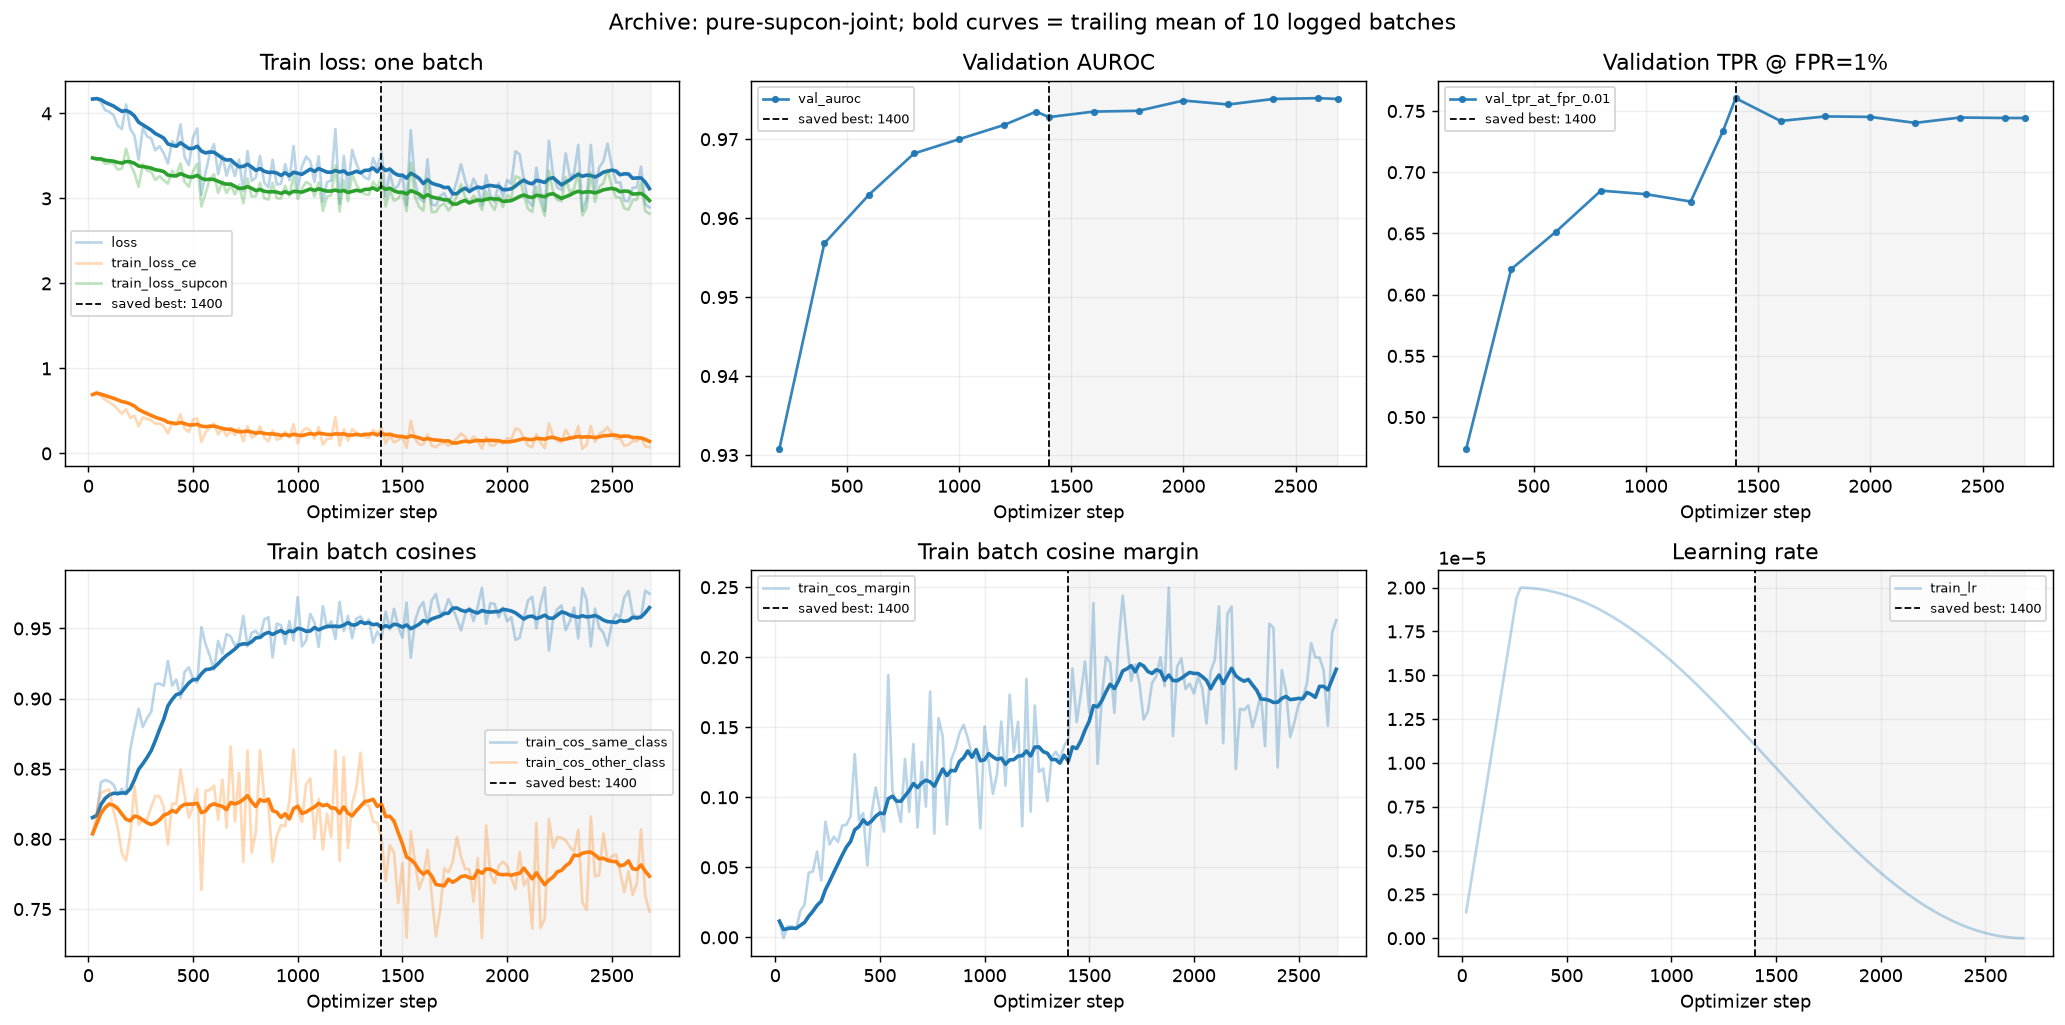

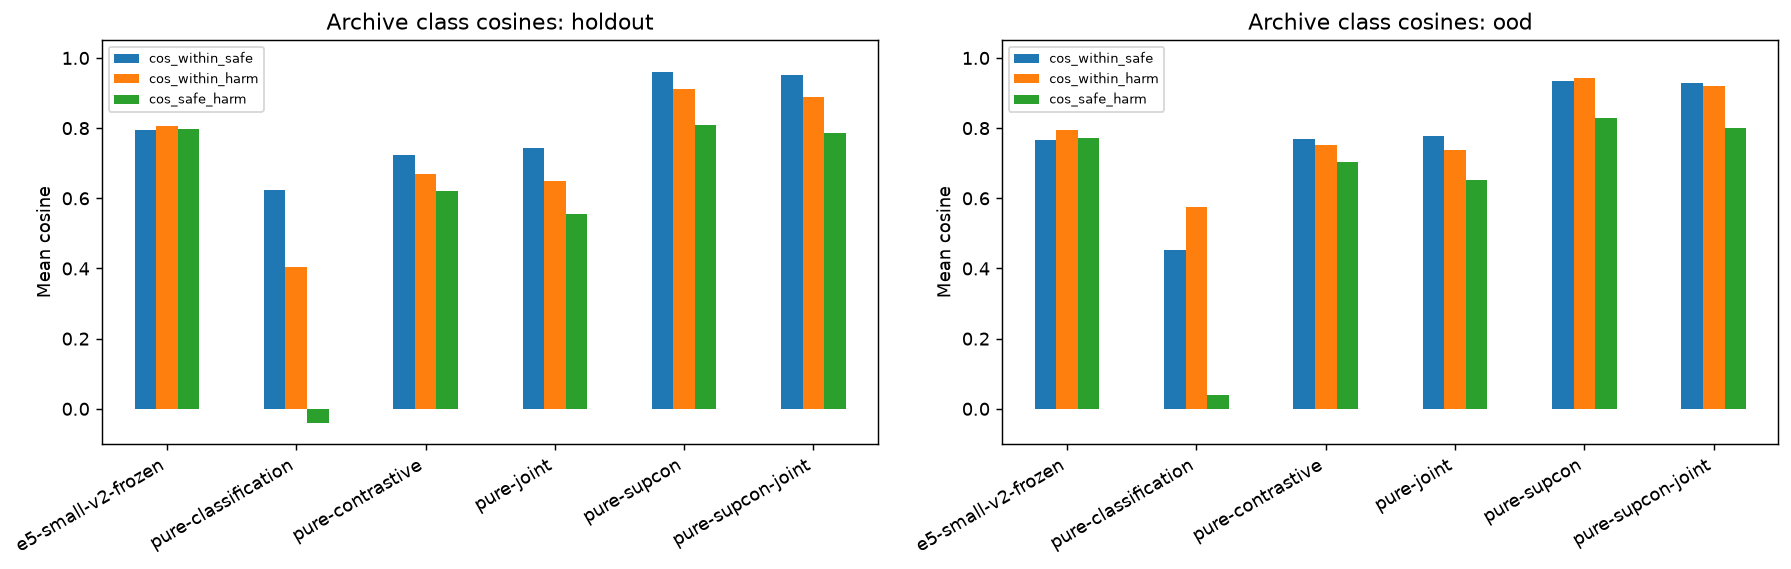

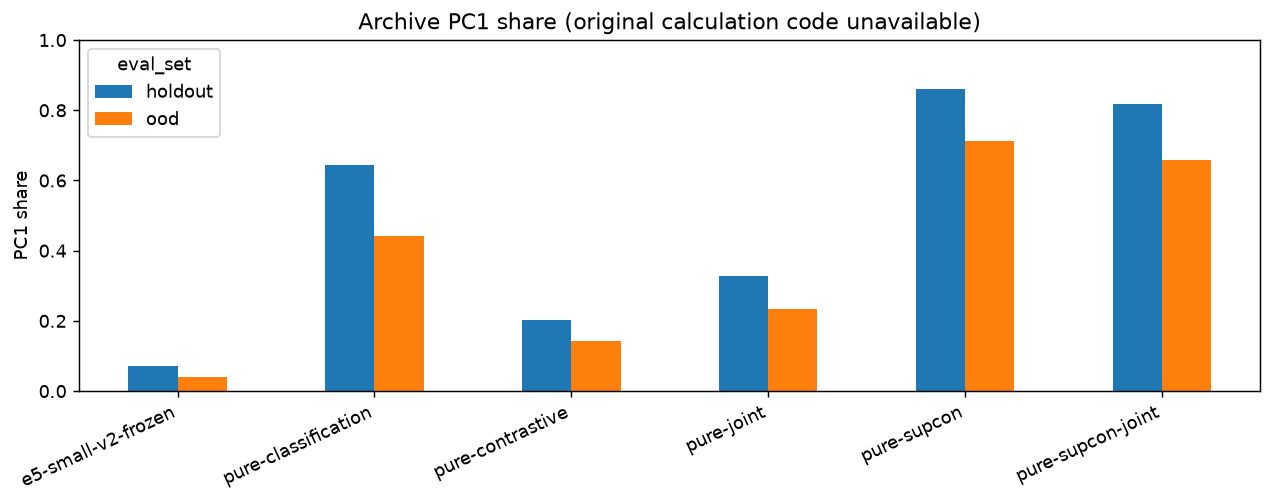

In [3]:
losses, evaluations = history_loss[HISTORY_RUN], history_eval[HISTORY_RUN]
best_step = int(archive_runs.set_index("run").loc[HISTORY_RUN, "best_step"])
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
panels = [
    (axes[0, 0], losses, ["loss", "train_loss_ce", "train_loss_supcon", "train_loss_contrastive"], "Train loss: one batch"),
    (axes[0, 1], evaluations, ["val_auroc"], "Validation AUROC"),
    (axes[0, 2], evaluations, ["val_tpr_at_fpr_0.01"], "Validation TPR @ FPR=1%"),
    (axes[1, 0], losses, ["train_cos_same_class", "train_cos_other_class"], "Train batch cosines"),
    (axes[1, 1], losses, ["train_cos_margin"], "Train batch cosine margin"),
    (axes[1, 2], losses, ["train_lr"], "Learning rate"),
]
for ax, frame, columns, title in panels:
    columns = [c for c in columns if c in frame]
    for column in columns:
        line, = ax.plot(frame.step, frame[column], alpha=0.3 if frame is losses else 0.9,
                        marker=None if frame is losses else ".", label=column)
        if frame is losses and column != "train_lr":
            ax.plot(frame.step, frame[column].rolling(10, min_periods=1).mean(), color=line.get_color(), linewidth=2)
    ax.axvline(best_step, color="black", linestyle="--", linewidth=1, label=f"saved best: {best_step}")
    ax.axvspan(best_step, 2688, color="grey", alpha=0.08)
    ax.set(title=title, xlabel="Optimizer step")
    ax.grid(alpha=0.2)
    if not columns:
        ax.text(0.5, 0.5, "Not logged for this objective", ha="center", transform=ax.transAxes)
    ax.legend(fontsize=7)
fig.suptitle(f"Archive: {HISTORY_RUN}; bold curves = trailing mean of 10 logged batches", fontsize=12)
fig.tight_layout()
fig.savefig(ARCHIVE_OUT / "training_history.png", dpi=150)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for i, split in enumerate(["holdout", "ood"]):
    frame = archive_geometry.loc[archive_geometry.eval_set == split].set_index("model")
    frame[["cos_within_safe", "cos_within_harm", "cos_safe_harm"]].plot.bar(ax=axes[i])
    axes[i].set(title=f"Archive class cosines: {split}", ylabel="Mean cosine", ylim=(-0.1, 1.05), xlabel="")
    axes[i].tick_params(axis="x", labelrotation=30)
    for label in axes[i].get_xticklabels(): label.set_ha("right")
    axes[i].legend(fontsize=7)
fig.tight_layout()
fig.savefig(ARCHIVE_OUT / "archive_class_cosines.png", dpi=150)
plt.show()
plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 4))
archive_geometry.pivot(index="model", columns="eval_set", values="pc1_share").plot.bar(ax=ax)
ax.set(title="Archive PC1 share (original calculation code unavailable)", ylabel="PC1 share", ylim=(0, 1), xlabel="")
ax.tick_params(axis="x", labelrotation=25)
for label in ax.get_xticklabels(): label.set_ha("right")
fig.tight_layout()
fig.savefig(ARCHIVE_OUT / "archive_pc1_share.png", dpi=150)
plt.show()
plt.close(fig)
print("После выбранного шага обучение продолжалось, но соответствующие веса не сохранились.")
print("По обучающим косинусам нельзя восстановить PR/TwoNN/kNN/uniformity на отложенных данных.")
print("Файлы архива и графики:", ARCHIVE_OUT.resolve())

## 1. Какие метрики и почему

Пусть $u_i=x_i/\|x_i\|_2$. Все расстояния ниже считаются на $u$, **без центрирования перед косинусами**. Центрирование используется только для спектра ковариации.

| Группа | Что считаем | Как читать |
|---|---|---|
| Isotropy proxy | `mean_cosine_mc`: средний косинус 100 000 случайных пар разных объектов; `mean_cosine_exact`: проверка по всем парам | Большое значение означает общую направленность. Ноль ещё не доказывает изотропность: две противоположные точки тоже дадут среднее около нуля. |
| Спектральная размерность | `participation_ratio` $=(\sum\lambda)^2/\sum\lambda^2$, `pc1_share`, `variance_trace` | Сколько направлений несёт вариацию и сколько вариации осталось. PR — линейная эффективная размерность, не оценка размерности многообразия. |
| Intrinsic dimensionality | `twonn_id`: TwoNN, отношение расстояний до двух ближайших соседей | Локальная нелинейная оценка. Зависит от объёма/плотности данных; совпадающие точки делают её ненадёжной. |
| kNN-purity | `knn_macro@10`, дополнительно k=5,20 и результаты по классам | Доля соседей того же класса; сам объект исключён. Macro даёт классам равный вес. Есть случайный уровень с учётом размеров классов. |
| Alignment / uniformity | `label_alignment_macro` $=\frac12\sum_c\mathbb E_{i\ne j\mid y_i=y_j=c}\|u_i-u_j\|^2$; `uniformity_t2` $=\log\mathbb E_{i\ne j}e^{-2\|u_i-u_j\|^2}$ | Меньший alignment означает компактность классов; более отрицательная uniformity — более равномерное заполнение сферы. Здесь positive pair — **любые два текста одного safety-класса**, а не пара перефразировок. |

Спектр, средний косинус, uniformity и TwoNN считаем также **отдельно для safe и harmful**. Это помогает заметить схлопывание внутри класса при хорошем разделении классов. Случайные пары фиксированы и одинаковы для обеих моделей; выборка сохраняет исходные пропорции классов.

Alignment при $\alpha=2$ связан с внутриклассовым косинусом как $2-2\mathbb E\cos$: это два представления одной характеристики, а не два независимых доказательства. Меньше uniformity или больше размерность не обязательно означает лучший guardrail. У исходного E5 уже бывают высокие косинусы — это описано в [карточке E5](https://huggingface.co/intfloat/e5-small-v2).

**Код и первоисточники:** [формулы и авторский код alignment/uniformity](https://github.com/SsnL/align_uniform), [статья Wang & Isola](https://proceedings.mlr.press/v119/wang20k.html), [TwoNN, Facco et al.](https://www.nature.com/articles/s41598-017-11873-y), [готовый `skdim.id.TwoNN`](https://scikit-dimension.readthedocs.io/en/latest/skdim.id.TwoNN.html), [поиск соседей sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html). Ниже — короткие самостоятельные реализации формул; отдельный пакет для TwoNN не нужен.

Дополнительно выводим `cos_within_safe`, `cos_within_harm`, `cos_safe_harm` и
`cosine_gap_macro = (cos_within_safe + cos_within_harm)/2 - cos_safe_harm`.
Внутриклассовые средние исключают пары объекта с самим собой, межклассовое среднее
равно скалярному произведению средних нормированных векторов двух классов.
Это точные средние по всем допустимым парам, без построения матрицы n×n.

**Требование «выбрать метрики и найти код» выполнено:** реализации ниже; первоисточники
и авторский код указаны в ссылках выше. Средний косинус используем как proxy общей
направленности, а не полное доказательство изотропности.


In [ ]:
# PyTorch и NumPy из Colab без необходимости не переустанавливаем.
%pip install -q "transformers==4.57.6" "datasets==4.5.0" "huggingface-hub>=0.34,<1" "safetensors>=0.4" "scipy>=1.11" "scikit-learn>=1.5,<2" "pandas>=2.2" "matplotlib>=3.8" "tqdm>=4.66"

In [4]:
import os
os.environ["USE_TF"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import gc, hashlib, importlib.metadata, json, random, time
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_dataset
from datasets.exceptions import DatasetNotFoundError
from huggingface_hub import HfApi, get_token, notebook_login
from huggingface_hub.errors import GatedRepoError
from scipy.special import logsumexp
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

SEED = 42
USE_DRIVE = False  # Drive не подключаем; последняя ячейка скачивает результаты ZIP-архивом.
REQUIRE_GPU = True
DATA_SOURCE = "wildguard"  # либо "local"
LOCAL_DATA_PATH = "/content/guardrails_eval.csv"
TEXT_COLUMN, LABEL_COLUMN = "prompt", "prompt_harm_label"
LABEL_MAP = {"unharmful": 0, "harmful": 1, "safe": 0, "unsafe": 1,
             "0": 0, "1": 1, "0.0": 0, "1.0": 1}
DATASET_ID = "allenai/wildguardmix"
DATASET_REVISION = "d29c47f41c8b51348b5c8e8c81c039b3132b66d1"
MAX_SAMPLES = None  # весь WildGuardTest; для большого своего файла начните с 5000
MAX_LENGTH, BATCH_SIZE = 512, 32
N_PAIRS = 100_000
KS = (5, 10, 20)
TWONN_DISCARD = 0.1

BASE = dict(name="base", source="intfloat/e5-small-v2",
            revision="ffb93f3bd4047442299a41ebb6fa998a38507c52", step=0)
FINAL = dict(name="finetuned", source="pineee/e5-small-v2-hivetrace-finetune-CE-SupCon",
             revision="d7905a98d3000ce2690c09171ba02ab3e9315add", step=None)

# Только реальные сохранённые веса той же траектории; можно указать HF repo или папку.
# Для локальных папок revision=None. В папке нужны config.json и веса AutoModel.
CHECKPOINTS = []
# CHECKPOINTS = [dict(name="step_500", source="/content/drive/MyDrive/run/checkpoint-500",
#                     revision=None, step=500)]
# FINAL["step"] = 1400  # ТОЛЬКО если подтверждено, что эти HF-веса = архивный pure-supcon-joint
LOSS_CSV = None  # CSV этой траектории: step, loss_total, loss_ce, loss_supcon
LOSS_FAMILY = "CE + SupCon"  # схема функции потерь, а не численное значение
# Заранее выбранный диагностический порог, НЕ универсальная граница «поломки».
REVIEW_RATIO = 0.5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# В этом проекте сохранены обе модели и исходный WildGuardTest: разрешаем локальный CPU-прогон.
LOCAL_BASE = Path(".verification/rq4_base")
LOCAL_FINAL = Path(".cache/guardrails/hub/models--pineee--e5-small-v2-hivetrace-finetune-CE-SupCon/snapshots") / FINAL["revision"]
LOCAL_TEST = Path(".cache/guardrails/datasets/allenai___wildguardmix/wildguardtest/0.0.0") / DATASET_REVISION / "wildguardmix-test.arrow"
USE_LOCAL_CACHE = DEVICE == "cpu" and all(p.exists() for p in [LOCAL_BASE / "model.safetensors", LOCAL_FINAL / "model.safetensors", LOCAL_TEST])
if USE_LOCAL_CACHE:
    for spec, location in [(BASE, LOCAL_BASE), (FINAL, LOCAL_FINAL)]:
        spec.update(cached_repo=spec["source"], cached_revision=spec["revision"], source=str(location), revision=None)
    print("Локальный CPU-прогон: сохранённые веса и полный WildGuardTest; повторного обучения нет.")
assert DEVICE == "cuda" or not REQUIRE_GPU or USE_LOCAL_CACHE, "Включите GPU в Colab и повторите запуск."
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

Локальный CPU-прогон: сохранённые веса и полный WildGuardTest; повторного обучения нет.
Device: CPU


In [5]:
IN_COLAB = False
try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    pass
DRIVE_READY = False
ROOT = Path("/content/guardrails_geometry_results") if IN_COLAB else Path("guardrails_geometry_results")
if IN_COLAB and USE_DRIVE:
    try:
        drive.mount("/content/drive")
        if not Path("/content/drive/MyDrive").is_dir():
            raise OSError("После mount папка MyDrive недоступна.")
        DRIVE_READY = True
        ROOT = Path("/content/drive/MyDrive/guardrails_geometry")
    except (ValueError, OSError, RuntimeError) as exc:
        print(f"Google Drive не подключён ({type(exc).__name__}: {exc}). Продолжаем в {ROOT}.")
if IN_COLAB and not DRIVE_READY:
    print("Файлы и кэш временные: выполните последнюю ячейку скачивания ZIP до удаления среды Colab.")
CACHE = ROOT / "embedding_cache"
RUN = ROOT / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
CACHE.mkdir(parents=True, exist_ok=True)
RUN.mkdir(parents=True, exist_ok=True)
HF_ACCOUNT = None
if IN_COLAB:
    try:
        # Prefer the explicitly configured Colab secret over a stale cached token.
        colab_hf_token = userdata.get("HF_TOKEN")
        if colab_hf_token:
            os.environ["HF_TOKEN"] = colab_hf_token.strip()
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        pass
if DATA_SOURCE == "wildguard" and not USE_LOCAL_CACHE and get_token() is None:
    notebook_login()
if DATA_SOURCE == "wildguard" and not USE_LOCAL_CACHE:
    hf_token = get_token()
    if not hf_token:
        raise RuntimeError("Нужен Hugging Face Read token. В Colab задайте секрет HF_TOKEN и включите notebook access.")
    try:
        HF_ACCOUNT = HfApi().whoami(token=hf_token)["name"]
    except Exception:
        raise RuntimeError(
            "Hugging Face не принял текущий токен. Обновите секрет Colab HF_TOKEN на активный Read token "
            "от аккаунта, которому выдали доступ к WildGuardMix, затем перезапустите эту ячейку. "
            "Токен не публикуйте."
        ) from None
    print("Аккаунт Hugging Face для загрузки датасета:", HF_ACCOUNT)
print("Результаты:", RUN)

Результаты: guardrails_geometry_results/run_20261018T134157_442709Z


## 2. Одна отложенная выборка для всех моделей

Используем `wildguardtest/test`, **метку вредоносности запроса** `prompt_harm_label` (0 — safe, 1 — harmful). В [карточке WildGuardMix](https://huggingface.co/datasets/allenai/wildguardmix) обучение размечено GPT-4, а тест — людьми с последующим аудитом. Это подходящая оценочная выборка для текущего сравнения; она уже использовалась авторами модели, поэтому не является новым нетронутым тестом для подбора гиперпараметров.

Для gated-датасета в Colab задайте секрет `HF_TOKEN` с read-доступом и включите notebook access. Ячейка входа покажет имя аккаунта Hugging Face, но не сам токен. Если аккаунт не тот, замените секрет на токен нужного аккаунта. Если отображается нужный аккаунт, но загрузка всё ещё запрещена, обновите секрет новым активным Read token от этого аккаунта; повторно принимать условия не требуется. Если доступа к датасету нет, задайте `DATA_SOURCE="local"` и укажите CSV/JSONL/Parquet с теми же колонками.

Удаляем пустые тексты, отсутствующие метки, конфликтующие метки одинаковых текстов, точные дубликаты. Затем удаляем одинаковые **входы токенизатора после truncation**: иначе длинные разные строки могут стать одним объектом и искусственно поднять kNN-purity. Все числа сохраняются. Семантические дубликаты автоматически не выявляются. В собственный CSV включайте только данные вне обучения; разбиение не создаём заново из train.

E5 здесь англоязычный. Для всех трёх моделей используем `query: `, максимум 512 токенов и одинаковый tokenizer. Префикс добавляем один раз. Если меняете настройки или источник, перезапустите ячейки с конфигурации.

In [6]:
def digest(value):
    return hashlib.sha256(json.dumps(value, ensure_ascii=False, sort_keys=True).encode()).hexdigest()

def read_table(path):
    path = Path(path)
    if path.suffix == ".csv":
        return pd.read_csv(path)
    if path.suffix == ".jsonl":
        return pd.read_json(path, lines=True)
    if path.suffix == ".parquet":
        return pd.read_parquet(path)
    raise ValueError("Нужен CSV, JSONL или Parquet.")

def remove_duplicates(frame, key):
    conflicts = frame.groupby(key)["label"].nunique()
    bad = frame[key].isin(conflicts[conflicts > 1].index)
    good = frame.loc[~bad]
    result = good.drop_duplicates(key).copy()
    return result, {"conflicting_rows": int(bad.sum()), "duplicate_rows": len(good) - len(result)}

def clean_data(raw):
    frame = raw[[TEXT_COLUMN, LABEL_COLUMN]].copy()
    frame["source_row"] = np.arange(len(frame))
    valid = frame[TEXT_COLUMN].map(lambda x: isinstance(x, str) and bool(x.strip())) & frame[LABEL_COLUMN].notna()
    frame = frame.loc[valid].copy()
    mapped = frame[LABEL_COLUMN].astype(str).str.lower().str.strip().map(LABEL_MAP)
    if mapped.isna().any():
        raise ValueError("Неизвестные метки: " + str(frame.loc[mapped.isna(), LABEL_COLUMN].unique()))
    frame["label"] = mapped.astype(int)
    frame["text"] = frame[TEXT_COLUMN].str.strip()
    frame["input_text"] = frame["text"].map(lambda s: s if s.startswith("query: ") else "query: " + s)
    frame, duplicate_audit = remove_duplicates(frame, "input_text")
    return frame.reset_index(drop=True), {"input_rows": len(raw), "missing_removed": int((~valid).sum()),
                                        "text_duplicates": duplicate_audit}

if DATA_SOURCE == "wildguard":
    try:
        if USE_LOCAL_CACHE:
            from datasets import Dataset
            raw = Dataset.from_file(str(LOCAL_TEST)).to_pandas()
        else:
            raw = load_dataset(DATASET_ID, "wildguardtest", split="test",
                               revision=DATASET_REVISION).to_pandas()
    except (DatasetNotFoundError, GatedRepoError):
        raise RuntimeError(
            f"Hugging Face ({HF_ACCOUNT or 'аккаунт не определён'}) запретил доступ к allenai/wildguardmix. "
            "Условия уже приняты — повторять это не нужно. Проверьте, что показанный аккаунт совпадает "
            "с аккаунтом, которому выдали доступ. В Colab Secrets обновите HF_TOKEN на активный Read token "
            "этого аккаунта, убедитесь, что notebook access включён, и перезапустите ячейки входа и данных. "
            "Не вставляйте токен в вывод или чат. Альтернатива: DATA_SOURCE='local' и собственный CSV/JSONL/Parquet."
        ) from None
    data_source = dict(repo=DATASET_ID, revision=DATASET_REVISION, config="wildguardtest", split="test")
elif DATA_SOURCE == "local":
    raw = read_table(LOCAL_DATA_PATH)
    data_source = dict(path=str(LOCAL_DATA_PATH), sha256=hashlib.sha256(Path(LOCAL_DATA_PATH).read_bytes()).hexdigest())
else:
    raise ValueError("DATA_SOURCE должен быть wildguard или local.")
df, audit = clean_data(raw)
tokenizer = AutoTokenizer.from_pretrained(BASE["source"], revision=BASE["revision"])

token_hashes, lengths = [], []
for start in range(0, len(df), 256):
    batch_text = df["input_text"].iloc[start:start + 256].tolist()
    full = tokenizer(batch_text, truncation=False, padding=False, verbose=False)["input_ids"]
    cut = tokenizer(batch_text, truncation=True, max_length=MAX_LENGTH, padding=False)["input_ids"]
    lengths.extend(map(len, full))
    token_hashes.extend(digest(ids) for ids in cut)
df["token_hash"], df["n_tokens_full"] = token_hashes, lengths
audit["truncated_before_token_dedup"] = int((df["n_tokens_full"] > MAX_LENGTH).sum())
df, audit["token_duplicates"] = remove_duplicates(df, "token_hash")
df = df.reset_index(drop=True)
audit["clean_rows_before_sampling"] = len(df)
if MAX_SAMPLES is not None and MAX_SAMPLES < len(df):
    chosen, _ = train_test_split(np.arange(len(df)), train_size=MAX_SAMPLES,
                                 stratify=df["label"], random_state=SEED)
    df = df.iloc[np.sort(chosen)].reset_index(drop=True)
counts = df["label"].value_counts()
assert set(counts.index) == {0, 1} and counts.min() >= 25, "Нужно минимум 25 уникальных входов каждого класса."
df["row_id"] = df["input_text"].map(lambda s: hashlib.sha256(s.encode()).hexdigest())
texts, y = df["input_text"].tolist(), df["label"].to_numpy()
assert 10 in KS and min(KS) >= 1 and max(KS) < len(y), "KS должен включать 10; все k меньше n."
assert N_PAIRS > 0 and 0 <= TWONN_DISCARD < 1
DATA_HASH = digest(df[["row_id", "token_hash", "label"]].to_dict("records"))
audit["analysis_rows"] = len(df)
audit["truncated_analysis_rows"] = int((df["n_tokens_full"] > MAX_LENGTH).sum())
df.to_csv(RUN / "eval_inputs.csv", index=False)
(RUN / "data_audit.json").write_text(json.dumps(audit, indent=2))
print(json.dumps(audit, indent=2))
display(counts.rename_axis("label").rename("n").to_frame())

{
  "input_rows": 1725,
  "missing_removed": 26,
  "text_duplicates": {
    "conflicting_rows": 0,
    "duplicate_rows": 0
  },
  "truncated_before_token_dedup": 3,
  "token_duplicates": {
    "conflicting_rows": 0,
    "duplicate_rows": 0
  },
  "clean_rows_before_sampling": 1699,
  "analysis_rows": 1699,
  "truncated_analysis_rows": 3
}


,n
label,
0,945
1,754


## 3. Эмбеддинги: два прохода и кэш

Берём среднее последнего hidden state по `attention_mask=1`, включая специальные токены, как в [инференсе дообученной модели](https://huggingface.co/pineee/e5-small-v2-hivetrace-finetune-CE-SupCon). Сохраняем raw-векторы, затем отдельно L2-нормируем для метрик. Классификационная голова здесь не нужна.

Инференс в FP32, dropout отключён, модели загружаются на GPU последовательно. Кэш зависит от весов/ревизии, данных, tokenizer, параметров и версий. Завершённый проход сохраняется сразу; при повторном запуске с теми же настройками используется доступный кэш. Кэш на Drive переживает удаление среды Colab, локальный кэш — нет. Для воспроизведения текущих файлов закреплены ревизии HF; это не доказывает, что именно такая ревизия base использовалась в исходном обучении — это нужно сверить с его конфигурацией.

In [7]:
VERSIONS = {p: importlib.metadata.version(p) for p in
            ["torch", "transformers", "datasets", "huggingface-hub", "numpy", "scipy", "scikit-learn", "pandas"]}
TOKENIZER_HASH = digest(json.loads(tokenizer.backend_tokenizer.to_str()))

def weights_identity(spec):
    path = Path(spec["source"])
    if not path.is_dir():
        assert spec.get("revision") and len(spec["revision"]) == 40, "Для HF укажите commit SHA."
        return {"repo": spec["source"], "revision": spec["revision"]}
    files = sorted(p for p in path.rglob("*") if p.suffix in {".json", ".safetensors", ".bin"})
    assert any(p.suffix in {".safetensors", ".bin"} for p in files), "Нет файлов весов."
    h = hashlib.sha256()
    for p in files:
        h.update(str(p.relative_to(path)).encode())
        with p.open("rb") as f:
            for block in iter(lambda: f.read(1024 * 1024), b""):
                h.update(block)
    return {"path": str(path.resolve()), "sha256": h.hexdigest(),
            "cached_repo": spec.get("cached_repo"), "cached_revision": spec.get("cached_revision")}

@torch.inference_mode()
def encode(spec):
    identity = weights_identity(spec)
    key = digest(dict(weights=identity, data=DATA_HASH, tokenizer=TOKENIZER_HASH,
                      max_length=MAX_LENGTH, batch=BATCH_SIZE, precision="fp32", pooling="masked_mean_v1", attention="eager",
                      device=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu", versions=VERSIONS))
    target = CACHE / (key + ".npz")
    if target.exists():
        with np.load(target) as cached:
            X = cached["raw"]
        assert X.shape == (len(texts), 384) and np.isfinite(X).all()
        print(spec["name"], "— кэш", target.name)
        return X, identity
    # На опубликованных моделях проверяем совпадение реальных входов token IDs.
    # Локальные промежуточные веса используют этот же базовый tokenizer.
    if not Path(spec["source"]).is_dir():
        own = AutoTokenizer.from_pretrained(spec["source"], revision=spec["revision"])
        own_hashes = []
        for start in range(0, len(texts), 256):
            ids = own(texts[start:start + 256], truncation=True, max_length=MAX_LENGTH)["input_ids"]
            own_hashes.extend(digest(row) for row in ids)
        assert own_hashes == df["token_hash"].tolist(), "Tokenizers дают разные входы; сравнение остановлено."
    model = AutoModel.from_pretrained(spec["source"], revision=spec.get("revision"),
                                      attn_implementation="eager").float().to(DEVICE).eval()
    model.requires_grad_(False)
    assert model.config.hidden_size == 384 and model.config.max_position_embeddings >= MAX_LENGTH
    chunks, start, batch_size = [], 0, BATCH_SIZE
    tick = time.monotonic()
    progress = tqdm(total=len(texts), desc=spec["name"])
    try:
        while start < len(texts):
            batch = hidden = mask = pooled = None
            stop = min(start + batch_size, len(texts))
            try:
                batch = tokenizer(texts[start:stop], padding=True, truncation=True,
                                  max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
                hidden = model(**batch).last_hidden_state
                mask = batch["attention_mask"].unsqueeze(-1).float()
                pooled = (hidden * mask).sum(1) / mask.sum(1)
                chunks.append(pooled.cpu().numpy())
            except torch.cuda.OutOfMemoryError:
                if batch_size == 1:
                    raise
                batch = hidden = mask = pooled = None
                gc.collect()
                torch.cuda.empty_cache()
                batch_size = max(1, batch_size // 2)
                print("Новый batch:", batch_size)
                continue
            progress.update(stop - start)
            start = stop
        X = np.concatenate(chunks)
        assert X.shape == (len(texts), 384) and np.isfinite(X).all()
        temporary = target.with_suffix(".tmp.npz")
        np.savez_compressed(temporary, raw=X)
        temporary.replace(target)
        print(spec["name"], f"— {time.monotonic() - tick:.1f} s; batch={batch_size}")
    finally:
        progress.close()
        del model, batch, hidden, mask, pooled
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    return X, identity

def normalize(X):
    X = np.asarray(X, dtype=np.float64)
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    assert np.isfinite(X).all() and np.all(norms > 1e-12), "Нулевые/нечисловые эмбеддинги."
    return X / norms

representations, model_identities = {}, {}
for spec in [BASE, FINAL]:
    raw_vectors, model_identities[spec["name"]] = encode(spec)
    representations[spec["name"]] = normalize(raw_vectors)
    np.savez_compressed(RUN / (spec["name"] + "_embeddings.npz"), raw=raw_vectors, labels=y,
                        row_ids=df["row_id"].to_numpy(dtype=str))
del raw_vectors

base — кэш 732f14004203b7f301d2973a381832561936ec543ef641bfc2b62a0a9841b4ac.npz
finetuned — кэш d45075834fe3de66c42b085231765be3c0859b031e5827e9872571202bf7b193.npz


## 4. Реализации метрик

`mean_cosine_exact` использует тождество $(\|\sum_i u_i\|^2-\sum_i\|u_i\|^2)/(n(n-1))$ и не строит матрицу всех пар. Для uniformity берём те же случайные пары и стабильный `logsumexp`. Повторения пар допустимы; пары объекта с самим собой исключены. Сохраняем seed и сами индексы пар.

TwoNN: $\mu_i=r_{2,i}/r_{1,i}$, где $r$ — **евклидово расстояние**, не его квадрат и не cosine distance. На нормированных векторах порядок соседей совпадает с косинусным. Сортируем $\mu$, отбрасываем верхние 10%, подгоняем прямую через ноль для $-\log(1-F_i)=d\log\mu_i$, $F_i=i/n$ с нумерацией от нуля, как в `skdim`. При менее 50 объектах или нулевом расстоянии до соседа выдаём `NaN` и диагностическую долю таких объектов, не маскируем проблему добавлением epsilon.

Результаты описывают эту выборку. Интервалы по случайным парам не были бы доверительными интервалами по данным. Для статьи нужны независимый тест и повторы обучения с несколькими seed; текущая пара моделей этого не заменяет.

In [8]:
def sample_pairs(n, count=N_PAIRS, seed=SEED):
    rng = np.random.default_rng(seed)
    left = rng.integers(n, size=count)
    right = rng.integers(n - 1, size=count)
    right += right >= left
    return left, right

def pair_cosines(U, pairs):
    left, right = pairs
    result = np.empty(len(left))
    for start in range(0, len(left), 8192):
        a, b = left[start:start + 8192], right[start:start + 8192]
        result[start:start + 8192] = np.einsum("ij,ij->i", U[a], U[b])
    return np.clip(result, -1, 1)

def exact_mean_cosine(U):
    n = len(U)
    return float((np.square(U.sum(0)).sum() - np.square(U).sum()) / (n * (n - 1)))

def class_cosines(U, labels):
    safe, harmful = U[labels == 0], U[labels == 1]
    within_safe, within_harm = exact_mean_cosine(safe), exact_mean_cosine(harmful)
    between = float(safe.mean(0) @ harmful.mean(0))
    return dict(cos_within_safe=within_safe, cos_within_harm=within_harm,
                cos_safe_harm=between, cosine_gap_macro=(within_safe + within_harm) / 2 - between)

def spectrum(U):
    centered = U - U.mean(0)
    eigenvalues = np.linalg.eigvalsh(centered.T @ centered / len(U))[::-1].clip(0)
    total = eigenvalues.sum()
    if total < 1e-15:
        return dict(participation_ratio=0., pc1_share=np.nan, variance_trace=float(total)), eigenvalues * 0
    fractions = eigenvalues / total
    return dict(participation_ratio=float(1 / np.square(fractions).sum()),
                pc1_share=float(fractions[0]), variance_trace=float(total)), fractions

def neighbors(U, k):
    k = min(k, len(U) - 1)
    search = NearestNeighbors(n_neighbors=k + 1, metric="euclidean", algorithm="brute", n_jobs=2).fit(U)
    distances, indices = search.kneighbors(U)
    # Индекс самого объекта исключаем явно, даже если есть совпадения и ties.
    keep = [np.flatnonzero(row != i)[:k] for i, row in enumerate(indices)]
    ids = np.stack([row[ix] for row, ix in zip(indices, keep)])
    # Прямые разности точнее формулы ||a||² + ||b||² - 2a·b около нуля.
    distances = np.empty(ids.shape)
    for start in range(0, len(U), 256):
        distances[start:start + 256] = np.linalg.norm(
            U[start:start + 256, None, :] - U[ids[start:start + 256]], axis=2)
    order = np.argsort(distances, axis=1, kind="stable")
    return np.take_along_axis(ids, order, axis=1), np.take_along_axis(distances, order, axis=1)

def twonn(distances, discard=TWONN_DISCARD):
    n = len(distances)
    invalid = (~np.isfinite(distances[:, :2]).all(1)) | (distances[:, 0] <= 1e-8)
    if n < 50 or invalid.any():
        return np.nan, float(invalid.mean())
    log_mu = np.sort(np.log(distances[:, 1] / distances[:, 0]))
    m = int(n * (1 - discard))
    a = log_mu[:m]
    b = -np.log1p(-np.arange(m) / n)
    denominator = a @ a
    estimate = float((a @ b) / denominator) if denominator > 1e-15 else np.nan
    return estimate, float(invalid.mean())

GROUPS = {"all": np.arange(len(y)), "safe": np.flatnonzero(y == 0), "harmful": np.flatnonzero(y == 1)}
PAIRS = {group: sample_pairs(len(ids)) for group, ids in GROUPS.items()}
np.savez_compressed(RUN / "pairs.npz", **{group: np.stack(pair) for group, pair in PAIRS.items()})

def evaluate(U):
    geometry, spectra, cosines = [], {}, {}
    for group, ids in GROUPS.items():
        V = U[ids]
        values = pair_cosines(V, PAIRS[group])
        stats, spectra[group] = spectrum(V)
        _, distances = neighbors(V, 2)
        dimension, invalid = twonn(distances)
        stats.update(group=group, n=len(V), mean_cosine_mc=float(values.mean()),
                     mean_cosine_exact=exact_mean_cosine(V),
                     uniformity_t2=float(logsumexp(-2 * (2 - 2 * values)) - np.log(len(values))),
                     twonn_id=dimension, twonn_invalid_fraction=invalid)
        geometry.append(stats)
        cosines[group] = values
    geometry[0].update(class_cosines(U, y))
    ids, _ = neighbors(U, max(KS))
    purity = []
    for k in KS:
        local = (y[ids[:, :k]] == y[:, None]).mean(1)
        by_class = [float(local[y == c].mean()) for c in [0, 1]]
        null = [(int((y == c).sum()) - 1) / (len(y) - 1) for c in [0, 1]]
        purity.append(dict(k=k, macro=float(np.mean(by_class)), safe=by_class[0], harmful=by_class[1],
                           null_macro=float(np.mean(null)), excess_macro=float(np.mean(by_class) - np.mean(null))))
    within = [row["mean_cosine_exact"] for row in geometry if row["group"] != "all"]
    alignment = float(2 - 2 * np.mean(within))
    return pd.DataFrame(geometry), pd.DataFrame(purity), alignment, spectra, cosines

results = {name: evaluate(U) for name, U in representations.items()}

## 5. Сравнение и графики

В первой таблице `delta = finetuned − base`. Отрицательный alignment и положительная purity в колонке delta означают более компактные/разделённые safety-классы. Изменение PR/TwoNN интерпретируем вместе с **внутриклассовым разбросом**. `twonn_invalid_fraction > 0` требует разбора совпадающих эмбеддингов.

Для kNN случайный уровень — $(n_c-1)/(n-1)$ для класса $c$, затем среднее по классам; он не обязан быть ровно 0.5 на конечной выборке. kNN-purity — описательная метрика локальных соседств на тесте, не accuracy обученного классификатора.

In [9]:
def summary(result):
    geometry, purity, alignment, _, _ = result
    row = geometry.set_index("group").loc["all"]
    return {key: row[key] for key in ["mean_cosine_mc", "mean_cosine_exact", "participation_ratio",
            "pc1_share", "variance_trace", "twonn_id", "uniformity_t2",
            "cos_within_safe", "cos_within_harm", "cos_safe_harm", "cosine_gap_macro"]} | {
        "knn_macro@10": float(purity.set_index("k").loc[10, "macro"]),
        "label_alignment_macro": alignment}

comparison = pd.DataFrame({name: summary(result) for name, result in results.items()})
comparison["delta"] = comparison["finetuned"] - comparison["base"]
geometry_table = pd.concat([result[0].assign(model=name) for name, result in results.items()], ignore_index=True)
purity_table = pd.concat([result[1].assign(model=name) for name, result in results.items()], ignore_index=True)
display(comparison.round(5))
display(geometry_table[["model", "group", "n", "mean_cosine_exact", "pc1_share", "participation_ratio", "variance_trace", "twonn_id", "uniformity_t2", "twonn_invalid_fraction"]].round(5))
display(purity_table.round(4))
comparison.to_csv(RUN / "before_after.csv", index_label="metric")
geometry_table.to_csv(RUN / "geometry_by_class.csv", index=False)
purity_table.to_csv(RUN / "knn_purity.csv", index=False)

,base,finetuned,delta
mean_cosine_mc,0.79872,0.85688,0.05816
mean_cosine_exact,0.79876,0.85729,0.05853
participation_ratio,80.61720,1.49506,-79.12213
pc1_share,0.07068,0.81758,0.74690
variance_trace,0.20112,0.14263,-0.05849
twonn_id,17.16736,15.85279,-1.31456
uniformity_t2,-0.79379,-0.45395,0.33984
cos_within_safe,0.79484,0.95197,0.15713
cos_within_harm,0.80739,0.88959,0.08220
cos_safe_harm,0.79777,0.78515,-0.01263


,model,group,n,mean_cosine_exact,pc1_share,participation_ratio,variance_trace,twonn_id,uniformity_t2,twonn_invalid_fraction
0,base,all,1699,0.79876,0.07068,80.61720,0.20112,17.16736,-0.79379,0.0
1,base,safe,945,0.79484,0.07336,72.78854,0.20494,15.10359,-0.80989,0.0
2,base,harmful,754,0.80739,0.06965,73.08080,0.19235,20.52927,-0.75927,0.0
3,finetuned,all,1699,0.85729,0.81758,1.49506,0.14263,15.85279,-0.45395,0.0
4,finetuned,safe,945,0.95197,0.50247,3.91012,0.04798,12.97358,-0.16795,0.0
5,finetuned,harmful,754,0.88959,0.75146,1.76779,0.11026,20.53772,-0.36278,0.0


,k,macro,safe,harmful,null_macro,excess_macro,model
0,5,0.7207,0.6688,0.7727,0.4997,0.2210,base
1,10,0.6927,0.6323,0.7532,0.4997,0.1930,base
2,20,0.6646,0.6039,0.7253,0.4997,0.1649,base
3,5,0.8453,0.8724,0.8183,0.4997,0.3456,finetuned
4,10,0.8433,0.8726,0.8139,0.4997,0.3436,finetuned
5,20,0.8364,0.8736,0.7991,0.4997,0.3367,finetuned


### Карта отдельных текстов: проекция 384 → 2 измерения

Каждая точка — **один отложенный текст**, цвет — его метка. Два рисунка используют
**одну и ту же PCA-проекцию и одинаковые оси**, чтобы «до» и «после» можно было
сравнивать. PCA обучена на объединении двух наборов нормированных эмбеддингов,
без использования меток. В заголовке каждой панели показано, какая доля вариации
соответствующей модели попала в плоскость. Остальная вариация остаётся в других
направлениях, поэтому перекрытие на рисунке не доказывает перекрытие в 384D.

Этот рисунок помогает **объяснять**, где расположены тексты. Выводы о локальных
соседствах и разнообразии делайте по метрикам исходных 384-мерных векторов ниже.

Дополнительно сохранён рисунок с **отдельной PCA для каждого состояния**:
на нём лучше видна форма обоих облаков, но координаты двух панелей уже нельзя
напрямую сравнивать между собой. Процент в заголовках показывает, сколько
вариации каждого облака удержали его собственные две главные компоненты.

Размерность эмбеддинга: 384 ; число классов: 2
Доля вариации, видимая на общей плоскости: {'base': 0.0147, 'finetuned': 0.8179}


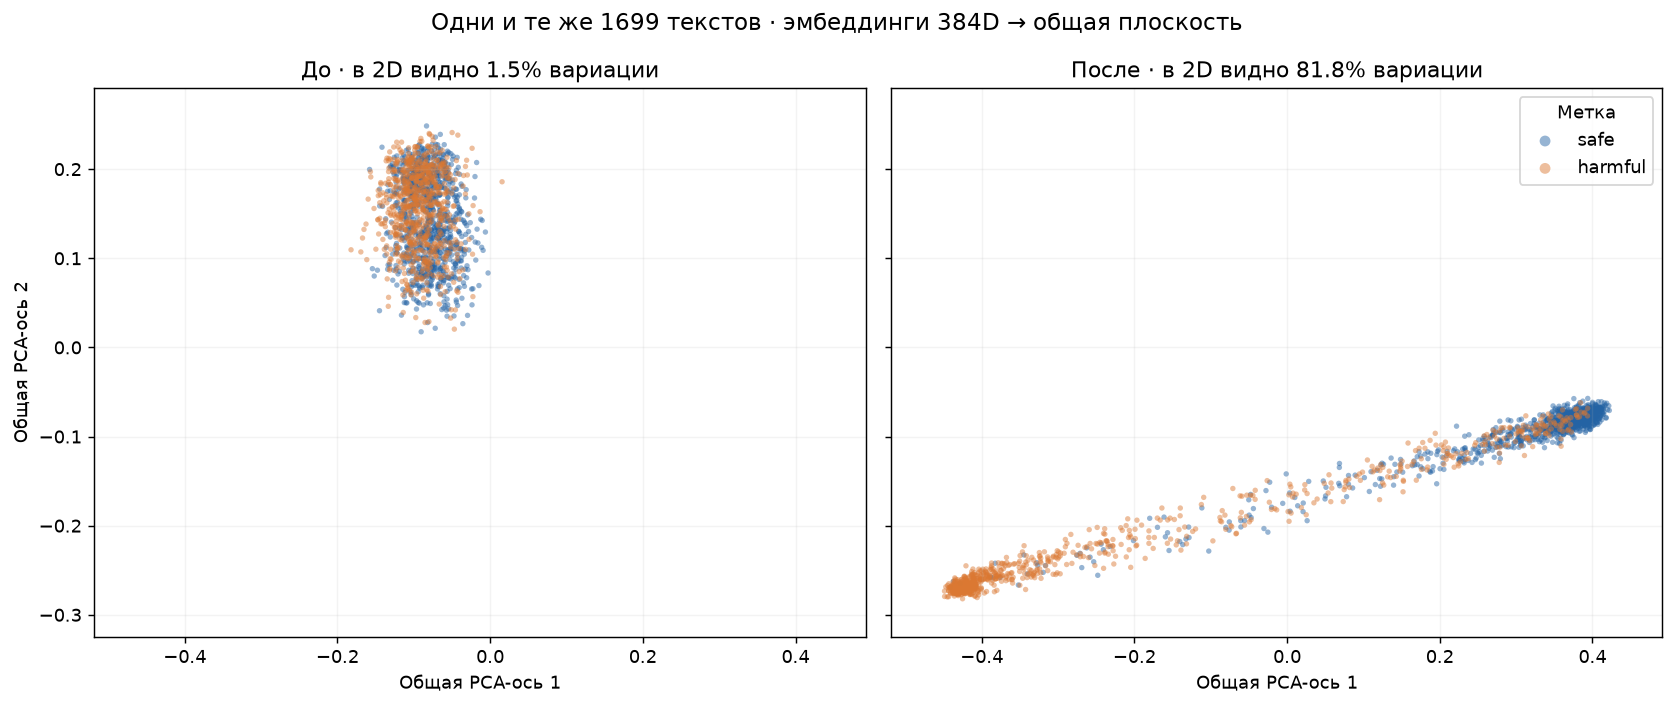

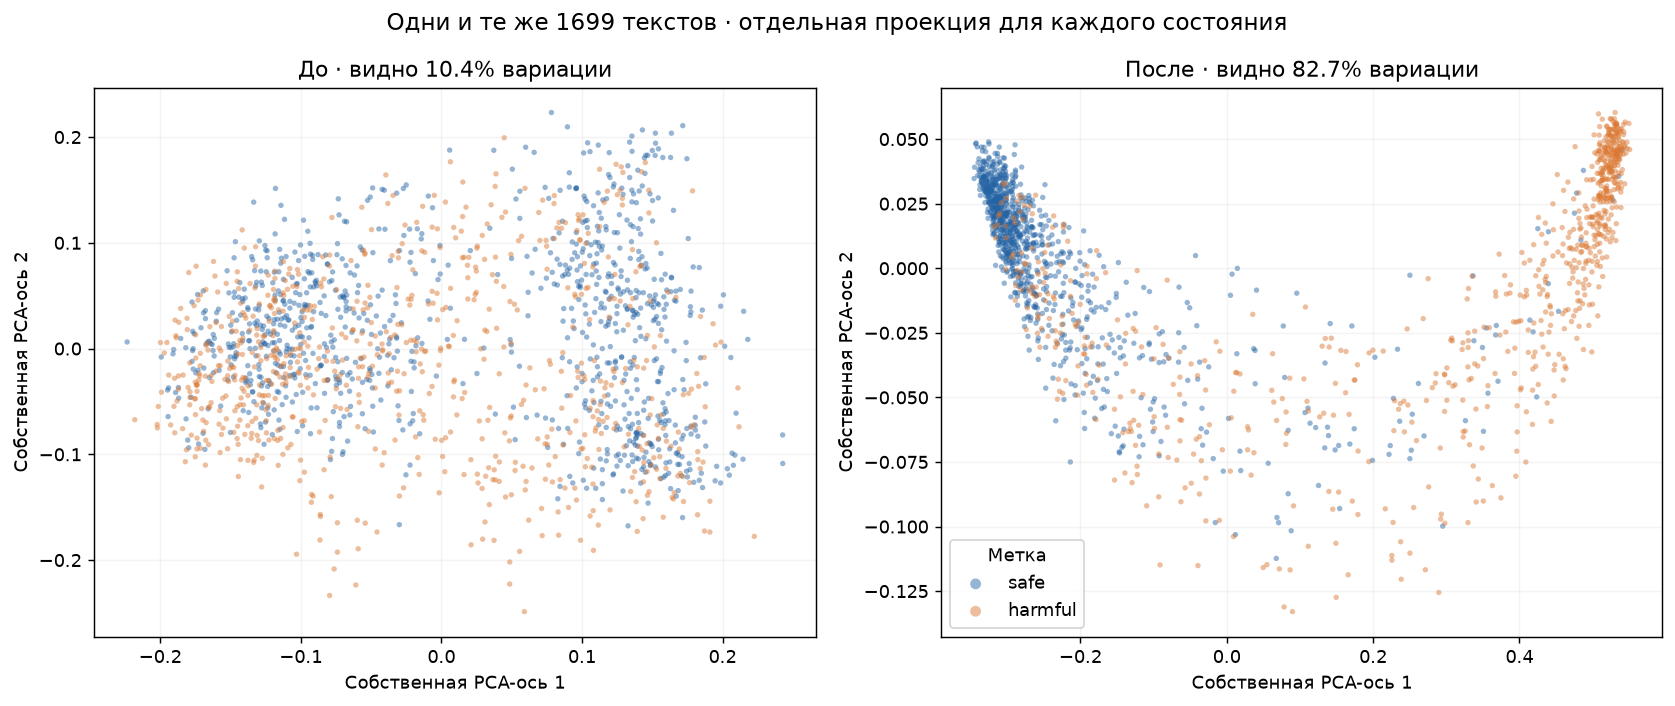

In [10]:
from sklearn.decomposition import PCA

both_vectors = np.vstack([representations["base"], representations["finetuned"]])
plane = PCA(n_components=2, svd_solver="full").fit(both_vectors)
base_xy = plane.transform(representations["base"])
finetuned_xy = plane.transform(representations["finetuned"])
coords = np.vstack([base_xy, finetuned_xy])
xmin, ymin = coords.min(axis=0)
xmax, ymax = coords.max(axis=0)
xpad, ypad = max((xmax-xmin)*0.08, 0.01), max((ymax-ymin)*0.08, 0.01)
plane_share = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, name, points in [(axes[0], "base", base_xy), (axes[1], "finetuned", finetuned_xy)]:
    for code, label, color in [(0, "safe", "#2463a4"), (1, "harmful", "#db7832")]:
        ax.scatter(points[y == code, 0], points[y == code, 1], s=9, alpha=0.48,
                   color=color, edgecolors="none", label=label, rasterized=True)
    share = float(np.var(points, axis=0).sum() / np.var(representations[name], axis=0).sum())
    plane_share[name] = share
    ax.set(title=f"{'До' if name == 'base' else 'После'} · в 2D видно {share:.1%} вариации",
           xlim=(xmin-xpad, xmax+xpad), ylim=(ymin-ypad, ymax+ypad),
           xlabel="Общая PCA-ось 1")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("Общая PCA-ось 2")
axes[1].legend(title="Метка", markerscale=2)
fig.suptitle(f"Одни и те же {len(y)} текстов · эмбеддинги 384D → общая плоскость", fontsize=13)
fig.tight_layout()
fig.savefig(RUN / "pca_scatter_before_after.png", dpi=180)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
separate_share = {}
for ax, name in [(axes[0], "base"), (axes[1], "finetuned")]:
    own_plane = PCA(n_components=2, svd_solver="full")
    own_xy = own_plane.fit_transform(representations[name])
    separate_share[name] = float(own_plane.explained_variance_ratio_.sum())
    for code, label, color in [(0, "safe", "#2463a4"), (1, "harmful", "#db7832")]:
        ax.scatter(own_xy[y == code, 0], own_xy[y == code, 1], s=9, alpha=0.48,
                   color=color, edgecolors="none", label=label, rasterized=True)
    ax.set(title=f"{'До' if name == 'base' else 'После'} · видно {separate_share[name]:.1%} вариации",
           xlabel="Собственная PCA-ось 1", ylabel="Собственная PCA-ось 2")
    ax.grid(alpha=0.15)
axes[1].legend(title="Метка", markerscale=2)
fig.suptitle(f"Одни и те же {len(y)} текстов · отдельная проекция для каждого состояния", fontsize=13)
fig.tight_layout()
fig.savefig(RUN / "pca_scatter_separate_axes.png", dpi=180)
plt.show()
plt.close(fig)

points_table = pd.DataFrame(dict(row_id=df.row_id, label=y,
                                 before_x=base_xy[:, 0], before_y=base_xy[:, 1],
                                 after_x=finetuned_xy[:, 0], after_y=finetuned_xy[:, 1]))
points_table.to_csv(RUN / "pca_2d_coordinates.csv", index=False)
(RUN / "pca_2d_metadata.json").write_text(json.dumps(dict(
    n_texts=len(y), original_dimensions=representations["base"].shape[1], classes={"safe": 0, "harmful": 1},
    common_axes=True, pooled_variance_share=float(plane.explained_variance_ratio_.sum()),
    within_model_variance_share=plane_share, separate_pca_variance_share=separate_share,
    normalized_before_pca=True), ensure_ascii=False, indent=2))
print("Размерность эмбеддинга:", representations["base"].shape[1], "; число классов:", len(np.unique(y)))
print("Доля вариации, видимая на общей плоскости:", {k: round(v, 4) for k, v in plane_share.items()})

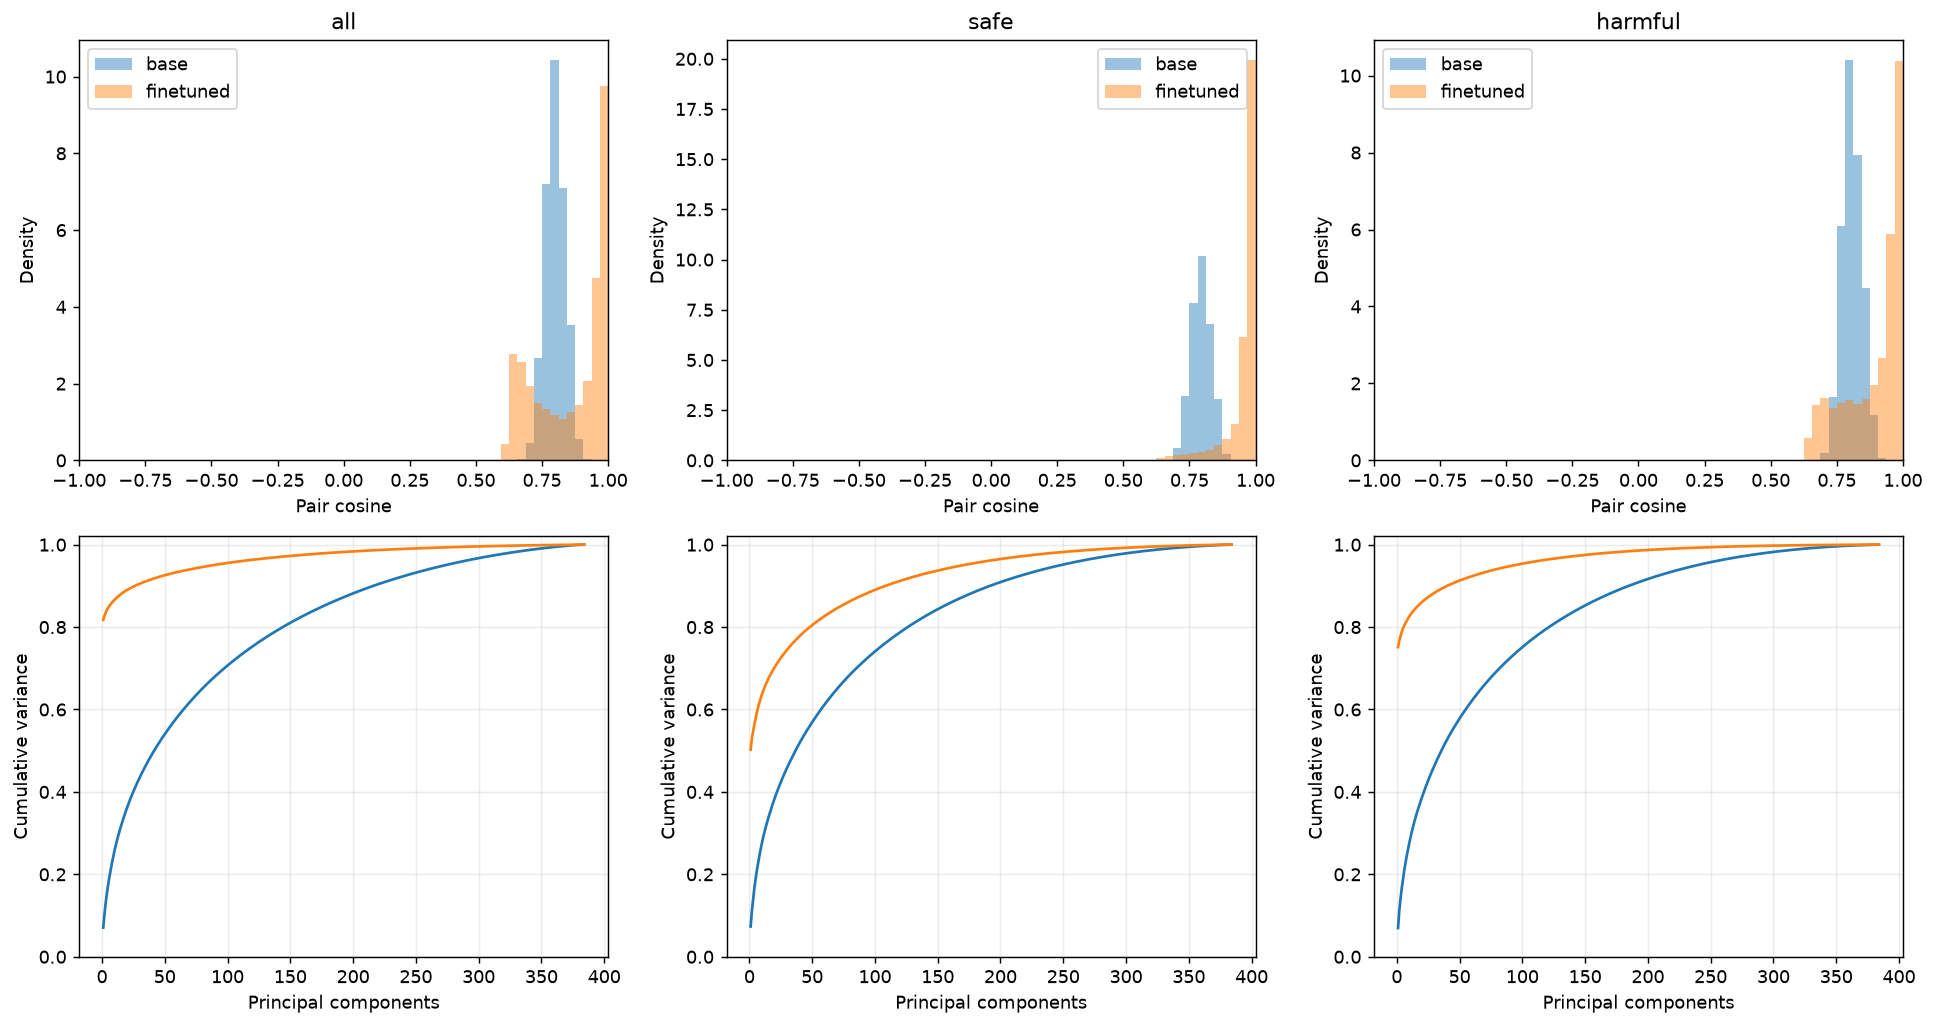

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, group in enumerate(GROUPS):
    for name, result in results.items():
        axes[0, column].hist(result[4][group], bins=np.linspace(-1, 1, 65), density=True,
                             alpha=0.45, label=name)
        axes[1, column].plot(np.arange(1, 385), np.cumsum(result[3][group]), label=name)
    axes[0, column].set(title=group, xlabel="Pair cosine", ylabel="Density", xlim=(-1, 1))
    axes[1, column].set(xlabel="Principal components", ylabel="Cumulative variance", ylim=(0, 1.02))
    axes[0, column].legend()
    axes[1, column].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RUN / "cosines_and_spectra.png", dpi=160)
plt.show()
plt.close(fig)

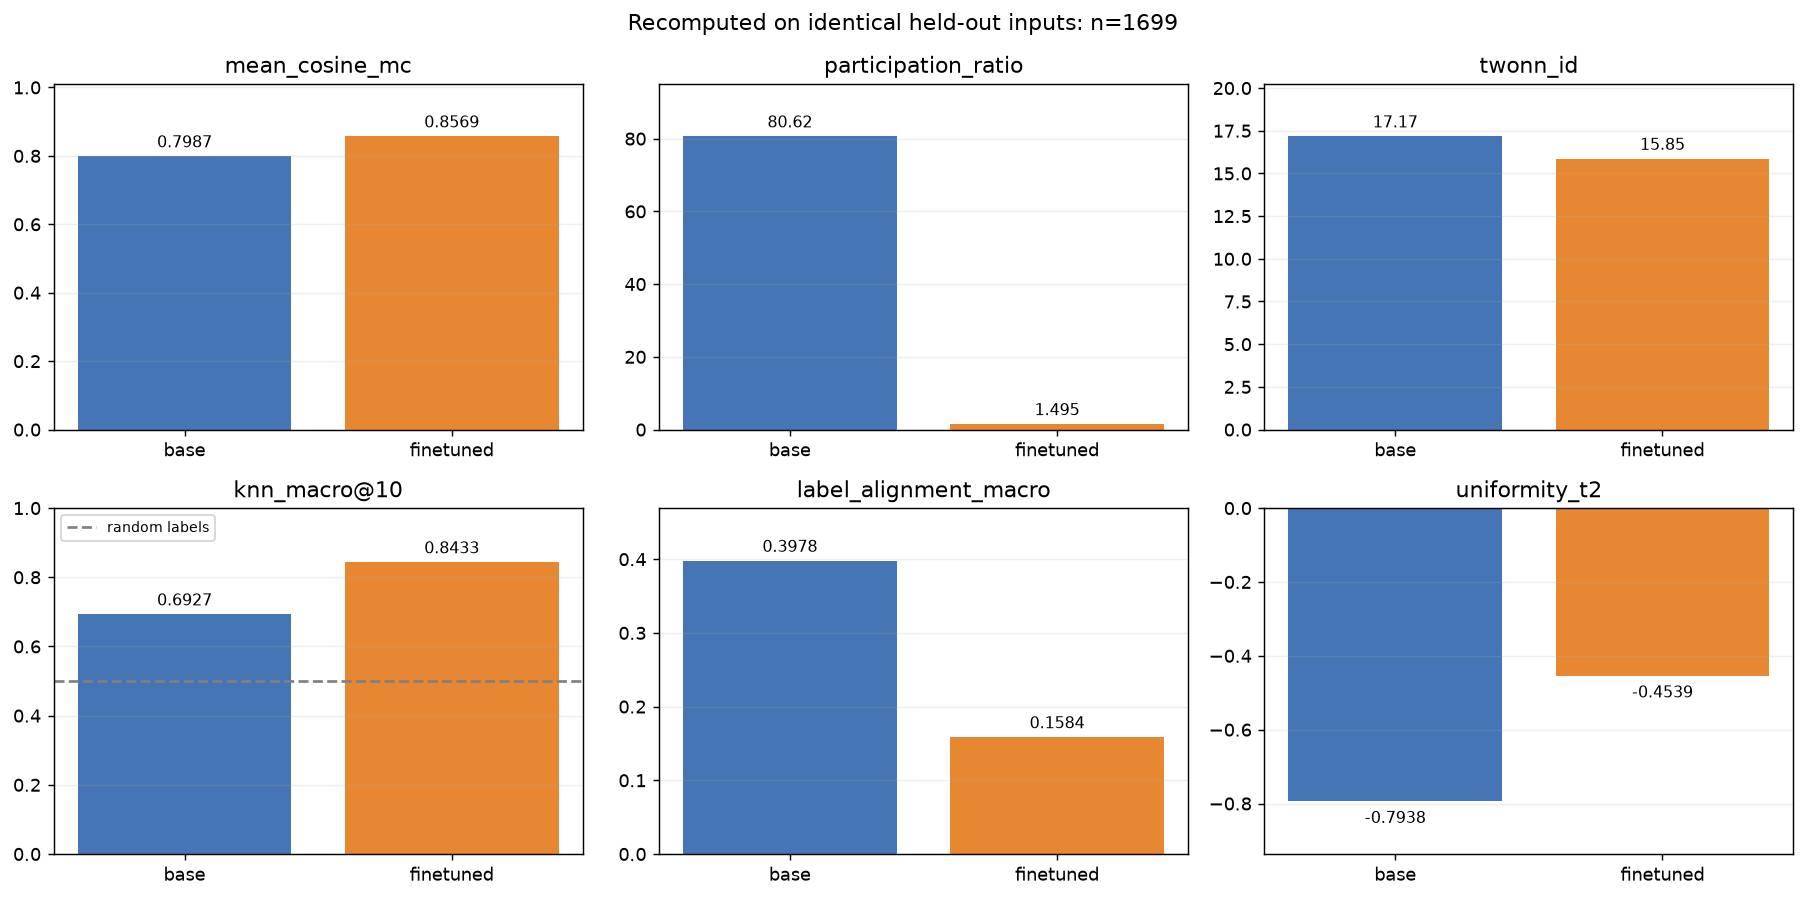

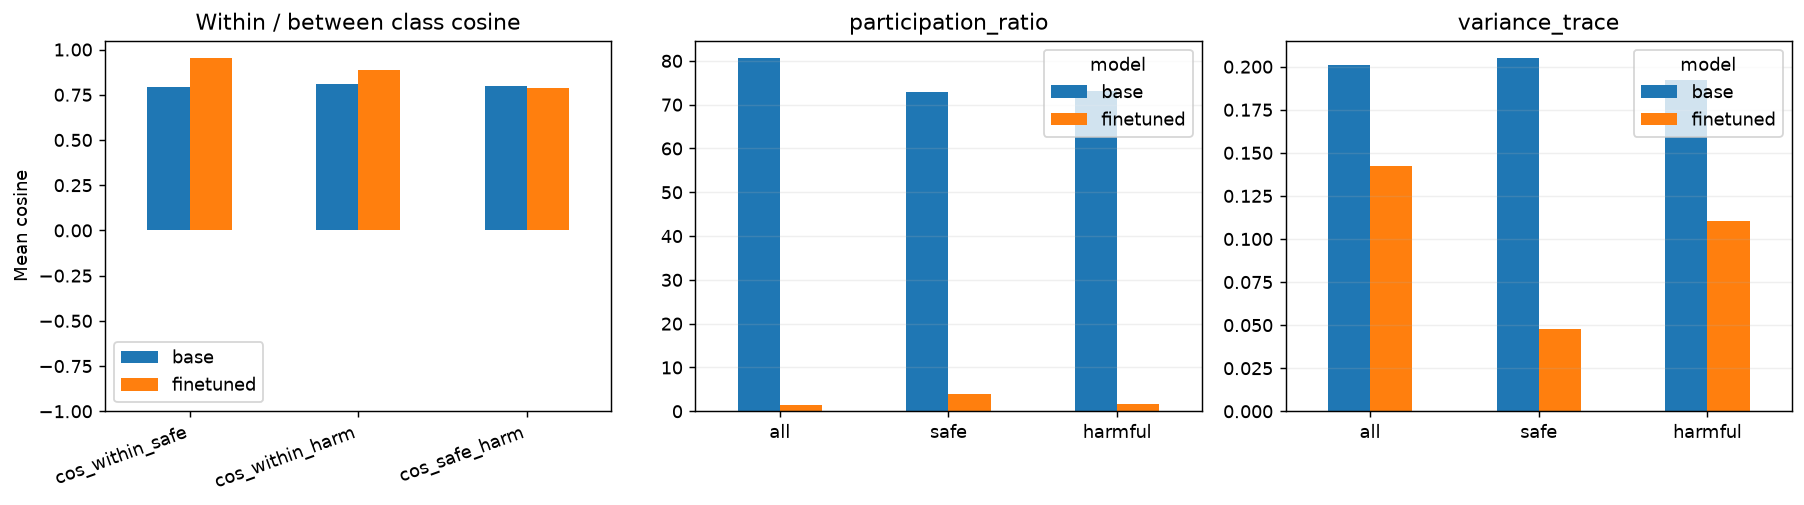

In [12]:
# Шесть выбранных метрик: отдельная шкала для каждой, без общего «рейтинга геометрии».
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, metric in zip(axes.flat, ["mean_cosine_mc", "participation_ratio", "twonn_id",
                                 "knn_macro@10", "label_alignment_macro", "uniformity_t2"]):
    values = comparison.loc[metric, ["base", "finetuned"]]
    ax.bar(values.index, values.values, color=["#4575b4", "#e88732"])
    ax.set(title=metric)
    ax.grid(axis="y", alpha=0.2)
    if metric == "knn_macro@10":
        ax.axhline(results["base"][1].set_index("k").loc[10, "null_macro"], color="grey", linestyle="--", label="random labels")
        ax.set_ylim(0, 1)
        ax.legend(fontsize=8)
    for i, value in enumerate(values):
        if np.isfinite(value):
            ax.annotate(f"{value:.4g}", (i, value), xytext=(0, 5 if value >= 0 else -12),
                        textcoords="offset points", ha="center", fontsize=9)
        else:
            ax.text(i, 0, "undefined", ha="center")
    if metric != "knn_macro@10":
        ax.margins(y=0.18)
fig.suptitle(f"Recomputed on identical held-out inputs: n={len(y)}")
fig.tight_layout()
fig.savefig(RUN / "geometry_metrics_before_after.png", dpi=160)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
comparison.loc[["cos_within_safe", "cos_within_harm", "cos_safe_harm"], ["base", "finetuned"]].plot.bar(ax=axes[0])
axes[0].set(title="Within / between class cosine", ylabel="Mean cosine", ylim=(-1, 1.05))
axes[0].tick_params(axis="x", labelrotation=20)
for label in axes[0].get_xticklabels(): label.set_ha("right")
for ax, metric in zip(axes[1:], ["participation_ratio", "variance_trace"]):
    geometry_table.pivot(index="group", columns="model", values=metric).loc[["all", "safe", "harmful"]].plot.bar(ax=ax)
    ax.set(title=metric, xlabel="")
    ax.tick_params(axis="x", labelrotation=0)
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(RUN / "class_geometry_before_after.png", dpi=160)
plt.show()
plt.close(fig)

## 5a. Почему k=10: чувствительность kNN-purity к числу соседей

`k=10` — понятный масштаб **локального соседства**, а не оптимальное число,
найденное из результатов. На 1699 текстах десять соседей — около 0,6% выборки.
Малое k сильнее зависит от отдельных соседей; большое k постепенно смешивает
более далёкие области пространства. Поэтому одного значения мало для вывода.

Ниже считаем **все k от 1 до 100** на одних и тех же эмбеддингах и метках.
Для каждого k доступны macro, micro и показатели safe/harmful. `macro` даёт классам
равный вес, `micro` усредняет по всем текстам. Главный вывод проверяем на разумном
диапазоне k, а не выбираем k, на котором различие выглядит максимальным.

Статичный PNG подходит для защиты; HTML с ползунком позволяет рассмотреть точные
значения. Оба файла и CSV войдут в итоговый ZIP. При нехватке времени показывайте
график с отметками k=5,10,20 и объясняйте, совпадает ли направление изменений.

Чувствительность к k: те же тексты, эмбеддинги и метки; одна модель для всей кривой.
Интерактивный HTML с ползунком: guardrails_geometry_results/run_20261018T134157_442709Z/knn_purity_vs_k.html
Откройте HTML из итогового ZIP; статичный график уже показан выше и включён в ZIP.


,k,base_macro,finetuned_macro,delta_macro,base_micro,finetuned_micro
0,1,0.7767,0.8616,0.0848,0.7728,0.8646
4,5,0.7207,0.8453,0.1246,0.7149,0.8484
9,10,0.6927,0.8433,0.1505,0.6859,0.8466
19,20,0.6646,0.8364,0.1718,0.6578,0.8406
49,50,0.6222,0.8307,0.2085,0.6159,0.8358
99,100,0.5929,0.8276,0.2347,0.5875,0.8333


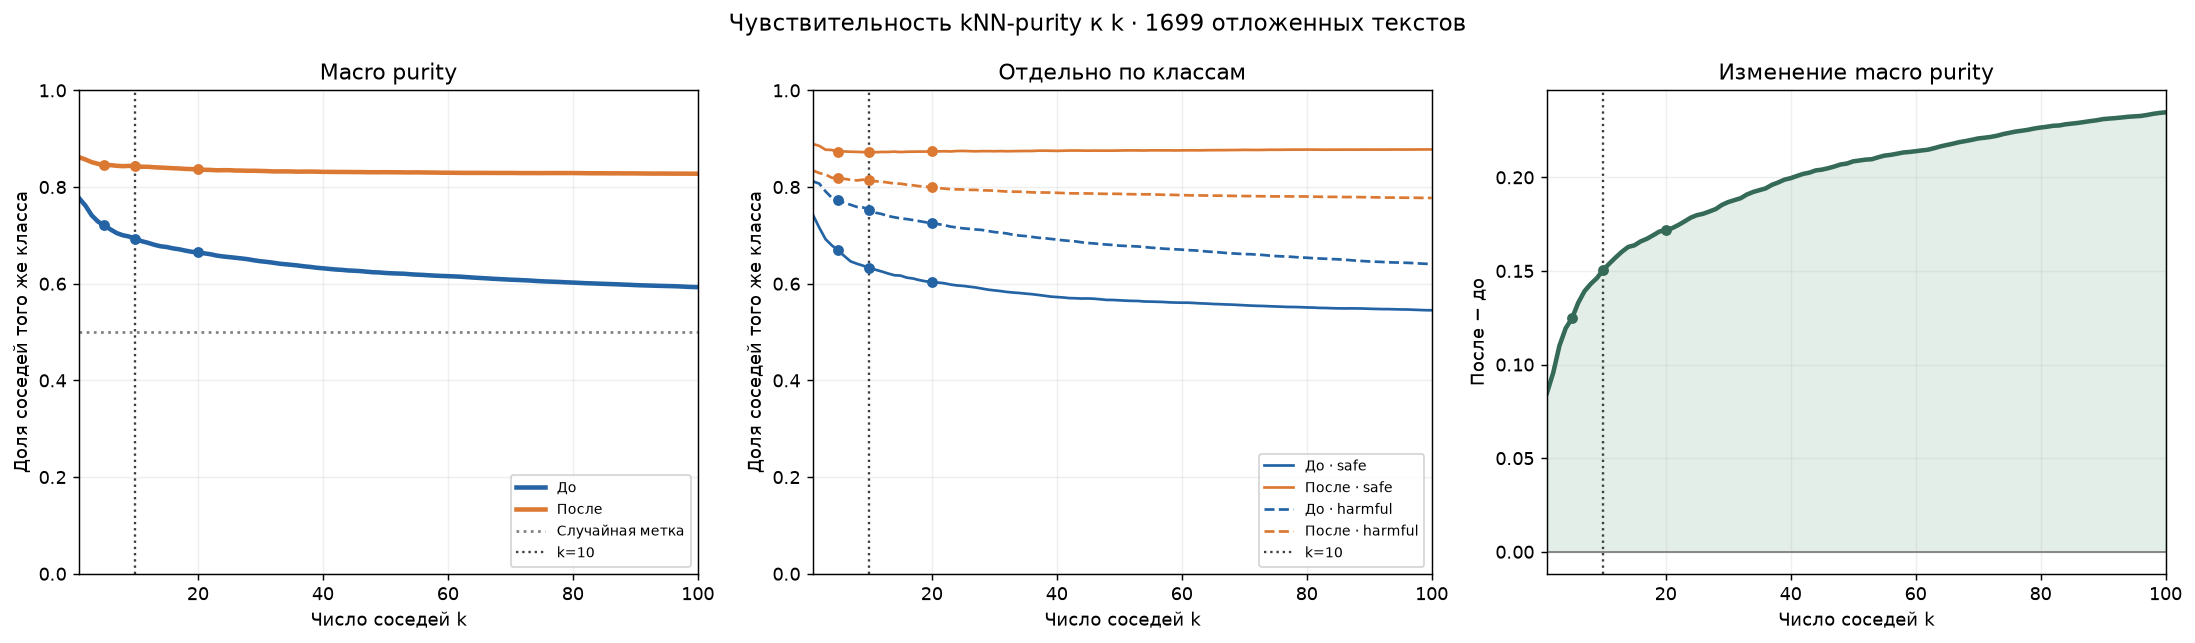

In [13]:
import json
from io import StringIO
from IPython.display import HTML, display
import re

K_MAX = min(100, len(y) - 1)
k_values = np.arange(1, K_MAX + 1)
curve = pd.DataFrame({"k": k_values})
for name, U in representations.items():
    ids, _ = neighbors(U, K_MAX)
    same_label = (y[ids] == y[:, None]).astype(np.float64)
    per_text = np.cumsum(same_label, axis=1) / k_values[None, :]
    curve[f"{name}_safe"] = per_text[y == 0].mean(axis=0)
    curve[f"{name}_harmful"] = per_text[y == 1].mean(axis=0)
    curve[f"{name}_macro"] = (curve[f"{name}_safe"] + curve[f"{name}_harmful"]) / 2
    curve[f"{name}_micro"] = per_text.mean(axis=0)
    for old in results[name][1].itertuples(index=False):
        assert np.isclose(curve.loc[curve.k == old.k, f"{name}_macro"].iloc[0], old.macro), (
            name, old.k, "Поиск соседей не совпал с основным расчётом")
curve["delta_macro"] = curve.finetuned_macro - curve.base_macro
curve["null_macro"] = results["base"][1].set_index("k").loc[10, "null_macro"]
curve.to_csv(RUN / "knn_purity_vs_k.csv", index=False)

print("Чувствительность к k: те же тексты, эмбеддинги и метки; одна модель для всей кривой.")
display(curve.loc[curve.k.isin([1, 5, 10, 20, 50, K_MAX]),
                  ["k", "base_macro", "finetuned_macro", "delta_macro", "base_micro", "finetuned_micro"]].round(4))
base_color, tuned_color = "#2463a4", "#db7832"
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(curve.k, curve.base_macro, color=base_color, linewidth=2.5, label="До")
axes[0].plot(curve.k, curve.finetuned_macro, color=tuned_color, linewidth=2.5, label="После")
axes[0].axhline(curve.null_macro.iloc[0], color="grey", linestyle=":", label="Случайная метка")
axes[0].set(title="Macro purity", ylabel="Доля соседей того же класса", ylim=(0, 1))
for group, style, label in [("safe", "-", "safe"), ("harmful", "--", "harmful")]:
    axes[1].plot(curve.k, curve[f"base_{group}"], color=base_color, linestyle=style, label=f"До · {label}")
    axes[1].plot(curve.k, curve[f"finetuned_{group}"], color=tuned_color, linestyle=style, label=f"После · {label}")
axes[1].set(title="Отдельно по классам", ylabel="Доля соседей того же класса", ylim=(0, 1))
axes[2].plot(curve.k, curve.delta_macro, color="#346a57", linewidth=2.5)
axes[2].fill_between(curve.k, 0, curve.delta_macro, color="#6eaa8a", alpha=0.2)
axes[2].axhline(0, color="grey", linewidth=1)
axes[2].set(title="Изменение macro purity", ylabel="После − до")
for ax in axes:
    ax.set(xlabel="Число соседей k", xlim=(1, K_MAX))
    ax.axvline(10, color="#3c4043", linewidth=1.3, linestyle=":", label="k=10")
    for selected in [5, 10, 20]:
        if selected <= K_MAX:
            columns = ("base_macro", "finetuned_macro") if ax is axes[0] else (
                ("base_safe", "finetuned_safe", "base_harmful", "finetuned_harmful") if ax is axes[1] else ("delta_macro",))
            for column in columns:
                color = (base_color if column.startswith("base") else tuned_color) if ax is not axes[2] else "#346a57"
                ax.scatter(selected, curve.loc[selected - 1, column], s=25, color=color, zorder=4)
    ax.grid(alpha=0.2)
axes[0].legend(loc="lower right", fontsize=8)
axes[1].legend(loc="lower right", fontsize=8)
fig.suptitle(f"Чувствительность kNN-purity к k · {len(y)} отложенных текстов", fontsize=13)
fig.tight_layout()
fig.savefig(RUN / "knn_purity_vs_k.png", dpi=170)
plt.show()

# Встроенный SVG и значения в одном HTML: ползунок работает без Python и без сети.
svg_buffer = StringIO()
fig.savefig(svg_buffer, format="svg")
positions = [ax.get_position() for ax in axes]
plt.close(fig)
inline_svg = re.sub(r"^.*?(?=<svg\b)", "", svg_buffer.getvalue(), flags=re.S)
cursor_html = "".join(
    f'<span class="cursor" data-left="{p.x0}" data-width="{p.width}" '
    f'style="top:{100 * (1-p.y1):.5f}%;height:{100*p.height:.5f}%"></span>'
    for p in positions)
rows_json = json.dumps(curve.round(6).to_dict("records"), ensure_ascii=False)
html = """<!doctype html><html lang="ru"><meta charset="utf-8"><meta name="viewport" content="width=device-width">
<title>Чувствительность kNN-purity к k</title><style>
body{font:16px system-ui,sans-serif;max-width:1500px;margin:24px auto;padding:0 18px;color:#20242a;background:#fafbfc}
h1{font-size:1.6rem}p{line-height:1.45}.controls{background:white;border:1px solid #dae1e8;border-radius:12px;padding:18px}
input{width:100%;accent-color:#346a57}.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:10px;margin-top:14px}
.card{border:1px solid #dae1e8;border-radius:9px;padding:12px;background:#f6f8fa}.card strong{font-size:1.35rem;display:block;margin-top:4px}
.figure{position:relative;margin-top:16px;background:white;border:1px solid #dae1e8;border-radius:12px;padding:6px}
.figure svg{width:100%;height:auto;display:block}.cursor{position:absolute;width:2px;background:#3c4043;opacity:.7;pointer-events:none}
</style><h1>Сколько соседей брать для kNN-purity?</h1>
<p>Все k от 1 до 100 на одних и тех же 1699 отложенных текстах. k=10 выделен как локальный ориентир; ползунок показывает значения для любого k. До/после сравниваются при одинаковом k.</p>
<div class="controls"><label for="k">Число соседей: <strong id="kval">10</strong></label><input id="k" type="range" min="1" max="100" value="10">
<div class="cards"><div class="card">Macro до<strong id="before"></strong></div><div class="card">Macro после<strong id="after"></strong></div>
<div class="card">Изменение<strong id="delta"></strong></div><div class="card">Micro до / после<strong id="micro"></strong></div>
<div class="card">Safe до / после<strong id="safe"></strong></div><div class="card">Harmful до / после<strong id="harmful"></strong></div></div></div>
<div class="figure">""" + inline_svg + cursor_html + """</div>
<p>Macro усредняет два класса поровну; micro усредняет все тексты. Purity измеряет долю соседей того же класса, не accuracy классификатора.</p>
<script>const rows=""" + rows_json + """;const slider=document.getElementById("k");
function fmt(v){return Number(v).toFixed(3)};function update(){const k=Number(slider.value),r=rows[k-1];
document.getElementById("kval").textContent=k;
for(const [id,value] of Object.entries({before:fmt(r.base_macro),after:fmt(r.finetuned_macro),delta:(r.delta_macro>=0?"+":"")+fmt(r.delta_macro),micro:fmt(r.base_micro)+" / "+fmt(r.finetuned_micro),safe:fmt(r.base_safe)+" / "+fmt(r.finetuned_safe),harmful:fmt(r.base_harmful)+" / "+fmt(r.finetuned_harmful)}))document.getElementById(id).textContent=value;
for(const cursor of document.querySelectorAll(".cursor")){const left=Number(cursor.dataset.left),width=Number(cursor.dataset.width);cursor.style.left=(100*(left+width*(k-1)/(rows.length-1)))+"%"}}
slider.addEventListener("input",update);update();</script></html>"""
html_path = RUN / "knn_purity_vs_k.html"
html_path.write_text(html, encoding="utf-8")
print("Интерактивный HTML с ползунком:", html_path)
print("Откройте HTML из итогового ZIP; статичный график уже показан выше и включён в ZIP.")

Диагностика конечной модели: проверяем PR и разброс отдельно в каждом классе. Порог `REVIEW_RATIO` задан заранее в конфигурации и означает повод для проверки, а не установленную поломку.

In [14]:
before_groups = results["base"][0].set_index("group")
after_groups = results["finetuned"][0].set_index("group")
diagnostic_rows = []
for group in ["safe", "harmful"]:
    row = {"group": group}
    for metric in ["participation_ratio", "variance_trace"]:
        before, after = before_groups.loc[group, metric], after_groups.loc[group, metric]
        row[metric + "_before"] = before
        row[metric + "_after"] = after
        row[metric + "_ratio"] = after / before if before > 1e-15 else np.nan
    row["review_flag"] = bool(row["participation_ratio_ratio"] < REVIEW_RATIO and
                              row["variance_trace_ratio"] < REVIEW_RATIO)
    diagnostic_rows.append(row)
endpoint_diagnostics = pd.DataFrame(diagnostic_rows)
display(endpoint_diagnostics.round(5))
endpoint_diagnostics.to_csv(RUN / "endpoint_diagnostics.csv", index=False)
change_status = dict(review_ratio=REVIEW_RATIO, flagged_classes=endpoint_diagnostics.loc[
    endpoint_diagnostics.review_flag, "group"].tolist(),
    first_change_step=None, loss_at_first_change=None,
    published_model_step=FINAL["step"],
    reason="Only endpoint weights; archive batch cosines cannot reconstruct held-out geometry over time.")
(RUN / "change_timing_status.json").write_text(json.dumps(change_status, ensure_ascii=False, indent=2))
if change_status["flagged_classes"]:
    print("Сигнал сжатия по выбранному порогу у сохранённой модели:", change_status["flagged_classes"])
else:
    print("Совместный порог PR и trace у конечной модели не пересечён; это не проверка сохранения всей семантики.")
print("Шаг возникновения изменения и loss в этот момент: не установлены.")
print("Диагностический флаг сам по себе не доказывает вред: нужен независимый тест качества/семантики.")
for metric in ["knn_macro@10", "participation_ratio", "twonn_id", "label_alignment_macro", "uniformity_t2"]:
    print(f"{metric}: {comparison.loc[metric, 'base']:.4f} → {comparison.loc[metric, 'finetuned']:.4f}")
print("PR описывает концентрацию дисперсии, а TwoNN — локальную размерность: их изменения могут различаться.")
print("Рост purity и уменьшение alignment показывают организацию по safety-метке; сохранность общей семантики здесь не измерена.")

# Проверка согласованности с архивом; совпадение агрегатов не доказывает идентичность весов.
if ("archive_geometry" in globals() and DATA_SOURCE == "wildguard" and len(y) == 1699 and
    FINAL.get("cached_repo", FINAL["source"]) == "pineee/e5-small-v2-hivetrace-finetune-CE-SupCon"):
    rows = []
    for name, archived_name in [("base", "e5-small-v2-frozen"), ("finetuned", "pure-supcon-joint")]:
        old = archive_geometry.loc[(archive_geometry.model == archived_name) &
                                   (archive_geometry.eval_set == "holdout")].iloc[0]
        for metric in ["cos_within_safe", "cos_within_harm", "cos_safe_harm", "pc1_share"]:
            value = comparison.loc[metric, name]
            rows.append(dict(model=name, metric=metric, recomputed=value, archive_rounded=old[metric],
                             difference=value - old[metric], agrees_to_4_decimals=abs(value - old[metric]) <= 0.00005))
    archive_agreement = pd.DataFrame(rows)
    display(archive_agreement.round(6))
    archive_agreement.to_csv(RUN / "recomputed_vs_archive.csv", index=False)
    print("Совпадение с округлённым логом:", bool(archive_agreement.agrees_to_4_decimals.all()),
          "— проверка чисел, не подтверждение происхождения чекпоинта.")

Сигнал сжатия по выбранному порогу у сохранённой модели: ['safe']
Шаг возникновения изменения и loss в этот момент: не установлены.
Диагностический флаг сам по себе не доказывает вред: нужен независимый тест качества/семантики.
knn_macro@10: 0.6927 → 0.8433
participation_ratio: 80.6172 → 1.4951
twonn_id: 17.1674 → 15.8528
label_alignment_macro: 0.3978 → 0.1584
uniformity_t2: -0.7938 → -0.4539
PR описывает концентрацию дисперсии, а TwoNN — локальную размерность: их изменения могут различаться.
Рост purity и уменьшение alignment показывают организацию по safety-метке; сохранность общей семантики здесь не измерена.
Совпадение с округлённым логом: True — проверка чисел, не подтверждение происхождения чекпоинта.


,group,participation_ratio_before,participation_ratio_after,participation_ratio_ratio,variance_trace_before,variance_trace_after,variance_trace_ratio,review_flag
0,safe,72.78854,3.91012,0.05372,0.20494,0.04798,0.23410,True
1,harmful,73.08080,1.76779,0.02419,0.19235,0.11026,0.57322,False


,model,metric,recomputed,archive_rounded,difference,agrees_to_4_decimals
0,base,cos_within_safe,0.794840,0.7948,0.000040,True
1,base,cos_within_harm,0.807393,0.8074,-0.000007,True
2,base,cos_safe_harm,0.797773,0.7978,-0.000027,True
3,base,pc1_share,0.070680,0.0707,-0.000020,True
4,finetuned,cos_within_safe,0.951973,0.9520,-0.000027,True
5,finetuned,cos_within_harm,0.889594,0.8896,-0.000006,True
6,finetuned,cos_safe_harm,0.785145,0.7851,0.000045,True
7,finetuned,pc1_share,0.817575,0.8176,-0.000025,True


## 6. Что писать в выводах

1. **Общая направленность:** на сколько изменился средний косинус, согласуется ли это со спектром и uniformity? Высокий косинус сам по себе не означает поломку E5.
2. **Safety-структура:** выросла ли macro purity выше случайного уровня и уменьшился ли label-alignment? Это показывает организацию по safety-метке, но не сохранение общей семантики.
3. **Внутриклассовое разнообразие:** что произошло с PR, TwoNN и `variance_trace` отдельно в safe/harmful? Падение PR и разброса при высокой purity — повод проверить сжатие классов. Малый trace при большом PR тоже возможен: разнообразие осталось лишь в слабом шуме.
4. **Граница вывода:** по трём наборам весов видны различия между исходной, CE и CE+SupCon моделями. Это отдельные конечные точки, а не последовательные чекпоинты одного обучения. Логи дают loss по шагам и шаг выбора архивной модели. Но по двум наборам весов нельзя определить шаг возникновения геометрического изменения или loss именно в этот момент; контроль CE позволяет описать разницу двух обученных моделей, но не даёт строгой причинной оценки вклада SupCon: нужны подтверждённо одинаковые данные, условия обучения и несколько seed. Здесь нет утверждения «геометрия сломалась» по одному числу. Чтобы назвать изменение вредным, дополнительно проверьте нужное downstream-качество; для сохранения семантики нужен отдельный semantic similarity/retrieval тест.

Все CSV, график, входы, индексы пар, raw-эмбеддинги и manifest сохраняются в `RUN`. Таблица — описание фиксированной выборки, не оценка вариативности разных обучений.

## Контроль: опубликованный CE-чекпоинт

`pineee/e5-small-v2-hivetrace-finetune-CE` уже опубликован с весами энкодера и
классификационной головы. Для геометрии берём только энкодер и используем те же
`eval_inputs`, токенизатор, mean pooling, L2-нормировку, метки и пары, что выше.
Проверяем совпадение token IDs. Три колонки показывают base, CE и CE+SupCon;
разности CE−base и (CE+SupCon)−CE описывают эти сохранённые модели.

Карточки сообщают одинаковую базовую модель, WildGuardMix train, 43 025 текстов,
2 эпохи, batch 32 и один seed. Этого недостаточно для строгого вывода о причинном
эффекте SupCon: соответствие конкретных HF-весов архивным прогонам и полное
совпадение всех условий обучения отдельно не подтверждены. Сравнение не показывает
момент изменения геометрии в ходе обучения.


In [15]:
CE = dict(name="ce", source="pineee/e5-small-v2-hivetrace-finetune-CE",
          revision="7c86195053050b63ef4330d45db15ad9dd473265", step=None)
LOCAL_CE = Path(".verification/rq4_ce")
if DEVICE == "cpu" and (LOCAL_CE / "model.safetensors").exists():
    CE.update(cached_repo=CE["source"], cached_revision=CE["revision"],
              source=str(LOCAL_CE), revision=None)

# Проверяем реальные входы даже при загрузке CE из локальной папки.
ce_tokenizer = AutoTokenizer.from_pretrained(CE["source"], revision=CE["revision"])
ce_hashes = []
for start in range(0, len(texts), 256):
    token_ids = ce_tokenizer(texts[start:start + 256], truncation=True,
                             max_length=MAX_LENGTH)["input_ids"]
    ce_hashes.extend(digest(ids) for ids in token_ids)
assert ce_hashes == df["token_hash"].tolist(), "CE-токенизатор даёт другие token IDs."

ce_raw, model_identities["ce"] = encode(CE)
representations["ce"] = normalize(ce_raw)
np.savez_compressed(RUN / "ce_embeddings.npz", raw=ce_raw, labels=y,
                    row_ids=df["row_id"].to_numpy(dtype=str))
del ce_raw
results["ce"] = evaluate(representations["ce"])

model_order = ["base", "ce", "finetuned"]
three_way = pd.DataFrame({name: summary(results[name]) for name in model_order})
three_way["ce_minus_base"] = three_way["ce"] - three_way["base"]
three_way["joint_minus_ce"] = three_way["finetuned"] - three_way["ce"]
three_way.to_csv(RUN / "three_way_comparison.csv", index_label="metric")
three_way_geometry = pd.concat([results[name][0].assign(model=name) for name in model_order], ignore_index=True)
three_way_purity = pd.concat([results[name][1].assign(model=name) for name in model_order], ignore_index=True)
three_way_geometry.to_csv(RUN / "three_way_geometry_by_class.csv", index=False)
three_way_purity.to_csv(RUN / "three_way_knn_purity.csv", index=False)
display(three_way.round(5))
display(three_way_geometry[["model", "group", "n", "mean_cosine_exact", "pc1_share",
                            "participation_ratio", "variance_trace", "twonn_id",
                            "twonn_invalid_fraction"]].round(5))
display(three_way_purity.round(4))
print("CE source:", model_identities["ce"])
if "archive_geometry" in globals() and DATA_SOURCE == "wildguard" and len(y) == 1699:
    archived_ce = archive_geometry.loc[(archive_geometry.model == "pure-classification") &
                                       (archive_geometry.eval_set == "holdout")].iloc[0]
    ce_agreement = pd.DataFrame([
        dict(metric=metric, recomputed=three_way.loc[metric, "ce"],
             archive_rounded=archived_ce[metric],
             difference=three_way.loc[metric, "ce"] - archived_ce[metric])
        for metric in ["pc1_share", "cos_safe_harm", "cos_within_safe", "cos_within_harm"]
    ])
    ce_agreement["agrees_to_4_decimals"] = ce_agreement.difference.abs() <= 0.00005
    ce_agreement.to_csv(RUN / "ce_vs_archive.csv", index=False)
    display(ce_agreement.round(6))
    print("Совпадение с округлённым архивом:", bool(ce_agreement.agrees_to_4_decimals.all()),
          "— числовая проверка, не доказательство происхождения весов.")


ce — кэш dbb1aeecbb6974e7f0e163464f475f2adf321548fc841b27f9a73cfcd0b90653.npz
CE source: {'path': '/Users/slvic/ANYA/NLP_1_HW2_BERT/.verification/rq4_ce', 'sha256': '900381e39b7cc88c96038737f4a0b543710f4fff55b34391a16fdf8dcb684b46', 'cached_repo': 'pineee/e5-small-v2-hivetrace-finetune-CE', 'cached_revision': '7c86195053050b63ef4330d45db15ad9dd473265'}
Совпадение с округлённым архивом: True — числовая проверка, не доказательство происхождения весов.


,base,ce,finetuned,ce_minus_base,joint_minus_ce
mean_cosine_mc,0.79872,0.25154,0.85688,-0.54718,0.60535
mean_cosine_exact,0.79876,0.25311,0.85729,-0.54565,0.60418
participation_ratio,80.61720,2.38181,1.49506,-78.23539,-0.88674
pc1_share,0.07068,0.64547,0.81758,0.57479,0.17211
variance_trace,0.20112,0.74645,0.14263,0.54533,-0.60382
twonn_id,17.16736,15.60611,15.85279,-1.56124,0.24668
uniformity_t2,-0.79379,-1.63407,-0.45395,-0.84028,1.18012
cos_within_safe,0.79484,0.62456,0.95197,-0.17028,0.32742
cos_within_harm,0.80739,0.40378,0.88959,-0.40362,0.48582
cos_safe_harm,0.79777,-0.03944,0.78515,-0.83721,0.82458


,model,group,n,mean_cosine_exact,pc1_share,participation_ratio,variance_trace,twonn_id,twonn_invalid_fraction
0,base,all,1699,0.79876,0.07068,80.61720,0.20112,17.16736,0.0
1,base,safe,945,0.79484,0.07336,72.78854,0.20494,15.10359,0.0
2,base,harmful,754,0.80739,0.06965,73.08080,0.19235,20.52927,0.0
3,ce,all,1699,0.25311,0.64547,2.38181,0.74645,15.60611,0.0
4,ce,safe,945,0.62456,0.34487,7.86782,0.37505,13.57500,0.0
5,ce,harmful,754,0.40378,0.55253,3.20523,0.59543,17.50158,0.0
6,finetuned,all,1699,0.85729,0.81758,1.49506,0.14263,15.85279,0.0
7,finetuned,safe,945,0.95197,0.50247,3.91012,0.04798,12.97358,0.0
8,finetuned,harmful,754,0.88959,0.75146,1.76779,0.11026,20.53772,0.0


,k,macro,safe,harmful,null_macro,excess_macro,model
0,5,0.7207,0.6688,0.7727,0.4997,0.2210,base
1,10,0.6927,0.6323,0.7532,0.4997,0.1930,base
2,20,0.6646,0.6039,0.7253,0.4997,0.1649,base
3,5,0.8477,0.8796,0.8159,0.4997,0.3480,ce
4,10,0.8442,0.8821,0.8062,0.4997,0.3445,ce
5,20,0.8396,0.8857,0.7936,0.4997,0.3399,ce
6,5,0.8453,0.8724,0.8183,0.4997,0.3456,finetuned
7,10,0.8433,0.8726,0.8139,0.4997,0.3436,finetuned
8,20,0.8364,0.8736,0.7991,0.4997,0.3367,finetuned


,metric,recomputed,archive_rounded,difference,agrees_to_4_decimals
0,pc1_share,0.645468,0.6455,-0.000032,True
1,cos_safe_harm,-0.039439,-0.0394,-0.000039,True
2,cos_within_safe,0.624557,0.6246,-0.000043,True
3,cos_within_harm,0.403776,0.4038,-0.000024,True


In [16]:
manifest = dict(created_utc=datetime.now(timezone.utc).isoformat(), data=data_source,
                data_hash=DATA_HASH, audit=audit, models=model_identities, versions=VERSIONS,
                seed=SEED, max_length=MAX_LENGTH, initial_batch_size=BATCH_SIZE, n_pairs=N_PAIRS,
                knn_k=list(KS), twonn_discard=TWONN_DISCARD, tokenizer_hash=TOKENIZER_HASH,
                inference="FP32/eval/masked mean/last layer", geometry="L2 normalized, float64",
                device=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
                checkpoint_loss_family=LOSS_FAMILY, review_ratio=REVIEW_RATIO)
(RUN / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
report = ["RQ4: E5 base, CE, CE + SupCon", f"n={len(y)}; data_hash={DATA_HASH}",
          three_way.to_string(float_format=lambda x: f"{x:.6f}"),
          "Descriptive results on one fixed sample; no training-seed confidence intervals.",
          "Three independently published endpoints do not identify the onset step/loss of a geometry change or a causal teacher effect. Archive steps/loss are reported separately; HF-to-run identity is unverified."]
(RUN / "summary.txt").write_text("\n\n".join(report))
print("Сохранено:", RUN)
print("Перед отключением GPU выполните последнюю ячейку сохранения ZIP, особенно при работе без Drive.")

Сохранено: guardrails_geometry_results/run_20261018T134157_442709Z
Перед отключением GPU выполните последнюю ячейку сохранения ZIP, особенно при работе без Drive.



## 7. На каком шаге и при каком loss изменилась геометрия

**Текущий статус:** в архиве есть train loss и обучающие косинусы по шагам, валидационные
метрики и номер лучшего чекпоинта. Нет промежуточных весов, эмбеддингов фиксированного
набора по шагам, val loss и истории PR/TwoNN/kNN/uniformity. Поэтому шаг «поломки»
и loss в момент её возникновения **не установлены**. Шаг 1400 — выбор лучшей архивной
CE+SupCon по валидации, не доказанный момент изменения геометрии.

Два набора весов позволяют проверить изменение относительно base. Если диагностический
флаг есть у сохранённой модели, он наблюдается на этой конечной точке; первый момент
его возникновения мог быть раньше. До подтверждения соответствия HF-весов архивному
прогону не присваиваем им step=1400 автоматически.

При наличии реальных промежуточных весов заполните `CHECKPOINTS`, `FINAL["step"]`
и `LOSS_CSV`. Все веса и логи должны принадлежать одному запуску. Поддерживаются
`loss_total/loss_ce/loss_supcon` и названия из архива `loss/train_loss_ce/train_loss_supcon`.
Соединение с loss — только по точному step; в конце эпохи ближайшая запись
`train_loss_at_step` не считается loss на шаге валидации. Сохраняйте веса компонент,
temperature и способ усреднения. Архивные числа loss относятся к отдельным батчам.

Диагностический флаг: хотя бы в одном классе одновременно PR и trace ниже
`REVIEW_RATIO` от base. Это повод проверить сжатие, не универсальный критерий вреда.
При нескольких чекпоинтах сохраняется интервал между предыдущей проверкой и первым
обнаруженным флагом; это интервал первого обнаружения, а не доказательство отсутствия
более ранних кратковременных изменений. Для вывода о вреде нужен downstream/semantic тест.
В новом обучении сохраняйте веса или эмбеддинги **одних и тех же** отложенных текстов
вместе с loss каждые 100–200 шагов; повторный запуск будет новым экспериментом.


In [17]:
def trajectory_row(spec, result):
    frame = result[0].set_index("group")
    reference = results["base"][0].set_index("group")
    row = dict(model=spec["name"], step=spec["step"], loss_family=LOSS_FAMILY,
               **summary(result))
    flags = []
    for group in ["safe", "harmful"]:
        for metric in ["participation_ratio", "variance_trace"]:
            denominator = reference.loc[group, metric]
            row[f"{group}_{metric}_ratio"] = float(frame.loc[group, metric] / denominator) if denominator > 1e-15 else np.nan
        flags.append(row[f"{group}_participation_ratio_ratio"] < REVIEW_RATIO and
                     row[f"{group}_variance_trace_ratio"] < REVIEW_RATIO)
    row["review_flag"] = any(flags)
    return row

if CHECKPOINTS:
    assert all(s["name"] not in results for s in CHECKPOINTS), "Имена base и finetuned зарезервированы."
    specs = [BASE] + CHECKPOINTS + ([FINAL] if FINAL["step"] is not None else [])
    assert len({s["name"] for s in specs}) == len(specs), "Имена должны быть уникальны."
    assert all(isinstance(s["step"], int) and s["step"] >= 0 for s in specs)
    assert len({s["step"] for s in specs}) == len(specs), "Один checkpoint на каждый step."
    rows, checkpoint_identities = [], {}
    for spec in sorted(specs, key=lambda s: s["step"]):
        if spec["name"] in results:
            result = results[spec["name"]]
            identity = model_identities[spec["name"]]
        else:
            X, identity = encode(spec)
            result = evaluate(normalize(X))
        checkpoint_identities[spec["name"]] = identity
        rows.append(trajectory_row(spec, result))
    trajectory = pd.DataFrame(rows).sort_values("step")
    if LOSS_CSV is not None:
        logs = pd.read_csv(LOSS_CSV)
        aliases = {"loss": "loss_total", "train_loss_ce": "loss_ce", "train_loss_supcon": "loss_supcon"}
        logs = logs.rename(columns={old: new for old, new in aliases.items() if new not in logs})
        loss_columns = [c for c in ["loss_total", "loss_ce", "loss_supcon"] if c in logs]
        assert "step" in logs and loss_columns and not logs["step"].duplicated().any()
        trajectory = trajectory.merge(logs[["step"] + loss_columns], on="step", how="left", validate="one_to_one")
    trajectory["previous_saved_step"] = trajectory["step"].shift(1)
    trajectory.to_csv(RUN / "checkpoint_geometry_and_loss.csv", index=False)
    (RUN / "checkpoint_manifest.json").write_text(json.dumps(checkpoint_identities, indent=2))
    display(trajectory)
    flagged = trajectory.loc[trajectory["review_flag"]]
    if len(flagged):
        first = flagged.iloc[[0]]
        first.to_csv(RUN / "first_review_interval.csv", index=False)
        display(first)
        print("Первый сохранённый сигнал: проверьте интервал previous_saved_step → step; это не диагноз поломки.")
    else:
        print("На сохранённых шагах выбранный диагностический порог не пересечён.")
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    for ax, metric in zip(axes, ["participation_ratio", "knn_macro@10", "uniformity_t2"]):
        ax.plot(trajectory["step"], trajectory[metric], "o-")
        ax.set(xlabel="Optimizer step", ylabel=metric)
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(RUN / "checkpoint_trajectory.png", dpi=160)
    plt.show()
    plt.close(fig)
else:
    print("Промежуточных весов одной траектории нет: доступны три конечные модели и архивные обучающие показатели.")
    print("Архивный CE+SupCon сохранён на шаге 1400; момент возникновения геометрических изменений не установлен.")

Промежуточных весов одной траектории нет: доступны три конечные модели и архивные обучающие показатели.
Архивный CE+SupCon сохранён на шаге 1400; момент возникновения геометрических изменений не установлен.


## 8. RQ6: что здесь можно сказать о teacher signal

У текущей модели используется разметка WildGuardMix train, полученная с помощью GPT-4: это **LLM как источник меток** (hard-label supervision). Наличие soft targets, скрытых состояний teacher или отдельного distillation loss в карточке модели не заявлено. Геометрия base → fine-tuned показывает совместный эффект обучения на этих данных с CE + SupCon; отдельно эффект LLM-учителя она не выделяет.

Минимальный контролируемый план для RQ6:

| Разметка одинаковых train-текстов | CE | CE + SupCon |
|---|---|---|
| Человеческая | контроль | эффект SupCon при human signal |
| LLM | эффект teacher при CE | текущий тип модели |

Сравнивайте одинаковые train/validation/test IDs, budget optimizer steps, архитектуру, batch size и несколько seed (например 3). Подбирайте гиперпараметры на validation, итог оценивайте на независимой человеческой разметке. Если нет human-меток **для тех же train-текстов**, такая таблица пока остаётся планом: сравнение разных корпусов смешивает teacher с изменением данных. Опубликованный CE-only теперь позволяет описательно сравнить три точки (base, CE, CE+SupCon) на одних тестовых текстах. Разница двух обученных моделей относится к схеме loss, а не к пользе LLM-учителя; для причинного вывода нужны подтверждённо совпадающие условия обучения и несколько seed.

Имеющиеся вычислительные блоки разумно оставить для этих контролей после первого RQ4-прогона; повторное обучение здесь автоматически не запускается. Метрики из раздела 4 можно применить к каждому варианту и сохранённому шагу.

**Уточнение происхождения данных:** фраза в карточке fine-tuned модели об отсутствии synthetic data не означает, что исходный WildGuardMix целиком естественный: его [описание](https://huggingface.co/datasets/allenai/wildguardmix) включает синтетические запросы. Для отчёта лучше формулировать: «обучение на выбранных примерах WildGuardMix без дополнительных синтетических примеров», если это подтверждается вашим обучающим кодом.

**Что добавляет RQ3:** есть CE, InfoNCE, CE+InfoNCE, SupCon и CE+SupCon на одной
обучающей выборке с одним seed. Это сравнение функций потерь при фиксированном источнике
меток. Из-за выбора лучших весов на разных шагах это сравнение моделей, выбранных по
одному правилу, а не сравнение геометрии на одинаковом шаге.

**RQ6 пока не закрыт экспериментально.** Нельзя приписать изменения именно LLM-учителю
без контроля источника меток. Операциональная формулировка: «Как замена человеческих
меток на LLM-метки для тех же текстов влияет на геометрию и качество на независимом
тесте с человеческой разметкой при фиксированном objective?»
Первый отдельный контроль — human CE против LLM CE; затем повторить для CE+SupCon.
Для teacher сохраняйте название/версию модели, prompt, дату, режим генерации, обработку
неоднозначных ответов и долю расхождений с human. Пока эти данные отсутствуют,
разметку описываем по карточке WildGuardMix, не выдумываем параметры teacher.
Отчёт по RQ6 должен включать геометрию, качество и их вариативность по seed;
различия CE и CE+SupCon сами по себе отвечают на другой вопрос.


## Скачать результаты

Последняя ячейка собирает содержимое текущего `RUN` в ZIP: входы, эмбеддинги, CSV, графики и manifest, включая опциональный анализ чекпоинтов. В Colab без подключённого Drive она запускает скачивание. Дождитесь завершения скачивания перед удалением среды: [локальные файлы Colab хранятся на временной виртуальной машине](https://research.google.com/colaboratory/faq.html). Сам выполненный `.ipynb` скачайте отдельно через меню «Файл».

In [18]:
import shutil
if "ARCHIVE_OUT" in globals():
    shutil.copytree(ARCHIVE_OUT, RUN / "rq3_history", dirs_exist_ok=True)
archive_path = shutil.make_archive(str(RUN), "zip", root_dir=str(RUN))
print("Архив результатов:", archive_path)
if IN_COLAB and not DRIVE_READY:
    from google.colab import files
    files.download(archive_path)
print("После сохранения файлов можно отключить GPU-среду.")

Архив результатов: /Users/slvic/ANYA/NLP_1_HW2_BERT/guardrails_geometry_results/run_20261018T134157_442709Z.zip
После сохранения файлов можно отключить GPU-среду.
